# TP3 – Regularización en el clasificador de 20 Newsgroups

**Consigna.** Incluir como hiperparámetros del clasificador de TNG (20 Newsgroups) los elementos vistos en la clase de regularización: **L1 / L2 / L1+L2**, **Dropout** y **Batch Normalization**, y para cada uno tener en cuenta las recomendaciones de clase: **valores absolutos de los pesos**, **tiempos de entrenamiento**, **valores de learning rate** y **ruido en las curvas de aprendizaje**, justificando los fenómenos observados con lo visto en clase.

**Estructura del notebook**

| Sección | Contenido |
|---|---|
| 1 | Datos, preprocesamiento y TF-IDF (con escalado de features como hiperparámetro) |
| 2 | Modelo (`MLP` con dropout y BatchNorm opcionales), penalizaciones L1/L2, métricas de pesos / tiempos / ruido |
| 3 | Búsqueda de Optuna **con** regularización como hiperparámetros (L1, L2, L1+L2, dropout, BN) |
| 4 | Experimentos controlados (un factor por vez, 2 semillas): L2, L1, L1+L2, dropout (+ max-norm), BatchNorm, learning rate, profundidad, interacción dropout×BN y escalado de features |
| 5 | Búsqueda **sin** regularización con el mismo presupuesto (comparación justa) |
| 6 | Selección de épocas con validación, entrenamiento final y test (una sola vez por semilla) |
| 7 | Bias / varianza, conclusiones y limitaciones |

## Correcciones de TP1 y TP2 que se tuvieron en cuenta desde el principio

| Devolución previa | Cómo se resuelve acá |
|---|---|
| Análisis genérico, sin números ("suele", "usualmente") | **Todo el análisis se genera desde los resultados** con cifras; las afirmaciones se acompañan de la tabla que las sustenta |
| Curvas rotuladas "val" calculadas sobre test | Todas las curvas de dinámica usan un **split de validación** (el mismo que la búsqueda); el test se usa solo en la sección 6, **una vez por semilla** y sin decidir nada con él |
| TensorBoard / MLflow importados sin uso | Se **usan**: TensorBoard por trial y por corrida controlada (`runs/tp3`), MLflow para los estudios y las corridas controladas (`mlflow.db`) |
| Falta medir tiempos de convergencia | Tiempo por época (solo entrenamiento, sin vectorización) y **épocas / segundos hasta alcanzar el 97 % de la val acc de referencia**, con las cifras en el texto |
| Presupuesto asimétrico entre modelos comparados | Estudio con y sin regularización con **el mismo número de trials, sampler, pruner y épocas** (secciones 3 y 5) |
| `objective` con la val acc de la última época | El `objective` devuelve la val acc **en la época de mínima val loss** (early stopping sobre validación) y se registra también la última |
| Rangos de búsqueda muy amplios | lr `1e-4..1e-2` (SGD `1e-2..1`), λ L2 `1e-6..1e-3` (incluye 1e-4 visto en clase), λ L1 `1e-7..1e-4` |
| Weight decay aplicado a los bias; sin max-norm | La penalización L1/L2 se aplica **solo a las matrices de pesos** (nunca a bias ni a γ/β de BatchNorm); se incluye max-norm junto a dropout |
| Efecto de dropout / weight decay no aislado | Sección 4: **un factor por vez**, el resto fijo, con 2 semillas |
| Selección de épocas con test; épocas fijas | Sección 6: las épocas se eligen con **validación** y el entrenamiento final usa `val_loader=None` |
| Falta bias/varianza | Sección 7: brecha train(eval) − val de todas las configuraciones y techo de accuracy del dataset |
| *Lambda es el mismo para todos los pesos → importa preprocesar* (apunte) | `feature_scaling` es un hiperparámetro y tiene su experimento controlado (4.9) |
| README vacío, sin requirements, `.db` versionado, TPs mezclados | Ver `README.md`, `requirements.txt` y `.gitignore` del repo; este TP vive en `TP3_Regularizacion/` |

> **Cómo ejecutarlo:** *Run All*. Con CPU tarda del orden de **1.5–2 h** (con `N_TRIALS = 30`) (la mayor parte son las dos búsquedas y los experimentos controlados). Si se corta, **se puede volver a correr**: los estudios de Optuna son idempotentes (`tp3_study.db`) y cada corrida controlada se guarda en `results/tp3_corridas.jsonl`, así que se completa solo lo que falta. Para achicar el tiempo, bajar `N_TRIALS` y `CTRL_SEEDS` en la primera celda.

In [1]:
import os, re, math, time, json, random, hashlib
from functools import lru_cache
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import binomtest

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ---------------- Parámetros del experimento (bajarlos achica el tiempo de ejecución) ----------------
SEED = 42
N_TRIALS = 30          # presupuesto de CADA estudio de Optuna (con y sin regularización)
EPOCHS_SEARCH = 15     # épocas por trial
CTRL_EPOCHS = 15       # épocas de cada corrida controlada
CTRL_SEEDS = [0, 1]    # semillas de las corridas controladas
LR_SWEEP = [3e-4, 1e-3, 3e-3, 1e-2]
EPOCHS_SEL = 30        # corrida larga para elegir el número de épocas finales (con validación)
FINAL_SEEDS = [0, 1, 2, 3, 4]

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

# ---------------- Tracking: MLflow (SQLite local) y TensorBoard ----------------
mlflow.set_tracking_uri("sqlite:///mlflow.db")
TB_DIR = "runs/tp3"
for d in ("figures", "results"):
    os.makedirs(d, exist_ok=True)

nltk.download("stopwords"); nltk.download("wordnet"); nltk.download("omw-1.4")
nltk.download("punkt"); nltk.download("punkt_tab")

newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))
class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)

Usando dispositivo: cpu


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']


## Lo que dice el apunte de clase (marco para interpretar los resultados)

- **Overfitting = alta varianza.** Aparece cuando hay demasiados parámetros para las observaciones disponibles. Ante alta varianza: más datos, achicar la red, *early stop* o **regularización**. Se mide siempre sobre datos no usados para entrenar (train / validación / test).
- **Valores absolutos de los pesos.** En la regresión polinomial de la clase, la media de |w| crece junto con el overfitting (el modelo está "muy seguro" y la sigmoide trabaja en la zona saturada); si se mantienen bajos, la activación trabaja cerca de la zona lineal y el modelo es menos confiado.
- **L2 (Ridge):** `J_R(w) = J(w) + λ Σ wᵢ²`. Penaliza más a los pesos altos (cuadrática). Probabilísticamente es MAP con prior gaussiana: estimador con **bias pero menor varianza**. En redes se aplica **por capa**, a los pesos `w` y habitualmente **no a los bias**. En el ejemplo de la clase **λ≈1e-4** era razonable; con λ mayor aparece underfitting (λ=1e-3 colapsa) y las curvas de aprendizaje se vuelven **más ruidosas** a medida que sube λ.
- **L1 (LASSO):** `J(w) + λ Σ |wᵢ|`. La penalización es lineal: todos los pesos se reducen igual → **pesos esparsos** (selección de parámetros). En los histogramas de la clase aparece un pico enorme en 0 con algunos pesos grandes que sobreviven; podar por umbral los pesos chicos **no modifica el resultado**. L1 y L2 se pueden combinar.
- **Importante:** λ es el mismo para todos los pesos, por eso es muy importante **preprocesar** (restar media / dividir por desvío).
- **Dropout:** apaga activaciones al azar durante el entrenamiento (en evaluación no se apaga nada; las activaciones se reescalan por 1/keep_prob). Recomendaciones de clase: tasa **20–50 %**, usar una **red grande**, aplicarlo también en la entrada, **learning rate grande con decay y momentum** (×10 a ×100, momentum 0.9–0.99) y **max-norm** (4 o 5). En los ejemplos hubo que entrenar **más épocas**, la accuracy de train quedó **mucho más ruidosa** que la de validación, y con max-norm el resultado fue **menos sensible al valor de dropout**.
- **Batch Normalization:** normaliza las activaciones de cada capa con la media y varianza **del mini-batch** (ruidosas → leve efecto regularizador) y aprende γ y β. Estrictamente **no es una técnica de regularización sino de aceleración del entrenamiento**. En evaluación usa un promedio móvil de medias/varianzas (`momentum` en Keras 0.99 ≙ `momentum=0.01` en PyTorch). La capa lineal previa va **sin bias** (β cumple ese rol), la activación va **después** de BN y **no se suele combinar con dropout**. Se puede jugar con el tamaño del mini-batch.

# 1. Datos, preprocesamiento y features

In [2]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()

def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)

def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

print("Precalculando el preprocesamiento de las 6 combinaciones (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        preprocessed_cache[key] = (
            [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data],
            [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data])
        print("  listo:", key)

Precalculando el preprocesamiento de las 6 combinaciones (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


`get_split_features` arma el split **train / validación 80/20 estratificado con semilla fija** (el mismo en la búsqueda, en los experimentos controlados y en la selección de épocas, para que todo sea comparable) y calcula TF-IDF. Si `scaling="std"`, además **divide cada feature por su desvío estándar** (`StandardScaler(with_mean=False)`, ajustado solo con train; no se resta la media para no destruir la esparsidad). Con `scaling="tfidf"` se deja el TF-IDF original (filas con norma L2 = 1). Se justifica con el apunte: *λ es el mismo para todos los pesos, por eso importa la escala de las entradas*.

`get_dense_split` convierte a tensores densos una sola vez por configuración de features (con caché) para no repetir `toarray()` en cada trial; `make_loaders` arma los `DataLoader` con una semilla propia para el orden de los batches.

In [3]:
def _scale(X_tr, X_other, scaling):
    if scaling == "std":
        sc = StandardScaler(with_mean=False).fit(X_tr)
        return sc.transform(X_tr), sc.transform(X_other)
    return X_tr, X_other

@lru_cache(maxsize=8)
def get_split_features(remove_sw, norm, ngram, max_features, min_df, scaling="tfidf"):
    train_texts, _ = preprocessed_cache[(remove_sw, norm)]
    tr_texts, val_texts, y_tr, y_val = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target)
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram, max_features, min_df)
    X_tr, X_val = _scale(X_tr, X_val, scaling)
    return X_tr, X_val, y_tr, y_val

@lru_cache(maxsize=2)
def get_dense_split(remove_sw, norm, ngram, max_features, min_df, scaling="tfidf"):
    X_tr, X_val, y_tr, y_val = get_split_features(remove_sw, norm, ngram, max_features, min_df, scaling)
    f = lambda X: torch.tensor(X.toarray(), dtype=torch.float32)
    return f(X_tr), torch.tensor(y_tr, dtype=torch.long), f(X_val), torch.tensor(y_val, dtype=torch.long)

@lru_cache(maxsize=1)
def get_full_dense(remove_sw, norm, ngram, max_features, min_df, scaling="tfidf"):
    # Para el entrenamiento final: TF-IDF (y escalado) ajustados con TODO el train; el test solo se transforma
    train_texts, test_texts = preprocessed_cache[(remove_sw, norm)]
    X_tr, X_te, _ = vectorize_data(train_texts, test_texts, ngram, max_features, min_df)
    X_tr, X_te = _scale(X_tr, X_te, scaling)
    f = lambda X: torch.tensor(X.toarray(), dtype=torch.float32)
    return (f(X_tr), torch.tensor(newsgroups_train.target, dtype=torch.long),
            f(X_te), torch.tensor(newsgroups_test.target, dtype=torch.long))

def make_loaders(fkey, batch_size, seed):
    Xtr, ytr, Xv, yv = get_dense_split(*fkey)
    g = torch.Generator(); g.manual_seed(int(seed))
    return (DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True, generator=g),
            DataLoader(TensorDataset(Xv, yv), batch_size=1024, shuffle=False))

N_VAL = int(math.ceil(len(newsgroups_train.target) * 0.2))   # igual que train_test_split(test_size=0.2)
print("Tamaño de la validación:", N_VAL)

Tamaño de la validación: 2263


# 2. Modelo, regularización y métricas

**`MLP`** arma `[Dropout de entrada] → (Linear → [BatchNorm] → activación → [Dropout]) × n_layers → Linear`, con la disposición que pide el apunte para BatchNorm: la capa lineal previa va **sin bias** (`bias=False`, β de BN cumple ese rol) y la activación va **después** de BN. La capa de salida devuelve logits (la loss aplica el softmax). Dropout de PyTorch ya reescala por `1/keep_prob` en entrenamiento y no hace nada en `eval()`.

**`reg_penalty`** suma `λ₁ Σ|w| + λ₂ Σ w²` **solo sobre las matrices de pesos de las capas `Linear`** (nunca bias ni γ/β de BN, como recomienda el apunte). Se agrega a la loss de entrenamiento como en la fórmula de clase, `J_R = J + λ Σ w²`. Por eso el optimizador se crea siempre con `weight_decay=0`; la loss que se reporta (train y val) es **solo la entropía cruzada**, para que sea comparable entre configuraciones.

**`make_maxnorm`** restringe, después de cada paso, la norma de cada fila de pesos (los pesos que entran a una neurona) a `c`, como `max_norm` de Keras.

**Métricas de pesos** (`weight_stats`): media, mediana y máximo de |w|, fracción de pesos con |w| < 1e-3 (esparsidad) y normas de fila de la primera capa. **Métricas de curvas** (`curve_stats`): mejor época, val acc en la época de mínima val loss, brecha train(eval) − val, **ruido** (raíz del promedio de `(aₜ − (aₜ₋₁+aₜ₊₁)/2)²` desde la época 4, es decir cuánto se aparta la curva de la interpolación entre sus vecinas, lo que descuenta la tendencia) y **tiempo por época de entrenamiento**.

In [4]:
ACTIVATIONS = {"relu": nn.ReLU, "elu": nn.ELU, "gelu": nn.GELU, "tanh": nn.Tanh}

class MLP(nn.Module):
    def __init__(self, input_dim, num_classes, hidden_units, activation="relu", dropout=0.0,
                 input_dropout=0.0, use_bn=False, bn_momentum=0.1):
        super().__init__()
        layers, prev = [], input_dim
        if input_dropout > 0:
            layers.append(nn.Dropout(input_dropout))
        for h in hidden_units:
            layers.append(nn.Linear(prev, h, bias=not use_bn))       # con BN el bias es redundante (lo hace β)
            if use_bn:
                layers.append(nn.BatchNorm1d(h, momentum=bn_momentum))
            layers.append(ACTIVATIONS[activation]())                 # la activación va DESPUÉS de BN
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def linear_weights(model):
    return [m.weight for m in model.modules() if isinstance(m, nn.Linear)]

def reg_penalty(model, l1, l2):
    pen = 0.0
    for w in linear_weights(model):
        if l1 > 0:
            pen = pen + l1 * w.abs().sum()
        if l2 > 0:
            pen = pen + l2 * (w ** 2).sum()
    return pen

def make_maxnorm(c):
    def clamp(model):
        with torch.no_grad():
            for w in linear_weights(model):
                n = w.norm(dim=1, keepdim=True).clamp_min(1e-12)
                w.mul_(torch.clamp(c / n, max=1.0))
    return clamp

def build_optimizer(name, params, lr, **kw):
    # weight_decay=0 siempre: L1/L2 se agregan como penalización explícita (reg_penalty)
    if name == "adam":
        return optim.Adam(params, lr=lr)
    if name == "rmsprop":
        return optim.RMSprop(params, lr=lr)
    if name == "sgd":
        return optim.SGD(params, lr=lr, momentum=kw.get("momentum", 0.0))
    raise ValueError(name)

def mean_abs_weights(model):
    with torch.no_grad():
        ws = linear_weights(model)
        return float(sum(w.abs().sum() for w in ws) / sum(w.numel() for w in ws))

def weight_stats(model, maxnorm=None, rng=None):
    with torch.no_grad():
        ws = linear_weights(model)
        allw = torch.cat([w.abs().flatten().cpu() for w in ws])
        first = ws[0].detach().cpu()
        rown = first.norm(dim=1)
        out = dict(mean_abs_w=float(allw.mean()), median_abs_w=float(allw.median()), max_abs_w=float(allw.max()),
                   frac_lt_1e3=float((allw < 1e-3).float().mean()),
                   mean_abs_w_l1=float(first.abs().mean()), row_norm_med=float(rown.median()),
                   row_norm_max=float(rown.max()))
        if maxnorm:
            out["maxnorm_active"] = float((rown >= maxnorm * 0.999).float().mean())
        flat = first.flatten().numpy()
        r = rng if rng is not None else np.random.RandomState(0)
        out["wsample"] = [round(float(v), 5) for v in flat[r.choice(len(flat), size=min(4000, len(flat)), replace=False)]]
    return out

def evaluate(model, loader, criterion):
    model.eval()
    loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss += criterion(logits, yb).item() * xb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
            total += xb.size(0)
    return loss / total, correct / total

**`train_mlp`** entrena y evalúa por época. Guarda loss y accuracy de train y validación, el **tiempo de entrenamiento de cada época** (sin contar la evaluación ni la vectorización), la **media de |w|** y el learning rate vigente. La loss y accuracy de train se miden **en modo entrenamiento** (con dropout activo y estadísticas de batch en BN), como en los ejemplos de la clase, por eso son ruidosas; con `eval_train=True` se calcula además la accuracy de train en modo evaluación al final, que es la que se usa para la **brecha bias/varianza**. Si recibe un `trial`, reporta la val acc a Optuna en cada época y **poda** el trial si va peor que la mediana de los anteriores o si la loss deja de ser finita. Escribe en **TensorBoard** (`writer`) y en **MLflow** (`log_mlflow=True`).

In [5]:
def train_mlp(model, train_loader, val_loader, optimizer, epochs, trial=None, writer=None, run_name="mlp",
              log_mlflow=False, verbose=False, post_step=None, l1=0.0, l2=0.0, scheduler=None, eval_train=False, sched_on="train"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time", "mean_abs_w", "lr"]}
    hist["diverged"] = False
    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        run_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            ce = criterion(logits, yb)
            loss = ce + reg_penalty(model, l1, l2) if (l1 > 0 or l2 > 0) else ce
            loss.backward()
            optimizer.step()
            if post_step is not None:
                post_step(model)
            run_loss += ce.item() * xb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
            total += xb.size(0)
        t_train = time.time() - t0
        tr_loss, tr_acc = run_loss / total, correct / total
        if val_loader is not None:
            v_loss, v_acc = evaluate(model, val_loader, criterion)
        else:
            v_loss, v_acc = float("nan"), float("nan")
        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time", "mean_abs_w", "lr"],
                        [tr_loss, v_loss, tr_acc, v_acc, t_train, mean_abs_weights(model), optimizer.param_groups[0]["lr"]]):
            hist[k].append(v)
        if scheduler is not None:
            # ReduceLROnPlateau. Sobre la loss de train NUNCA se activa en estas redes (baja en todas las épocas y no se estanca),
            # por eso en 4.6 se usa la loss de validación (sched_on="val"), que sí se estanca cuando empieza el overfitting.
            scheduler.step(v_loss if (sched_on == "val" and val_loader is not None) else tr_loss)

        if writer is not None:
            writer.add_scalar("loss/train", tr_loss, epoch + 1); writer.add_scalar("acc/train", tr_acc, epoch + 1)
            writer.add_scalar("mean_abs_w", hist["mean_abs_w"][-1], epoch + 1)
            if val_loader is not None:
                writer.add_scalar("loss/val", v_loss, epoch + 1); writer.add_scalar("acc/val", v_acc, epoch + 1)
        if log_mlflow and mlflow.active_run() is not None:
            mlflow.log_metric("train_loss", tr_loss, step=epoch + 1); mlflow.log_metric("train_acc", tr_acc, step=epoch + 1)
            mlflow.log_metric("mean_abs_w", hist["mean_abs_w"][-1], step=epoch + 1)
            if val_loader is not None:
                mlflow.log_metric("val_loss", v_loss, step=epoch + 1); mlflow.log_metric("val_acc", v_acc, step=epoch + 1)
        if verbose:
            print(f"[{run_name}] época {epoch + 1:02d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {v_loss:.4f} acc {v_acc:.4f} | {t_train:.1f}s")

        if not math.isfinite(tr_loss):
            if trial is not None:
                raise optuna.TrialPruned()
            hist["diverged"] = True
            break
        if trial is not None and val_loader is not None:
            trial.report(v_acc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()
    if eval_train:
        hist["train_acc_eval"] = evaluate(model, train_loader, criterion)[1]
    return hist

def local_noise(a, burn=3):
    # apartamiento RMS de cada punto respecto del promedio de sus vecinos (descuenta la tendencia)
    a = np.asarray(a, dtype=float)[burn:]
    if len(a) < 3 or not np.all(np.isfinite(a)):
        return float("nan")
    r = a[1:-1] - (a[:-2] + a[2:]) / 2
    return float(np.sqrt(np.mean(r ** 2)))

def curve_stats(h):
    vl, va = np.array(h["val_loss"], float), np.array(h["val_acc"], float)
    ep_sel = int(np.nanargmin(vl)) if np.any(np.isfinite(vl)) else int(np.nanargmax(va))
    return dict(val_sel=float(va[ep_sel]), ep_sel=ep_sel + 1, val_max=float(np.nanmax(va)), ep_max=int(np.nanargmax(va)) + 1,
                val_last=float(va[-1]), val_loss_min=float(np.nanmin(vl)), val_loss_last=float(vl[-1]),
                train_acc_last=float(h["train_acc"][-1]), train_acc_eval=float(h.get("train_acc_eval", float("nan"))),
                noise_val_loss=local_noise(vl), noise_val_acc=local_noise(va), noise_train_acc=local_noise(h["train_acc"]),
                noise_train_loss=local_noise(h["train_loss"]),
                t_epoch=float(np.mean(h["epoch_time"])), t_total=float(np.sum(h["epoch_time"])), n_epochs=len(va),
                diverged=bool(h["diverged"]))

def epochs_to_target(h, target):
    # primera época (y tiempo acumulado de entrenamiento) en que la val acc alcanza `target`
    va = np.array(h["val_acc"], float)
    idx = np.where(va >= target)[0]
    if len(idx) == 0:
        return float("nan"), float("nan")
    return float(idx[0] + 1), float(np.cumsum(h["epoch_time"])[idx[0]])

**`run_cfg`** es la función que usan todos los experimentos controlados: recibe una configuración completa (arquitectura, optimizador, lr, L1, L2, dropout, BN, max-norm, scheduler, escalado de features), una semilla y la cantidad de épocas, entrena sobre el split train/validación y devuelve curvas, métricas de pesos y tiempos. Cada corrida se guarda en `results/tp3_corridas.jsonl` (clave = hash de la configuración + semilla + épocas), de modo que **una configuración ya corrida no se vuelve a entrenar** (re-ejecuciones y celdas que repiten una configuración). Cada corrida queda en TensorBoard y MLflow.

In [6]:
DEFAULT_CFG = dict(key=(True, "none", (1, 1), 10000, 2), scaling="tfidf", hidden=[128], activation="relu",
                   opt="adam", lr=1e-3, momentum=0.0, batch_size=128, dropout=0.0, input_dropout=0.0,
                   use_bn=False, bn_momentum=0.1, l1=0.0, l2=0.0, maxnorm=None, plateau=False)

RUNS_FILE = "results/tp3_corridas.jsonl"
RUN_CACHE = {}
if os.path.exists(RUNS_FILE):
    with open(RUNS_FILE) as f:
        for line in f:
            if line.strip():
                r = json.loads(line); RUN_CACHE[r["ck"]] = r["res"]
print(f"Corridas controladas ya guardadas: {len(RUN_CACHE)}")

def cfg_key(cfg, seed, epochs):
    return hashlib.md5(json.dumps([cfg, int(seed), int(epochs)], sort_keys=True, default=str).encode()).hexdigest()

def run_cfg(cfg, seed, epochs, label, exp, keep_model=False, log=True):
    c = {**DEFAULT_CFG, **cfg}
    ck = cfg_key(c, seed, epochs)
    if ck in RUN_CACHE and not keep_model:
        r = dict(RUN_CACHE[ck]); r["label"], r["exp"] = label, exp
        return r
    fkey = tuple(c["key"]) + (c["scaling"],)
    torch.manual_seed(int(seed)); np.random.seed(int(seed))
    tr_loader, val_loader = make_loaders(fkey, c["batch_size"], seed)
    input_dim = tr_loader.dataset.tensors[0].shape[1]
    model = MLP(input_dim, NUM_CLASSES, c["hidden"], c["activation"], c["dropout"], c["input_dropout"],
                c["use_bn"], c["bn_momentum"])
    opt = build_optimizer(c["opt"], model.parameters(), c["lr"], momentum=c["momentum"])
    sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.3, patience=1) if c["plateau"] else None
    sched_on = "val" if c["plateau"] == "val" else "train"
    post = make_maxnorm(c["maxnorm"]) if c["maxnorm"] else None
    safe = re.sub(r"[^A-Za-z0-9_.=+-]", "_", f"{label}_s{seed}")
    writer = SummaryWriter(f"{TB_DIR}/{exp}/{safe}") if log else None
    ctx = mlflow.start_run(run_name=f"{exp} | {label} | s{seed}", nested=mlflow.active_run() is not None) if log else None
    try:
        if ctx is not None:
            mlflow.log_params({k: str(v) for k, v in c.items()}); mlflow.log_params({"seed": seed, "epochs": epochs})
            mlflow.set_tag("experimento", exp)
        h = train_mlp(model, tr_loader, val_loader, opt, epochs, writer=writer, run_name=safe, log_mlflow=log,
                      post_step=post, l1=c["l1"], l2=c["l2"], scheduler=sched, eval_train=True, sched_on=sched_on)
        res = dict(exp=exp, label=label, seed=int(seed), cfg=json.loads(json.dumps(c, default=str)),
                   **curve_stats(h), **weight_stats(model, c["maxnorm"], np.random.RandomState(0)),
                   n_params=int(sum(p.numel() for p in model.parameters())),
                   hist={k: h[k] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time", "mean_abs_w", "lr"]})
        if ctx is not None:
            mlflow.log_metrics({k: res[k] for k in ["val_sel", "val_max", "val_last", "train_acc_eval", "mean_abs_w",
                                                    "noise_val_loss", "noise_train_acc", "t_epoch", "t_total"] if np.isfinite(res[k])})
    finally:
        if writer is not None:
            writer.close()
        if ctx is not None:
            mlflow.end_run()
    if not keep_model:
        RUN_CACHE[ck] = res
        with open(RUNS_FILE, "a") as f:
            f.write(json.dumps(dict(ck=ck, res=res)) + "\n")
        return res
    return res, model

def collect(exp, configs, seeds=None, epochs=None):
    # configs: lista de (label, cfg). Devuelve la lista de corridas (una por semilla y configuración)
    seeds = CTRL_SEEDS if seeds is None else seeds
    epochs = CTRL_EPOCHS if epochs is None else epochs
    rows = []
    for label, cfg in configs:
        for s in seeds:
            r = run_cfg(cfg, s, epochs, label, exp)
            rows.append(r)
            print(f"  {exp:10s} | {label:38s} | s{s} | val {r['val_sel']:.4f} | train(eval) {r['train_acc_eval']:.3f} | "
                  f"mean|w| {r['mean_abs_w']:.4f} | {r['t_epoch']:.1f}s/ép")
    return rows

Corridas controladas ya guardadas: 100


### Techo de accuracy del dataset y referencia de varianza

Antes de interpretar brechas train/validación conviene saber cuánto es **inevitable**: los documentos con vector TF-IDF vacío (quedaron sin texto tras quitar headers/footers/quotes) o idéntico a otros con distinta etiqueta fuerzan un error mínimo, y por lo tanto acotan la accuracy de train alcanzable (algo parecido al *error de Bayes* de la regla general de entrenamiento del apunte). También se calcula el error estándar de la accuracy de validación, que es la vara para decidir si una diferencia es real.

In [7]:
from collections import defaultdict
Xc, _, yc, _ = get_split_features(True, "none", (1, 1), 10000, 2, "tfidf")
grupos = defaultdict(list)
for i in range(Xc.shape[0]):
    a, b = Xc.indptr[i], Xc.indptr[i + 1]
    grupos[(tuple(Xc.indices[a:b]), tuple(np.round(Xc.data[a:b], 6)))].append(yc[i])
n_vacios = sum(len(v) for k, v in grupos.items() if len(k[0]) == 0)
errores_inevitables = sum(len(v) - max(np.bincount(v)) for v in grupos.values())
TECHO_TRAIN = 1 - errores_inevitables / Xc.shape[0]
SE_VAL = (0.72 * 0.28 / N_VAL) ** 0.5
display(Markdown(
    f"- Documentos de train con vector vacío: **{n_vacios}** ({n_vacios / Xc.shape[0]:.1%}); errores inevitables por vectores idénticos con distinta etiqueta: **{errores_inevitables}**. "
    f"Techo de la accuracy de train: **{TECHO_TRAIN:.3f}**.\n"
    f"- Error estándar de la val acc (n={N_VAL}, acc≈0.72): **±{SE_VAL * 100:.1f} puntos**. Diferencias menores a eso no se consideran reales; "
    f"el promedio de 2 semillas no lo reduce, porque todas las corridas evalúan el mismo conjunto de validación."))

- Documentos de train con vector vacío: **262** (2.9%); errores inevitables por vectores idénticos con distinta etiqueta: **241**. Techo de la accuracy de train: **0.973**.
- Error estándar de la val acc (n=2263, acc≈0.72): **±0.9 puntos**. Diferencias menores a eso no se consideran reales; el promedio de 2 semillas no lo reduce, porque todas las corridas evalúan el mismo conjunto de validación.

# 3. Búsqueda de Optuna con regularización como hiperparámetros

**Espacio de búsqueda.**

| Grupo | Hiperparámetro | Valores |
|---|---|---|
| Features | `remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df` | como en TP1/TP2 (`max_features` ∈ {5000, 10000}) |
| Features | `feature_scaling` | `tfidf` (original) o `std` (÷ desvío, apunte: λ es igual para todos los pesos) |
| Arquitectura | `n_layers` ∈ 1..3, unidades por capa ∈ {64, 128, 256, 512}, `activation` ∈ {relu, elu, gelu, tanh}, `batch_size` ∈ {32, 64, 128} | |
| Optimizador | `optimizer` ∈ {adam, rmsprop, sgd}; `lr` ∈ [1e-4, 1e-2] (log) para Adam/RMSprop, `lr_sgd` ∈ [1e-2, 1] (log) y `sgd_momentum` ∈ {0, 0.9, 0.99} para SGD | rangos acotados por TP2 |
| **Regularización** | `reg_type` ∈ {none, **l2**, **l1**, **l1_l2**}; `l2_lambda` ∈ [1e-6, 1e-3] (log); `l1_lambda` ∈ [1e-7, 1e-4] (log) | L1/L2 explícitos, solo sobre pesos |
| **Regularización** | `dropout` ∈ {0, 0.2, 0.3, 0.4, 0.5} | rango recomendado en clase (20–50 %) |
| **Regularización** | `use_bn` ∈ {False, True} | Linear(sin bias) → BN → activación |

**Protocolo.** Mismo split 80/20 estratificado para todos los trials, `MedianPruner(n_startup_trials=5, n_warmup_steps=3)` sobre la val acc por época, `TPESampler(seed=42)`, **15 épocas**. El `objective` devuelve la **val acc en la época de mínima val loss** (early stopping sobre validación, no la última época), y se guardan como atributos del trial: la val acc de la última época, la media de |w|, la fracción de pesos ≈ 0, el ruido de la val loss, el tiempo por época de entrenamiento y los parámetros. Los trials se guardan en SQLite (`tp3_study.db`): **idempotente**, completa hasta `N_TRIALS` y marca como `FAIL` cualquier trial que haya quedado colgado.

In [8]:
STUDY_DB = "sqlite:///tp3_study.db"
FINISHED = (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)

def cfg_from_params(p):
    # Convierte los params de un trial en la configuración de `run_cfg` (también sirve para el entrenamiento final)
    reg = p.get("reg_type", "none")
    opt = p["optimizer"]
    return dict(
        key=(p["remove_stopwords"], p["normalization"], (1, 1) if p["ngram_range"] == "1gram" else (1, 2),
             p["max_features"], p["min_df"]),
        scaling=p["feature_scaling"], batch_size=p["batch_size"],
        hidden=[p[f"units_l{i}"] for i in range(p["n_layers"])], activation=p["activation"],
        opt=opt, lr=p["lr"] if opt != "sgd" else p["lr_sgd"], momentum=p.get("sgd_momentum", 0.0) if opt == "sgd" else 0.0,
        dropout=p.get("dropout", 0.0), use_bn=p.get("use_bn", False),
        l1=p.get("l1_lambda", 0.0) if reg in ("l1", "l1_l2") else 0.0,
        l2=p.get("l2_lambda", 0.0) if reg in ("l2", "l1_l2") else 0.0)

def make_objective(with_reg, study_name):
    def objective(trial):
        trial.suggest_categorical("remove_stopwords", [False, True])
        trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
        trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
        trial.suggest_categorical("max_features", [5000, 10000])
        trial.suggest_categorical("min_df", [1, 2, 5])
        trial.suggest_categorical("feature_scaling", ["tfidf", "std"])
        trial.suggest_categorical("batch_size", [32, 64, 128])
        n_layers = trial.suggest_int("n_layers", 1, 3)
        for i in range(n_layers):
            trial.suggest_categorical(f"units_l{i}", [64, 128, 256, 512])
        trial.suggest_categorical("activation", list(ACTIVATIONS))
        opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
        if opt_name == "sgd":
            trial.suggest_float("lr_sgd", 1e-2, 1.0, log=True)
            trial.suggest_categorical("sgd_momentum", [0.0, 0.9, 0.99])
        else:
            trial.suggest_float("lr", 1e-4, 1e-2, log=True)
        if with_reg:
            reg = trial.suggest_categorical("reg_type", ["none", "l2", "l1", "l1_l2"])
            if reg in ("l2", "l1_l2"):
                trial.suggest_float("l2_lambda", 1e-6, 1e-3, log=True)
            if reg in ("l1", "l1_l2"):
                trial.suggest_float("l1_lambda", 1e-7, 1e-4, log=True)
            trial.suggest_categorical("dropout", [0.0, 0.2, 0.3, 0.4, 0.5])
            trial.suggest_categorical("use_bn", [False, True])
        cfg = {**DEFAULT_CFG, **cfg_from_params(trial.params)}

        fkey = tuple(cfg["key"]) + (cfg["scaling"],)
        t_prep = time.time()
        tr_loader, val_loader = make_loaders(fkey, cfg["batch_size"], SEED)
        t_prep = time.time() - t_prep
        torch.manual_seed(SEED)
        model = MLP(tr_loader.dataset.tensors[0].shape[1], NUM_CLASSES, cfg["hidden"], cfg["activation"],
                    cfg["dropout"], 0.0, cfg["use_bn"])
        opt = build_optimizer(cfg["opt"], model.parameters(), cfg["lr"], momentum=cfg["momentum"])
        writer = SummaryWriter(f"{TB_DIR}/{study_name}/trial_{trial.number}")
        try:
            h = train_mlp(model, tr_loader, val_loader, opt, EPOCHS_SEARCH, trial=trial, writer=writer,
                          run_name=f"trial_{trial.number}", l1=cfg["l1"], l2=cfg["l2"])
        finally:
            writer.close()
        cs, ws = curve_stats(h), weight_stats(model)
        for k, v in dict(reg_type=trial.params.get("reg_type", "none"), val_last=cs["val_last"], val_max=cs["val_max"],
                         ep_sel=cs["ep_sel"], train_acc_last=cs["train_acc_last"], mean_abs_w=ws["mean_abs_w"],
                         max_abs_w=ws["max_abs_w"], frac_lt_1e3=ws["frac_lt_1e3"], noise_val_loss=cs["noise_val_loss"],
                         noise_train_acc=cs["noise_train_acc"], t_epoch=cs["t_epoch"], train_time=cs["t_total"],
                         prep_time=t_prep, n_params=int(sum(p.numel() for p in model.parameters()))).items():
            trial.set_user_attr(k, v)
        return cs["val_sel"]
    return objective

def get_study(name):
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                             pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3),
                             study_name=name, storage=STUDY_DB, load_if_exists=True)
    for t in st.trials:
        if t.state == optuna.trial.TrialState.RUNNING:      # ejecución interrumpida: no cuenta como trial válido
            st.tell(t.number, state=optuna.trial.TrialState.FAIL)
            print(f"[{name}] trial {t.number} estaba en RUNNING -> marcado como FAIL")
    return st

def run_study(st, with_reg):
    hechos = sum(t.state in FINISHED for t in st.trials)
    if hechos < N_TRIALS:
        print(f"[{st.study_name}] {hechos}/{N_TRIALS} terminados -> faltan {N_TRIALS - hechos}")
        st.optimize(make_objective(with_reg, st.study_name), n_trials=N_TRIALS - hechos)
    return st

study_reg = run_study(get_study("tp3_con_regularizacion"), True)
print("Mejor val acc:", round(study_reg.best_value, 4))
print("Mejores hiperparámetros:", study_reg.best_params)

Mejor val acc: 0.7424
Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1, 'feature_scaling': 'tfidf', 'batch_size': 32, 'n_layers': 1, 'units_l0': 64, 'activation': 'elu', 'optimizer': 'rmsprop', 'lr': 0.0008146334993951721, 'reg_type': 'none', 'dropout': 0.5, 'use_bn': False}


In [9]:
# Registro retroactivo de los estudios en MLflow (un run padre por estudio y un run anidado por trial); se hace una sola vez
def log_study_to_mlflow(st, experiment):
    mlflow.set_experiment(experiment)
    exp = mlflow.get_experiment_by_name(experiment)
    previos = mlflow.search_runs(experiment_ids=[exp.experiment_id], filter_string=f"tags.mlflow.runName = '{st.study_name}'")
    if len(previos):
        print(f"{st.study_name}: ya registrado en MLflow ({experiment})"); return
    with mlflow.start_run(run_name=st.study_name):
        for t in st.trials:
            if not t.state.is_finished():
                continue
            with mlflow.start_run(run_name=f"trial_{t.number}", nested=True):
                mlflow.log_params(t.params); mlflow.set_tag("estado", t.state.name)
                if t.value is not None:
                    mlflow.log_metric("val_acc_en_mejor_loss", t.value)
                for step, v in t.intermediate_values.items():
                    mlflow.log_metric("val_acc", v, step=step)
                for k in ("val_last", "mean_abs_w", "frac_lt_1e3", "noise_val_loss", "t_epoch", "train_time", "n_params"):
                    if k in t.user_attrs:
                        mlflow.log_metric(k, t.user_attrs[k])
    print(f"{st.study_name}: {len(st.trials)} trials registrados en MLflow ({experiment})")

log_study_to_mlflow(study_reg, "TP3_busqueda")
mlflow.set_experiment("TP3_controlados")

tp3_con_regularizacion: ya registrado en MLflow (TP3_busqueda)


<Experiment: artifact_location='file:c:/Users/matia/RedesNeuronales2026/TP3_Regularizacion/mlruns/2', creation_time=1795013662220, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1795013662220, lifecycle_stage='active', name='TP3_controlados', tags={}, trace_location=None, workspace='default'>

### Resultados de la búsqueda con regularización
Las tablas siguientes se **generan desde los trials**. Sirven para ver qué eligió la búsqueda y con qué valores de pesos, tiempos y ruido; **no sirven para comparar técnicas entre sí**, porque TPE concentra los trials en la zona buena y los grupos quedan desbalanceados y confundidos con el resto de los hiperparámetros. Esa comparación se hace con los experimentos controlados de la sección 4.

In [10]:
def trials_table(st):
    rows = []
    for t in st.trials:
        if t.state not in FINISHED:
            continue
        p, u = t.params, t.user_attrs
        rows.append(dict(trial=t.number, estado=t.state.name, val=t.value, reg=p.get("reg_type", "none"),
                         l2=p.get("l2_lambda", np.nan), l1=p.get("l1_lambda", np.nan), dropout=p.get("dropout", 0.0),
                         bn=bool(p.get("use_bn", False)), opt=p["optimizer"], lr=p.get("lr", p.get("lr_sgd")),
                         capas=p["n_layers"], unidades=p["units_l0"], escala=p["feature_scaling"], act=p["activation"],
                         batch=p["batch_size"], ep_podado=(len(t.intermediate_values) if t.state.name == "PRUNED" else np.nan),
                         val_last=u.get("val_last", np.nan), mean_abs_w=u.get("mean_abs_w", np.nan),
                         frac_lt_1e3=u.get("frac_lt_1e3", np.nan), noise_val_loss=u.get("noise_val_loss", np.nan),
                         t_epoch=u.get("t_epoch", np.nan), train_time=u.get("train_time", np.nan)))
    return pd.DataFrame(rows)

T = trials_table(study_reg)
Tc = T[T.estado == "COMPLETE"]
display(Markdown("**Los 8 mejores trials**"))
display(T.nlargest(8, "val")[["trial", "val", "val_last", "reg", "l2", "l1", "dropout", "bn", "opt", "lr", "capas", "unidades", "escala", "mean_abs_w", "t_epoch"]].round(5).set_index("trial"))

def resumen(col):
    g = T.groupby(col).agg(trials=("val", "size"), pct_podados=("estado", lambda s: (s == "PRUNED").mean()),
                           val_mediana_completos=("val", lambda s: s[T.loc[s.index, "estado"] == "COMPLETE"].median()),
                           val_max=("val", "max"), mean_abs_w_med=("mean_abs_w", "median"),
                           frac_lt_1e3_med=("frac_lt_1e3", "median"), ruido_val_loss_med=("noise_val_loss", "median"),
                           t_epoch_med=("t_epoch", "median"))
    return g.round(4)
for col, tit in [("reg", "tipo de regularización"), ("dropout", "dropout"), ("bn", "BatchNorm"), ("escala", "escalado de features")]:
    print(f"\n=== Trials según {tit} ===")
    print(resumen(col))

b = study_reg.best_trial
bp = T[T.trial == b.number].iloc[0]
n_c, n_p = (T.estado == "COMPLETE").sum(), (T.estado == "PRUNED").sum()
reg_top = T.nlargest(10, "val")
display(Markdown(
    f"**Resumen ({len(T)} trials: {n_c} completos, {n_p} podados).** Mejor trial **#{b.number}** con val acc {b.value:.4f} "
    f"(última época {b.user_attrs['val_last']:.4f}): {bp.capas}×{bp.unidades} {bp.act}, {bp.opt} lr {bp.lr:.2g}, "
    f"regularización **{bp.reg}**" + (f" (λ₂={bp.l2:.1e})" if bp.l2 == bp.l2 else "") + (f" (λ₁={bp.l1:.1e})" if bp.l1 == bp.l1 else "")
    + f", dropout {bp.dropout}, BatchNorm {'sí' if bp.bn else 'no'}, features `{bp.escala}`, media de |w| {bp.mean_abs_w:.4f}, {bp.t_epoch:.1f} s por época. "
    f"Entre los 10 mejores trials: {(reg_top.reg != 'none').sum()} usan alguna penalización L1/L2, {(reg_top.dropout > 0).sum()} usan dropout y {reg_top.bn.sum()} usan BatchNorm. "
    f"Se podaron {n_p / len(T):.0%} de los trials" + (f" (en la época mediana {T.ep_podado.median():.0f})" if n_p else "") + ". "
    f"Rango de val acc entre trials completos: {Tc.val.min():.3f}–{Tc.val.max():.3f}; error estándar de la validación ±{SE_VAL * 100:.1f} puntos."))

**Los 8 mejores trials**

,val,val_last,reg,l2,l1,dropout,bn,opt,lr,capas,unidades,escala,mean_abs_w,t_epoch
trial,,,,,,,,,,,,,,
20,0.74238,0.73928,none,NaN,NaN,0.5,False,rmsprop,0.00081,1,64,tfidf,0.09372,1.83951
9,0.74194,0.74414,none,NaN,NaN,0.5,False,rmsprop,0.00071,1,64,tfidf,0.08926,2.16150
11,0.74194,0.74194,none,NaN,NaN,0.3,False,rmsprop,0.00041,1,64,tfidf,0.07290,2.07301
19,0.74194,0.74194,l2,0.00001,NaN,0.0,False,rmsprop,0.00024,1,128,tfidf,0.04279,5.39198
24,0.74149,0.74149,none,NaN,NaN,0.3,False,rmsprop,0.00063,1,64,tfidf,0.07290,0.79169
21,0.73928,0.73796,none,NaN,NaN,0.5,False,adam,0.00068,1,64,tfidf,0.08379,2.21772
22,0.73354,0.71233,l1,NaN,0.0,0.4,False,rmsprop,0.00159,1,64,tfidf,0.09183,2.67566
26,0.73045,0.71675,none,NaN,NaN,0.5,False,rmsprop,0.00183,1,64,tfidf,0.14546,1.82943



=== Trials según tipo de regularización ===
       trials  pct_podados  val_mediana_completos  val_max  mean_abs_w_med  \
reg                                                                          
l1          1       0.0000                 0.7335   0.7335          0.0918   
l1_l2       6       0.1667                 0.6372   0.6991          0.0161   
l2          5       0.2000                 0.6887   0.7419          0.0320   
none       18       0.3889                 0.7304   0.7424          0.0838   

       frac_lt_1e3_med  ruido_val_loss_med  t_epoch_med  
reg                                                      
l1              0.1779              0.0055       2.6757  
l1_l2           0.2068              0.0187       4.8039  
l2              0.0444              0.0108       3.0984  
none            0.0069              0.0100       1.9370  

=== Trials según dropout ===
         trials  pct_podados  val_mediana_completos  val_max  mean_abs_w_med  \
dropout                     

**Resumen (30 trials: 21 completos, 9 podados).** Mejor trial **#20** con val acc 0.7424 (última época 0.7393): 1×64 elu, rmsprop lr 0.00081, regularización **none**, dropout 0.5, BatchNorm no, features `tfidf`, media de |w| 0.0937, 1.8 s por época. Entre los 10 mejores trials: 2 usan alguna penalización L1/L2, 9 usan dropout y 0 usan BatchNorm. Se podaron 30% de los trials (en la época mediana 4). Rango de val acc entre trials completos: 0.507–0.742; error estándar de la validación ±0.9 puntos.

# 4. Experimentos controlados: un factor por vez

La búsqueda de Optuna varía todo a la vez, así que no permite leer el efecto de cada técnica. Acá se parte de la **mejor configuración de la búsqueda sin su regularización** (`BASE`: mismos features, arquitectura, optimizador y lr, pero sin L1/L2, sin dropout y sin BN) y se cambia **un solo factor por vez**, con **2 semillas** y 15 épocas, sobre el split train/validación (el test no se toca). Para cada experimento se reportan los cuatro puntos que pide la consigna:

- **Valores absolutos de los pesos:** media / mediana / máximo de |w| y fracción de pesos con |w| < 1e-3 (histograma incluido, como en la clase).
- **Tiempos de entrenamiento:** épocas hasta alcanzar el 97 % de la val acc de la configuración base, y segundos por época. Los segundos de las corridas controladas se miden en corridas secuenciales y **tienen ruido de máquina** (el mismo modelo puede tardar bastante distinto con otra semilla), así que son solo orientativos: el costo por técnica se mide aparte, en la sección 4.11, con las variantes intercaladas.
- **Learning rate:** barrido de lr con y sin cada técnica (sección 4.6).
- **Ruido en las curvas:** apartamiento de cada curva respecto de la interpolación de sus vecinas (val loss, val acc y train acc).

La **val acc** de las tablas es la de la época de mínima val loss. La **brecha** es `train acc (modo evaluación) − val acc`. Se considera que una diferencia es real solo si supera el error estándar de la validación (±0.9 puntos).

In [11]:
b_params = study_reg.best_params
BASE = {**DEFAULT_CFG, **cfg_from_params(b_params)}
BASE.update(l1=0.0, l2=0.0, dropout=0.0, use_bn=False, input_dropout=0.0, maxnorm=None, plateau=False)
W0 = BASE["hidden"][0]
print("BASE =", {k: BASE[k] for k in ["key", "scaling", "hidden", "activation", "opt", "lr", "momentum", "batch_size"]})

ALL_ROWS, SUMMARY = [], {}

def agg(rows, target=None):
    df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("hist", "wsample", "cfg")} for r in rows])
    df["gap"] = df.train_acc_eval - df.val_sel
    if target is not None:
        et = [epochs_to_target(r["hist"], target) for r in rows]
        df["ep_target"], df["t_target"] = [e[0] for e in et], [e[1] for e in et]
    cols = ["val_sel", "val_max", "val_last", "train_acc_eval", "gap", "mean_abs_w", "median_abs_w", "max_abs_w", "frac_lt_1e3",
            "noise_val_loss", "noise_val_acc", "noise_train_acc", "t_epoch", "ep_sel"] + (["ep_target", "t_target"] if target is not None else [])
    g = df.groupby("label", sort=False)[cols].mean()
    g["val_sd"] = df.groupby("label", sort=False).val_sel.std()
    g["n_div"] = df.groupby("label", sort=False).diverged.sum()
    return g

def mean_curve(rows, lab, key):
    cs = [np.array(r["hist"][key], float) for r in rows if r["label"] == lab]
    n = min(len(c) for c in cs)
    return np.mean([c[:n] for c in cs], axis=0)

def plot_exp(rows, labels, fname, title):
    fig, axs = plt.subplots(1, 5, figsize=(26, 4))
    allw = np.concatenate([np.array(next(r for r in rows if r["label"] == l)["wsample"]) for l in labels])
    lo, hi = np.percentile(allw, [0.2, 99.8]); bins = np.linspace(lo, hi, 60)
    for l in labels:
        for ax, key, tt in zip(axs[:4], ["val_loss", "val_acc", "train_acc", "mean_abs_w"],
                               ["Val loss", "Val acc", "Train acc (modo entrenamiento)", "Media de |w| por época"]):
            ax.plot(range(1, len(mean_curve(rows, l, key)) + 1), mean_curve(rows, l, key), label=l, lw=1.4); ax.set_title(tt); ax.set_xlabel("Época"); ax.grid(alpha=.3)
        axs[4].hist(next(r for r in rows if r["label"] == l)["wsample"], bins=bins, histtype="step", label=l, lw=1.3)
    axs[4].set_yscale("log"); axs[4].set_title("Histograma de pesos (1ª capa, semilla 0)"); axs[4].grid(alpha=.3)
    axs[0].legend(fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(f"figures/{fname}.png", dpi=130); plt.show()

def pts(x): return f"{x * 100:+.1f}"
def veredicto(delta):
    return "diferencia dentro del error de la validación" if abs(delta) < SE_VAL else ("mejora real" if delta > 0 else "empeora de forma apreciable")
def en(x): return "no lo alcanza" if not np.isfinite(x) else f"{x:.1f}"
def sci(x): return f"{x:.0e}".replace("e-0", "e-").replace("e+0", "e+")

# ---------------- referencia (base) ----------------
rows_ref = collect("referencia", [("base (sin regularización)", {k: v for k, v in BASE.items()})])
a_ref = agg(rows_ref)
REF = a_ref.loc["base (sin regularización)"]
TARGET = 0.97 * REF.val_sel
ROW_NORM_MED = float(np.mean([r["row_norm_med"] for r in rows_ref]))
print(f"\nVal acc de referencia: {REF.val_sel:.4f} | objetivo de convergencia (97 %): {TARGET:.4f} | norma de fila mediana 1ª capa: {ROW_NORM_MED:.2f}")
init_stats = weight_stats(MLP(get_dense_split(*(tuple(BASE['key']) + (BASE['scaling'],)))[0].shape[1], NUM_CLASSES, BASE["hidden"], BASE["activation"]))
print(f"Media de |w| al inicializar (PyTorch por defecto, U(±1/√fan_in)): {init_stats['mean_abs_w']:.4f}; con |w|<1e-3: {init_stats['frac_lt_1e3']:.1%}")

BASE = {'key': (True, 'lemmatize', (1, 1), 10000, 1), 'scaling': 'tfidf', 'hidden': [64], 'activation': 'elu', 'opt': 'rmsprop', 'lr': 0.0008146334993951721, 'momentum': 0.0, 'batch_size': 32}
  referencia | base (sin regularización)              | s0 | val 0.7428 | train(eval) 0.973 | mean|w| 0.1267 | 3.4s/ép
  referencia | base (sin regularización)              | s1 | val 0.7419 | train(eval) 0.973 | mean|w| 0.1264 | 2.3s/ép

Val acc de referencia: 0.7424 | objetivo de convergencia (97 %): 0.7201 | norma de fila mediana 1ª capa: 15.26
Media de |w| al inicializar (PyTorch por defecto, U(±1/√fan_in)): 0.0051; con |w|<1e-3: 9.9%


## 4.1 Regularización L2

`J_R = J + λ₂ Σ w²` sobre las matrices de pesos. Se barre λ₂ ∈ {0, 1e-6, 1e-5, **1e-4** (valor razonable en la clase), 3e-4, 1e-3}.

  L2         | base                                   | s0 | val 0.7428 | train(eval) 0.973 | mean|w| 0.1267 | 3.4s/ép
  L2         | base                                   | s1 | val 0.7419 | train(eval) 0.973 | mean|w| 0.1264 | 2.3s/ép
  L2         | L2 λ=1e-6                              | s0 | val 0.7419 | train(eval) 0.973 | mean|w| 0.0843 | 3.4s/ép
  L2         | L2 λ=1e-6                              | s1 | val 0.7397 | train(eval) 0.973 | mean|w| 0.0850 | 3.3s/ép
  L2         | L2 λ=1e-5                              | s0 | val 0.7375 | train(eval) 0.972 | mean|w| 0.0566 | 3.2s/ép
  L2         | L2 λ=1e-5                              | s1 | val 0.7384 | train(eval) 0.972 | mean|w| 0.0573 | 3.5s/ép
  L2         | L2 λ=1e-4                              | s0 | val 0.7282 | train(eval) 0.970 | mean|w| 0.0351 | 3.6s/ép
  L2         | L2 λ=1e-4                              | s1 | val 0.7265 | train(eval) 0.970 | mean|w| 0.0353 | 3.6s/ép
  L2         | L2 λ=3e-4                        

,val_sel,val_max,val_last,train_acc_eval,gap,mean_abs_w,median_abs_w,max_abs_w,frac_lt_1e3,noise_val_loss,noise_val_acc,noise_train_acc,t_epoch,ep_sel,ep_target,t_target,val_sd,n_div
label,,,,,,,,,,,,,,,,,,
base,0.7424,0.7424,0.7209,0.9727,0.2303,0.1266,0.1121,1.9198,0.0043,0.0060,0.0026,0.0023,2.8621,7.0,3.0,6.1077,0.0006,0
L2 λ=1e-6,0.7408,0.7415,0.7141,0.9727,0.2319,0.0847,0.0636,1.9571,0.0361,0.0060,0.0021,0.0024,3.3397,7.0,3.0,10.2611,0.0016,0
L2 λ=1e-5,0.7380,0.7395,0.7092,0.9724,0.2345,0.0569,0.0353,2.0589,0.0474,0.0058,0.0020,0.0024,3.3879,7.0,3.0,10.0556,0.0006,0
L2 λ=1e-4,0.7274,0.7304,0.7090,0.9702,0.2428,0.0352,0.0195,2.1326,0.0605,0.0049,0.0027,0.0020,3.5954,7.5,3.5,12.9472,0.0012,0
L2 λ=3e-4,0.7167,0.7249,0.7187,0.9562,0.2395,0.0268,0.0147,1.9090,0.0690,0.0049,0.0028,0.0019,3.5883,12.5,6.0,21.8129,0.0006,0
L2 λ=1e-3,0.7103,0.7114,0.7103,0.8451,0.1348,0.0163,0.0085,1.3751,0.1027,0.0054,0.0036,0.0036,3.2090,15.0,NaN,NaN,0.0053,0


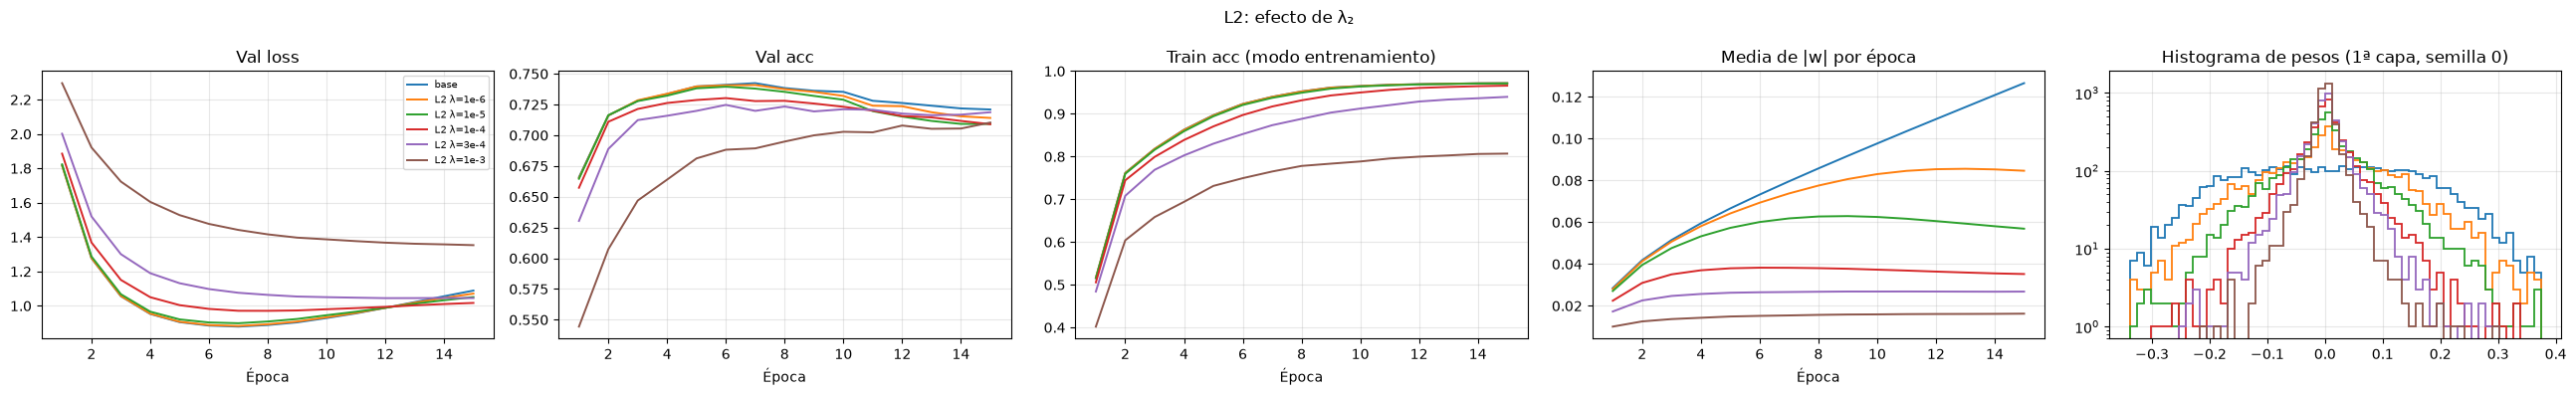

- **Accuracy:** sin regularizar 0.7424; el mejor L2 es **L2 λ=1e-6** con 0.7408 (-0.2 puntos: diferencia dentro del error de la validación). Con λ mayores la val acc es: L2 λ=1e-5 → 0.7380, L2 λ=1e-4 → 0.7274, L2 λ=3e-4 → 0.7167, L2 λ=1e-3 → 0.7103. Colapsan (más de 3 errores estándar por debajo de la base): L2 λ=1e-3.
- **Valor absoluto de los pesos:** media de |w| 0.1266 sin regularizar (al inicializar 0.0051); con L2 λ=1e-6 baja a 0.0847 (67% de la base); con el mayor λ llega a 0.0163. El peso máximo pasa de 1.92 a 1.96. La media de |w| decrece de forma monótona con λ.
- **Brecha train−val:** 23.0 puntos sin regularizar y 23.2 con L2 λ=1e-6; train(eval) 0.973 → 0.973.
- **Ruido de la curva de val loss:** 0.0060 (base) → 0.0060 (L2 λ=1e-6) → 0.0054 (λ máximo); ruido de train acc 0.0023 → 0.0024 → 0.0036.
- **Tiempo:** 2.9 s por época sin penalización vs 3.3 s con L2 λ=1e-6 (tiempo de pared con ruido de máquina; el costo medido sin ruido está en 4.11): la penalización explícita recorre todos los pesos en cada paso. Épocas hasta el 97 % de la val acc base: 3.0 (base) vs 3.0 (L2 λ=1e-6).

In [12]:
L2_GRID = [1e-6, 1e-5, 1e-4, 3e-4, 1e-3]
cfgs = [("base", {**BASE})] + [(f"L2 λ={sci(l)}", {**BASE, "l2": l}) for l in L2_GRID]
rows_l2 = collect("L2", cfgs); ALL_ROWS += rows_l2
a = agg(rows_l2, TARGET); display(a.round(4))
plot_exp(rows_l2, [c[0] for c in cfgs], "tp3_l2", "L2: efecto de λ₂")

base, nz = a.loc["base"], list(a.index[1:])
best = a.loc[nz].val_sel.idxmax(); lam_best = L2_GRID[nz.index(best)]; bb = a.loc[best]
colapsa = [l for l in nz if a.loc[l].val_sel < base.val_sel - 3 * SE_VAL]
dec = all(np.diff(a.mean_abs_w.values) < 0)
SUMMARY["l2"] = dict(lam=lam_best, delta=bb.val_sel - base.val_sel, w_ratio=bb.mean_abs_w / base.mean_abs_w, gap_base=base.gap, gap_best=bb.gap)
display(Markdown(
    f"- **Accuracy:** sin regularizar {base.val_sel:.4f}; el mejor L2 es **{best}** con {bb.val_sel:.4f} ({pts(bb.val_sel - base.val_sel)} puntos: {veredicto(bb.val_sel - base.val_sel)}). "
    + (("Con λ mayores la val acc es: " + ", ".join(f"{l} → {a.loc[l].val_sel:.4f}" for l in nz if L2_GRID[nz.index(l)] > lam_best) + ". ") if any(L2_GRID[nz.index(l)] > lam_best for l in nz) else "Es el mayor λ probado. ")
    + (f"Colapsan (más de 3 errores estándar por debajo de la base): {', '.join(colapsa)}.\n" if colapsa else "Ningún λ probado colapsa el modelo.\n")
    + f"- **Valor absoluto de los pesos:** media de |w| {base.mean_abs_w:.4f} sin regularizar (al inicializar {init_stats['mean_abs_w']:.4f}); con {best} baja a {bb.mean_abs_w:.4f} ({bb.mean_abs_w / base.mean_abs_w:.0%} de la base); con el mayor λ llega a {a.mean_abs_w.iloc[-1]:.4f}. "
    f"El peso máximo pasa de {base.max_abs_w:.2f} a {bb.max_abs_w:.2f}. La media de |w| {'decrece de forma monótona con λ' if dec else 'no decrece de forma monótona con λ'}.\n"
    f"- **Brecha train−val:** {base.gap * 100:.1f} puntos sin regularizar y {bb.gap * 100:.1f} con {best}; train(eval) {base.train_acc_eval:.3f} → {bb.train_acc_eval:.3f}.\n"
    f"- **Ruido de la curva de val loss:** {base.noise_val_loss:.4f} (base) → {bb.noise_val_loss:.4f} ({best}) → {a.noise_val_loss.iloc[-1]:.4f} (λ máximo); ruido de train acc {base.noise_train_acc:.4f} → {bb.noise_train_acc:.4f} → {a.noise_train_acc.iloc[-1]:.4f}.\n"
    f"- **Tiempo:** {base.t_epoch:.1f} s por época sin penalización vs {bb.t_epoch:.1f} s con {best} (tiempo de pared con ruido de máquina; el costo medido sin ruido está en 4.11): la penalización explícita recorre todos los pesos en cada paso. "
    f"Épocas hasta el 97 % de la val acc base: {en(base.ep_target)} (base) vs {en(bb.ep_target)} ({best})."))

**Qué dice la clase y cómo se lee lo anterior.** L2 modifica la función de costo para penalizar pesos altos, y la clase muestra que el overfitting viene acompañado de pesos grandes (modelo muy seguro, sigmoide/softmax saturada), mientras que mantenerlos bajos quita seguridad al modelo y hace trabajar a la activación cerca de su zona lineal. Los números de arriba permiten comprobar cada parte: (i) la **media de |w|** y el histograma (`figures/tp3_l2.png`) muestran cómo se contraen los pesos al subir λ₂; (ii) la **brecha** train−val indica si la contracción reduce la varianza; (iii) con λ₂ demasiado grande el término de penalización domina sobre la entropía cruzada y el modelo hace **underfitting** (más bias), que es el costo de MAP con una prior muy concentrada; (iv) el **ruido** de las curvas es la señal que la clase advierte que crece con λ. Las conclusiones concretas son las de las viñetas generadas (si una diferencia está dentro del error de la validación, no se interpreta).

## 4.2 Regularización L1

`J_R = J + λ₁ Σ |w|`. La penalización lineal reduce todos los pesos por igual y empuja muchos exactamente hacia 0 (esparsidad). Se barre λ₁ ∈ {0, 1e-6, 1e-5, 3e-5, 1e-4}. Además se repite la **poda por umbral** de la clase: se llevan a 0 los pesos con |w| menor a un umbral y se mide cuánto cambia la val acc.

  L1         | base                                   | s0 | val 0.7428 | train(eval) 0.973 | mean|w| 0.1267 | 3.4s/ép
  L1         | base                                   | s1 | val 0.7419 | train(eval) 0.973 | mean|w| 0.1264 | 2.3s/ép
  L1         | L1 λ=1e-6                              | s0 | val 0.7397 | train(eval) 0.973 | mean|w| 0.0565 | 2.7s/ép
  L1         | L1 λ=1e-6                              | s1 | val 0.7327 | train(eval) 0.973 | mean|w| 0.0573 | 2.7s/ép
  L1         | L1 λ=1e-5                              | s0 | val 0.7269 | train(eval) 0.971 | mean|w| 0.0295 | 2.7s/ép
  L1         | L1 λ=1e-5                              | s1 | val 0.7225 | train(eval) 0.971 | mean|w| 0.0296 | 2.7s/ép
  L1         | L1 λ=3e-5                              | s0 | val 0.7044 | train(eval) 0.952 | mean|w| 0.0192 | 2.7s/ép
  L1         | L1 λ=3e-5                              | s1 | val 0.7044 | train(eval) 0.951 | mean|w| 0.0192 | 2.7s/ép
  L1         | L1 λ=1e-4                        

,val_sel,val_max,val_last,train_acc_eval,gap,mean_abs_w,median_abs_w,max_abs_w,frac_lt_1e3,noise_val_loss,noise_val_acc,noise_train_acc,t_epoch,ep_sel,ep_target,t_target,val_sd,n_div
label,,,,,,,,,,,,,,,,,,
base,0.7424,0.7424,0.7209,0.9727,0.2303,0.1266,0.1121,1.9198,0.0043,0.0060,0.0026,0.0023,2.8621,7.0,3.0,6.1077,0.0006,0
L1 λ=1e-6,0.7362,0.7391,0.7106,0.9727,0.2365,0.0569,0.0082,2.0259,0.3045,0.0060,0.0020,0.0025,2.7329,7.0,3.0,8.1319,0.0050,0
L1 λ=1e-5,0.7247,0.7274,0.6993,0.9707,0.2460,0.0295,0.0020,2.2739,0.4450,0.0059,0.0020,0.0021,2.6971,7.0,4.0,11.2803,0.0031,0
L1 λ=3e-5,0.7044,0.7086,0.6958,0.9517,0.2473,0.0192,0.0010,2.3437,0.4975,0.0066,0.0034,0.0016,2.6841,10.0,NaN,NaN,0.0000,0
L1 λ=1e-4,0.6699,0.6701,0.6699,0.8098,0.1399,0.0089,0.0004,2.4988,0.6353,0.0080,0.0033,0.0031,2.6514,15.0,NaN,NaN,0.0031,0


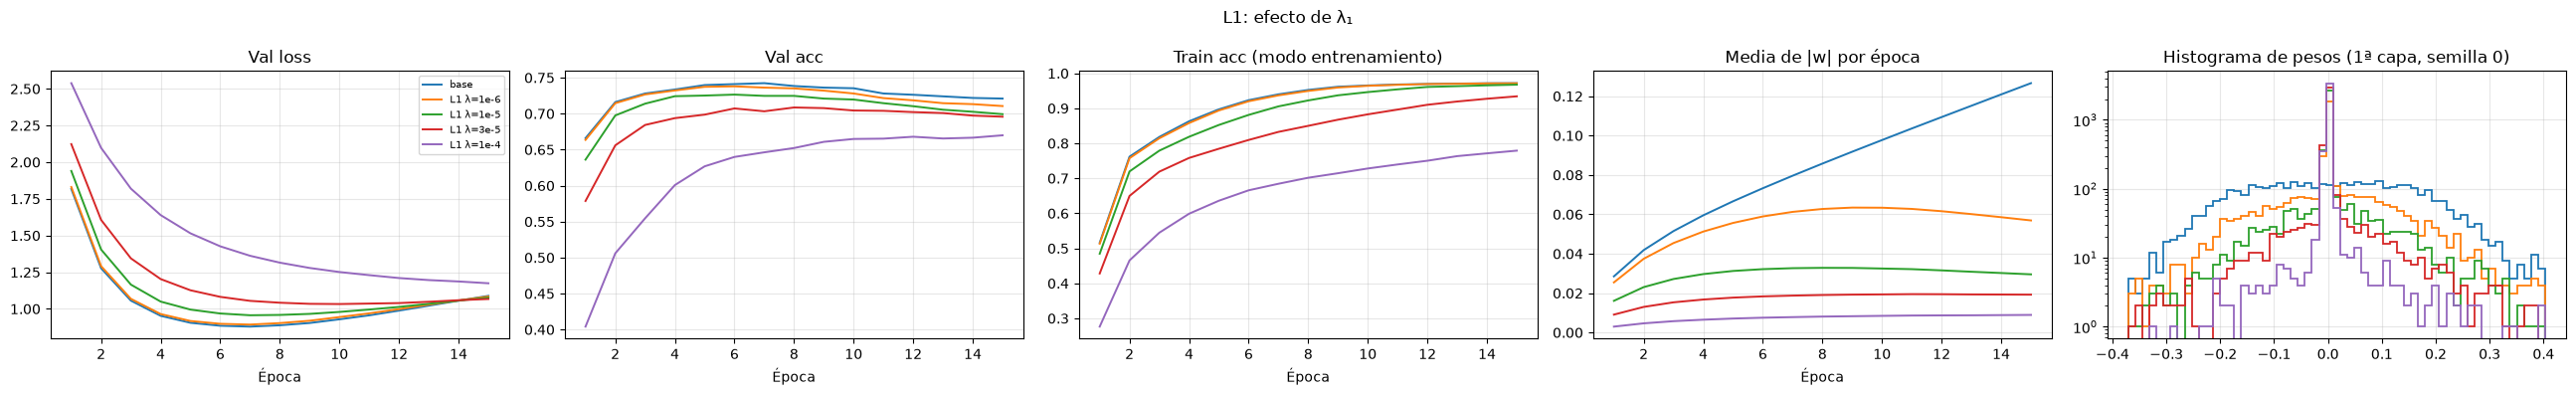

,pesos_en_cero,val_acc
umbral,,
0.000,0.0000,0.7110
0.001,0.3111,0.7110
0.010,0.5188,0.7114
0.050,0.6483,0.7088


- **Accuracy:** sin regularizar 0.7424; el mejor L1 es **L1 λ=1e-6** con 0.7362 (-0.6 puntos: diferencia dentro del error de la validación). Colapsan: L1 λ=3e-5, L1 λ=1e-4.
- **Esparsidad:** fracción de pesos con |w| < 1e-3: 0.4% sin regularizar (al inicializar 9.9%), 30.4% con L1 λ=1e-6 y 63.5% con el mayor λ. Media de |w|: 0.1266 → 0.0569 (L1 λ=1e-6); peso máximo 1.92 → 2.03. El histograma (`figures/tp3_l1.png`) muestra un pico mucho más alto en 0 que sin regularizar, con una minoría de pesos grandes que sobrevive, como en la clase.
- **Poda por umbral** (sobre L1 λ=1e-6, semilla 0): anular los pesos con |w|<1e-3 / 1e-2 / 5e-2 deja 31.1% / 51.9% / 64.8% de los pesos en cero y cambia la val acc en +0.0 / +0.0 / -0.2 puntos respecto de 0.7110 (el resultado no se modifica de forma apreciable con los dos primeros umbrales, como en la clase).
- **Brecha train−val:** 23.0 → 23.6 puntos. **Ruido** de la val loss: 0.0060 → 0.0060. **Tiempo:** 2.9 → 2.7 s por época (tiempo de pared; el costo medido está en 4.11); épocas hasta el 97 %: 3.0 → 3.0.

In [13]:
L1_GRID = [1e-6, 1e-5, 3e-5, 1e-4]
cfgs = [("base", {**BASE})] + [(f"L1 λ={sci(l)}", {**BASE, "l1": l}) for l in L1_GRID]
rows_l1 = collect("L1", cfgs); ALL_ROWS += rows_l1
a1 = agg(rows_l1, TARGET); display(a1.round(4))
plot_exp(rows_l1, [c[0] for c in cfgs], "tp3_l1", "L1: efecto de λ₁")

base, nz = a1.loc["base"], list(a1.index[1:])
best1 = a1.loc[nz].val_sel.idxmax(); lam1_best = L1_GRID[nz.index(best1)]; bb = a1.loc[best1]
colapsa = [l for l in nz if a1.loc[l].val_sel < base.val_sel - 3 * SE_VAL]
SUMMARY["l1"] = dict(lam=lam1_best, delta=bb.val_sel - base.val_sel, frac=bb.frac_lt_1e3, frac_base=base.frac_lt_1e3, w_ratio=bb.mean_abs_w / base.mean_abs_w)

# Poda por umbral sobre el mejor L1 (semilla 0): ¿cambia la val acc al anular los pesos chicos?
(res_p, m_p), _crit = run_cfg({**BASE, "l1": lam1_best}, CTRL_SEEDS[0], CTRL_EPOCHS, "L1 poda", "L1", keep_model=True, log=False), nn.CrossEntropyLoss()
_, val_p = make_loaders(tuple(BASE["key"]) + (BASE["scaling"],), BASE["batch_size"], CTRL_SEEDS[0])
m_p.to(device)
filas = []
state0 = {k: v.clone() for k, v in m_p.state_dict().items()}
for thr in [0, 1e-3, 1e-2, 5e-2]:
    m_p.load_state_dict(state0)
    with torch.no_grad():
        ws = linear_weights(m_p); tot = sum(w.numel() for w in ws); z = 0
        for w in ws:
            if thr > 0:
                mask = w.abs() < thr; z += int(mask.sum()); w[mask] = 0.0
    filas.append(dict(umbral=thr, pesos_en_cero=z / tot if thr > 0 else float((torch.cat([w.flatten() for w in linear_weights(m_p)]) == 0).float().mean()), val_acc=evaluate(m_p, val_p, _crit)[1]))
poda = pd.DataFrame(filas).set_index("umbral"); display(poda.round(4))
dpoda = poda.val_acc - poda.val_acc.iloc[0]
SUMMARY["l1"]["poda"] = poda

display(Markdown(
    f"- **Accuracy:** sin regularizar {base.val_sel:.4f}; el mejor L1 es **{best1}** con {bb.val_sel:.4f} ({pts(bb.val_sel - base.val_sel)} puntos: {veredicto(bb.val_sel - base.val_sel)}). "
    + (f"Colapsan: {', '.join(colapsa)}.\n" if colapsa else "Ningún λ probado colapsa el modelo.\n")
    + f"- **Esparsidad:** fracción de pesos con |w| < 1e-3: {base.frac_lt_1e3:.1%} sin regularizar (al inicializar {init_stats['frac_lt_1e3']:.1%}), {bb.frac_lt_1e3:.1%} con {best1} y {a1.frac_lt_1e3.iloc[-1]:.1%} con el mayor λ. "
    f"Media de |w|: {base.mean_abs_w:.4f} → {bb.mean_abs_w:.4f} ({best1}); peso máximo {base.max_abs_w:.2f} → {bb.max_abs_w:.2f}. "
    f"El histograma (`figures/tp3_l1.png`) muestra {'un pico mucho más alto en 0 que sin regularizar' if bb.frac_lt_1e3 > base.frac_lt_1e3 + 0.05 else 'que el pico en 0 casi no cambia'}, con una minoría de pesos grandes que sobrevive, como en la clase.\n"
    f"- **Poda por umbral** (sobre {best1}, semilla {CTRL_SEEDS[0]}): anular los pesos con |w|<1e-3 / 1e-2 / 5e-2 deja {poda.pesos_en_cero.iloc[1]:.1%} / {poda.pesos_en_cero.iloc[2]:.1%} / {poda.pesos_en_cero.iloc[3]:.1%} de los pesos en cero y cambia la val acc en "
    f"{pts(dpoda.iloc[1])} / {pts(dpoda.iloc[2])} / {pts(dpoda.iloc[3])} puntos respecto de {poda.val_acc.iloc[0]:.4f}"
    f" ({'el resultado no se modifica de forma apreciable con los dos primeros umbrales, como en la clase' if abs(dpoda.iloc[1]) < SE_VAL and abs(dpoda.iloc[2]) < SE_VAL else 'ya con umbrales chicos el resultado se modifica'}).\n"
    f"- **Brecha train−val:** {base.gap * 100:.1f} → {bb.gap * 100:.1f} puntos. **Ruido** de la val loss: {base.noise_val_loss:.4f} → {bb.noise_val_loss:.4f}. "
    f"**Tiempo:** {base.t_epoch:.1f} → {bb.t_epoch:.1f} s por época (tiempo de pared; el costo medido está en 4.11); épocas hasta el 97 %: {en(base.ep_target)} → {en(bb.ep_target)}."))

**Qué dice la clase y cómo se lee lo anterior.** La penalización L1 es lineal, de modo que todos los pesos contribuyen igual al costo y se reducen por igual, lo que produce **parámetros esparsos y selección de parámetros**: el histograma de la clase tiene un pico en 0 con algunos pesos altos que sobreviven. Acá eso se mide con la fracción de pesos ≈ 0 y con la poda por umbral. Con los pesos aprendidos por el optimizador (RMSprop en la configuración base), L1 no los deja *exactamente* en 0 (el paso del optimizador oscila alrededor de 0), por eso se cuenta |w| < umbral en lugar de w = 0. El valor de λ₁ útil es mucho menor que el de λ₂ porque `Σ|w|` suma ~10⁶ términos (10000 features × unidades). Un λ₁ demasiado grande hace desaparecer casi todos los pesos (underfitting), como el caso λ=1e-3 de la clase.

## 4.3 L1 + L2 combinadas

La clase indica que L1 y L2 se pueden combinar. Se usa el mejor λ₁ y el mejor λ₂ de las secciones anteriores, y esos mismos valores divididos por 3 (para ver si se acumula la penalización).

  L1+L2      | base                                   | s0 | val 0.7428 | train(eval) 0.973 | mean|w| 0.1267 | 3.4s/ép
  L1+L2      | base                                   | s1 | val 0.7419 | train(eval) 0.973 | mean|w| 0.1264 | 2.3s/ép
  L1+L2      | L2 λ=1e-6                              | s0 | val 0.7419 | train(eval) 0.973 | mean|w| 0.0843 | 3.4s/ép
  L1+L2      | L2 λ=1e-6                              | s1 | val 0.7397 | train(eval) 0.973 | mean|w| 0.0850 | 3.3s/ép
  L1+L2      | L1 λ=1e-6                              | s0 | val 0.7397 | train(eval) 0.973 | mean|w| 0.0565 | 2.7s/ép
  L1+L2      | L1 λ=1e-6                              | s1 | val 0.7327 | train(eval) 0.973 | mean|w| 0.0573 | 2.7s/ép
  L1+L2      | L1+L2 (1e-6, 1e-6)                     | s0 | val 0.7402 | train(eval) 0.973 | mean|w| 0.0544 | 5.5s/ép
  L1+L2      | L1+L2 (1e-6, 1e-6)                     | s1 | val 0.7340 | train(eval) 0.973 | mean|w| 0.0552 | 6.9s/ép
  L1+L2      | L1+L2 (÷3 cada uno)              

,val_sel,val_max,val_last,train_acc_eval,gap,mean_abs_w,median_abs_w,max_abs_w,frac_lt_1e3,noise_val_loss,noise_val_acc,noise_train_acc,t_epoch,ep_sel,ep_target,t_target,val_sd,n_div
label,,,,,,,,,,,,,,,,,,
base,0.7424,0.7424,0.7209,0.9727,0.2303,0.1266,0.1121,1.9198,0.0043,0.006,0.0026,0.0023,2.8621,7.0,3.0,6.1077,0.0006,0
L2 λ=1e-6,0.7408,0.7415,0.7141,0.9727,0.2319,0.0847,0.0636,1.9571,0.0361,0.006,0.0021,0.0024,3.3397,7.0,3.0,10.2611,0.0016,0
L1 λ=1e-6,0.7362,0.7391,0.7106,0.9727,0.2365,0.0569,0.0082,2.0259,0.3045,0.006,0.0020,0.0025,2.7329,7.0,3.0,8.1319,0.0050,0
"L1+L2 (1e-6, 1e-6)",0.7371,0.7391,0.7095,0.9727,0.2356,0.0548,0.0093,2.0364,0.2822,0.006,0.0019,0.0025,6.1953,7.0,3.0,16.0889,0.0044,0
L1+L2 (÷3 cada uno),0.7388,0.7399,0.7121,0.9727,0.2339,0.0705,0.0362,1.9532,0.2166,0.006,0.0019,0.0025,7.4248,7.0,3.0,21.2023,0.0025,0


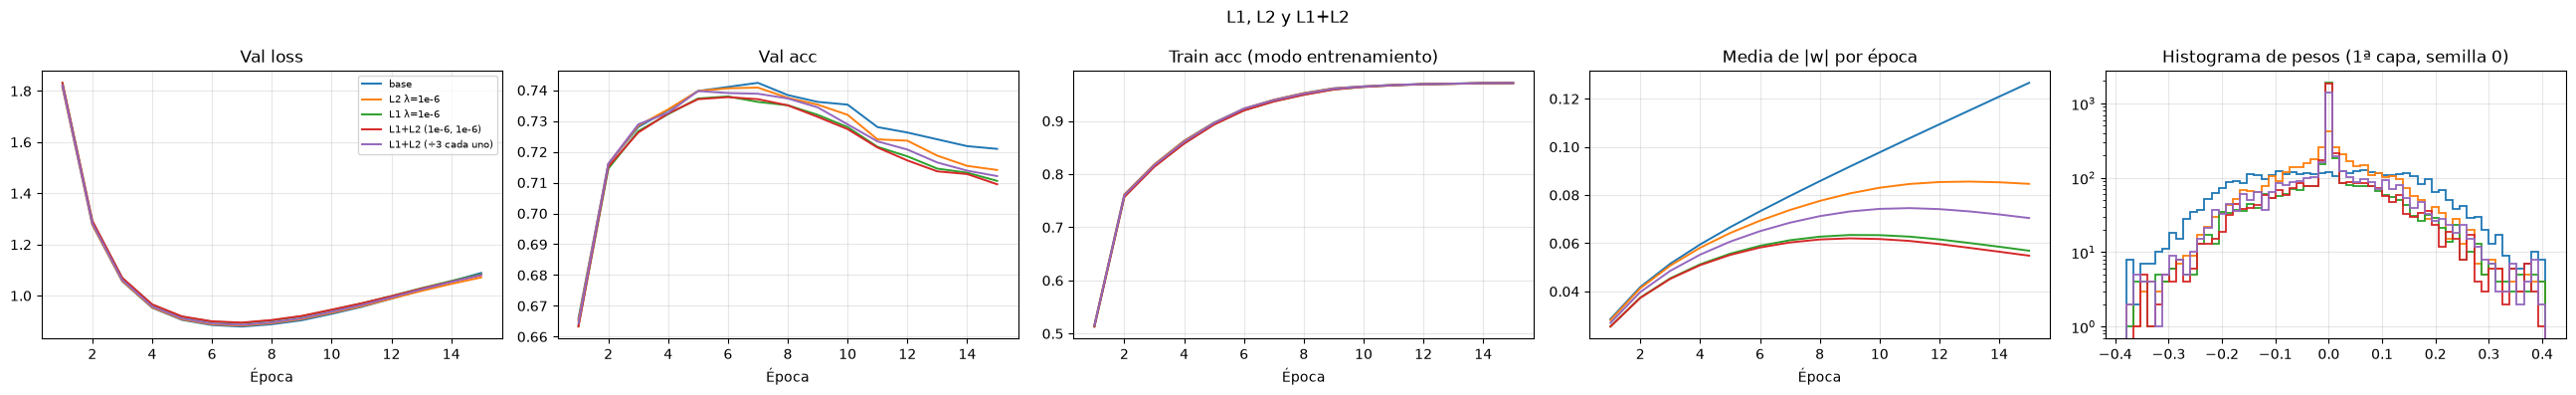

- **Accuracy:** base 0.7424; solo L2 0.7408; solo L1 0.7362; **L1+L2** 0.7371 (-0.5 puntos vs base: diferencia dentro del error de la validación) y con los λ÷3 0.7388 (-0.4). Frente al mejor de los dos solos (0.7408), la combinación no aporta una mejora apreciable (-0.4 puntos).
- **Pesos:** media de |w| 0.1266 (base), 0.0847 (L2), 0.0569 (L1), 0.0548 (L1+L2); fracción de pesos < 1e-3: 0.4%, 3.6%, 30.4%, 28.2%.
- **Brecha train−val:** 23.0 / 23.2 / 23.6 / 23.6 puntos. **Ruido** val loss: 0.0060 / 0.0060 / 0.0060 / 0.0060. **Tiempo por época:** 2.9 / 3.3 / 2.7 / 6.2 s (tiempo de pared; el costo medido está en 4.11).

In [14]:
cfgs = [("base", {**BASE}), (f"L2 λ={sci(lam_best)}", {**BASE, "l2": lam_best}), (f"L1 λ={sci(lam1_best)}", {**BASE, "l1": lam1_best}),
        (f"L1+L2 ({sci(lam1_best)}, {sci(lam_best)})", {**BASE, "l1": lam1_best, "l2": lam_best}),
        (f"L1+L2 (÷3 cada uno)", {**BASE, "l1": lam1_best / 3, "l2": lam_best / 3})]
rows_el = collect("L1+L2", cfgs); ALL_ROWS += rows_el
a3 = agg(rows_el, TARGET); display(a3.round(4))
plot_exp(rows_el, [c[0] for c in cfgs], "tp3_l1_l2", "L1, L2 y L1+L2")
base = a3.loc["base"]; e1, e2 = a3.iloc[3], a3.iloc[4]; s_l2, s_l1 = a3.iloc[1], a3.iloc[2]
SUMMARY["elastic"] = dict(val=e1.val_sel, delta=e1.val_sel - base.val_sel, val_div=e2.val_sel)
display(Markdown(
    f"- **Accuracy:** base {base.val_sel:.4f}; solo L2 {s_l2.val_sel:.4f}; solo L1 {s_l1.val_sel:.4f}; **L1+L2** {e1.val_sel:.4f} ({pts(e1.val_sel - base.val_sel)} puntos vs base: {veredicto(e1.val_sel - base.val_sel)}) y con los λ÷3 {e2.val_sel:.4f} ({pts(e2.val_sel - base.val_sel)}). "
    f"Frente al mejor de los dos solos ({max(s_l1.val_sel, s_l2.val_sel):.4f}), la combinación {'no aporta una mejora apreciable' if e1.val_sel - max(s_l1.val_sel, s_l2.val_sel) < SE_VAL else 'aporta una mejora apreciable'} ({pts(e1.val_sel - max(s_l1.val_sel, s_l2.val_sel))} puntos).\n"
    f"- **Pesos:** media de |w| {base.mean_abs_w:.4f} (base), {s_l2.mean_abs_w:.4f} (L2), {s_l1.mean_abs_w:.4f} (L1), {e1.mean_abs_w:.4f} (L1+L2); fracción de pesos < 1e-3: {base.frac_lt_1e3:.1%}, {s_l2.frac_lt_1e3:.1%}, {s_l1.frac_lt_1e3:.1%}, {e1.frac_lt_1e3:.1%}.\n"
    f"- **Brecha train−val:** {base.gap * 100:.1f} / {s_l2.gap * 100:.1f} / {s_l1.gap * 100:.1f} / {e1.gap * 100:.1f} puntos. **Ruido** val loss: {base.noise_val_loss:.4f} / {s_l2.noise_val_loss:.4f} / {s_l1.noise_val_loss:.4f} / {e1.noise_val_loss:.4f}. "
    f"**Tiempo por época:** {base.t_epoch:.1f} / {s_l2.t_epoch:.1f} / {s_l1.t_epoch:.1f} / {e1.t_epoch:.1f} s (tiempo de pared; el costo medido está en 4.11)."))

## 4.4 Dropout (y max-norm)

Se barre la tasa de dropout oculto ∈ {0.2, 0.35, 0.5, 0.7}, y se prueban las otras recomendaciones de clase: **dropout también en la entrada** (0.2 de entrada + 0.35 oculto) y **max-norm** (valor 4 de la clase y valor igual a la **norma de fila mediana** de la red base, que es el que realmente restringe: con un `c` mucho mayor que las normas reales la restricción nunca se activa). Se informa qué fracción de las filas de la primera capa quedó **en el tope** de max-norm.

  dropout    | base                                   | s0 | val 0.7428 | train(eval) 0.973 | mean|w| 0.1267 | 3.4s/ép
  dropout    | base                                   | s1 | val 0.7419 | train(eval) 0.973 | mean|w| 0.1264 | 2.3s/ép
  dropout    | dropout 0.2                            | s0 | val 0.7441 | train(eval) 0.971 | mean|w| 0.1122 | 3.2s/ép
  dropout    | dropout 0.2                            | s1 | val 0.7393 | train(eval) 0.971 | mean|w| 0.1119 | 2.9s/ép
  dropout    | dropout 0.35                           | s0 | val 0.7437 | train(eval) 0.969 | mean|w| 0.1033 | 3.0s/ép
  dropout    | dropout 0.35                           | s1 | val 0.7437 | train(eval) 0.969 | mean|w| 0.1029 | 3.0s/ép
  dropout    | dropout 0.5                            | s0 | val 0.7411 | train(eval) 0.963 | mean|w| 0.0938 | 2.7s/ép
  dropout    | dropout 0.5                            | s1 | val 0.7411 | train(eval) 0.962 | mean|w| 0.0935 | 2.3s/ép
  dropout    | dropout 0.7                      

,val_sel,val_max,val_last,train_acc_eval,gap,mean_abs_w,median_abs_w,max_abs_w,frac_lt_1e3,noise_val_loss,noise_val_acc,noise_train_acc,t_epoch,ep_sel,ep_target,t_target,val_sd,n_div
label,,,,,,,,,,,,,,,,,,
base,0.7424,0.7424,0.7209,0.9727,0.2303,0.1266,0.1121,1.9198,0.0043,0.0060,0.0026,0.0023,2.8621,7.0,3.0,6.1077,0.0006,0
dropout 0.2,0.7417,0.7430,0.7298,0.9714,0.2297,0.1121,0.0978,1.8644,0.0051,0.0064,0.0013,0.0024,3.0487,7.5,3.0,9.3617,0.0034,0
dropout 0.35,0.7437,0.7437,0.7327,0.9688,0.2251,0.1031,0.0889,1.6802,0.0057,0.0070,0.0018,0.0028,3.0129,9.0,3.5,11.4489,0.0000,0
dropout 0.5,0.7411,0.7437,0.7371,0.9624,0.2213,0.0937,0.0796,1.5122,0.0064,0.0080,0.0019,0.0021,2.4830,10.0,4.0,10.8763,0.0000,0
dropout 0.7,0.7397,0.7406,0.7397,0.9316,0.1918,0.0787,0.0651,1.2024,0.0079,0.0106,0.0019,0.0037,2.2152,15.0,5.5,12.6089,0.0050,0
entrada 0.2 + oculto 0.35,0.7417,0.7417,0.7364,0.9634,0.2217,0.0924,0.0789,1.6407,0.0066,0.0072,0.0015,0.0031,4.5451,10.5,3.5,15.9753,0.0003,0
max-norm c=4,0.7278,0.7364,0.7340,0.9041,0.1763,0.0324,0.0272,1.0966,0.0187,0.0016,0.0028,0.0027,2.1400,4.0,3.0,6.8945,0.0037,0
max-norm c=15.3,0.7424,0.7424,0.7207,0.9727,0.2303,0.1256,0.1112,1.9202,0.0043,0.0061,0.0026,0.0023,2.0775,7.0,3.0,6.3351,0.0006,0
dropout 0.5 + max-norm c=4,0.7291,0.7369,0.7362,0.8958,0.1667,0.0320,0.0264,0.9648,0.0192,0.0060,0.0023,0.0028,2.3689,6.0,4.5,9.5810,0.0019,0



Fracción de filas de la 1ª capa en el tope de max-norm:
label
max-norm c=4                     1.000
max-norm c=15.3                  0.484
dropout 0.5 + max-norm c=4       1.000
dropout 0.5 + max-norm c=15.3    0.000
Name: maxnorm_active, dtype: float64


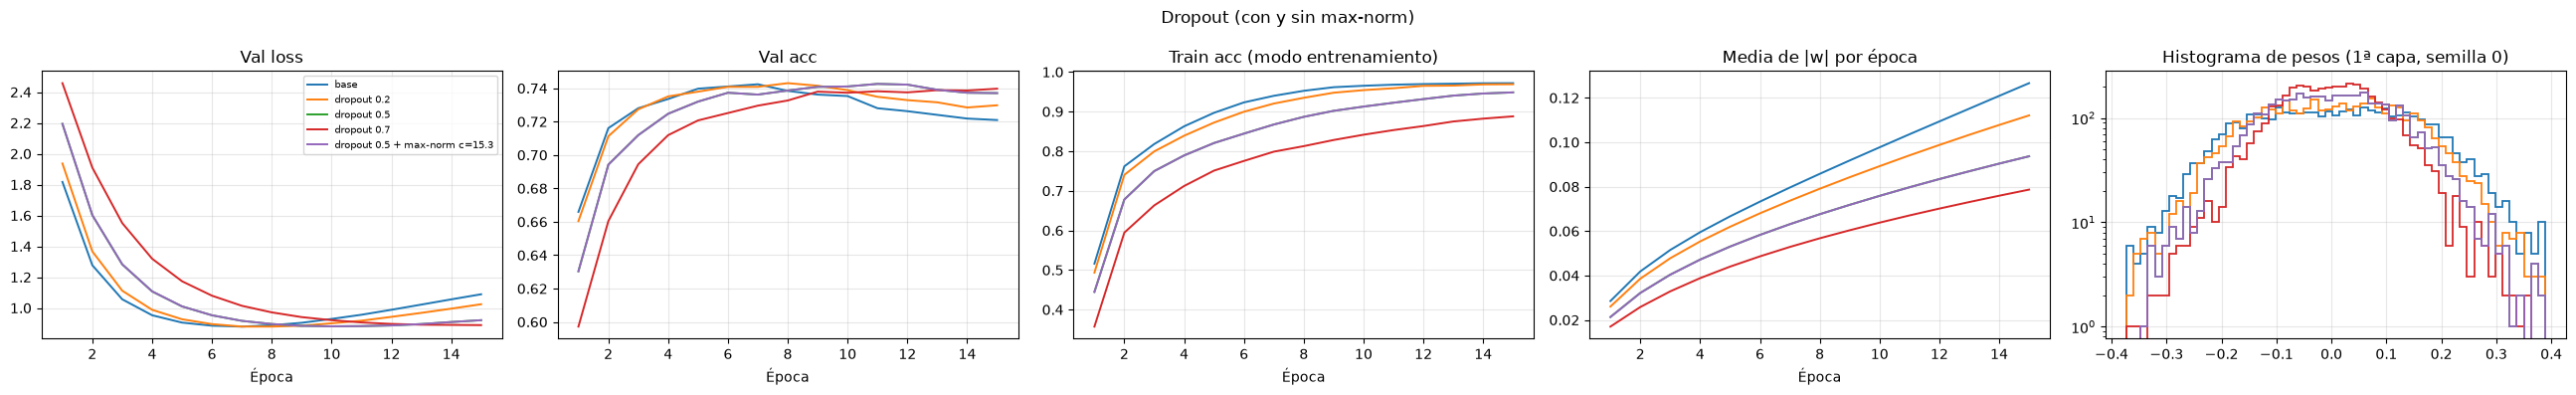

- **Accuracy:** base 0.7424; el mejor dropout es **0.35** con 0.7437 (+0.1 puntos: diferencia dentro del error de la validación). Dentro de 0.2–0.7 la val acc varía 0.4 puntos; con 0.7 = 0.7397.
- **Brecha train−val (train en modo evaluación):** 23.0 (base) → 23.0 (0.2), 22.5 (0.35), 22.1 (0.5), 19.2 (0.7) puntos.
- **Ruido:** la train acc en modo entrenamiento (con dropout activo) tiene ruido 0.0023 (base) → 0.0021 (dropout 0.5) → 0.0037 (0.7), mientras que el de la val acc es 0.0026 → 0.0019 → 0.0019: no se ve una curva de train claramente más ruidosa que la de validación.
- **Pesos:** media de |w| 0.1266 (base) → 0.0937 (0.5); peso máximo 1.92 → 1.51.
- **Entrada + oculto:** 0.7417 vs 0.7437 solo oculto.
- **Max-norm:** con c=4 el tope lo alcanzan 100.0% de las filas y la val acc es 0.7278; con c=15.3 lo alcanzan 48.4% y la val acc es 0.7424. Dropout 0.5 + max-norm c=15.3: 0.7411 (vs 0.7411 sin max-norm). El apunte dice que con max-norm el resultado es menos sensible al valor de dropout; acá la diferencia entre dropout 0.5 con y sin max-norm es de 0.0 puntos (no hay evidencia suficiente para afirmarlo).
- **Tiempo:** 2.9 s por época (base) vs 2.5 s con dropout 0.5 (tiempo de pared; el costo medido está en 4.11); épocas hasta el 97 % de la val acc base: 3.0 (base) vs 4.0 (dropout 0.5), y época de mínima val loss 7.0 vs 10.0.

In [15]:
DO_GRID = [0.2, 0.35, 0.5, 0.7]
C_MED = round(ROW_NORM_MED, 1)
cfgs = [("base", {**BASE})] + [(f"dropout {p}", {**BASE, "dropout": p}) for p in DO_GRID] + [
    ("entrada 0.2 + oculto 0.35", {**BASE, "input_dropout": 0.2, "dropout": 0.35}),
    ("max-norm c=4", {**BASE, "maxnorm": 4.0}), (f"max-norm c={C_MED}", {**BASE, "maxnorm": C_MED}),
    ("dropout 0.5 + max-norm c=4", {**BASE, "dropout": 0.5, "maxnorm": 4.0}),
    (f"dropout 0.5 + max-norm c={C_MED}", {**BASE, "dropout": 0.5, "maxnorm": C_MED})]
rows_do = collect("dropout", cfgs); ALL_ROWS += rows_do
a4 = agg(rows_do, TARGET); display(a4.round(4))
act = pd.DataFrame([dict(label=r["label"], seed=r["seed"], maxnorm_active=r.get("maxnorm_active", np.nan)) for r in rows_do if r["cfg"].get("maxnorm")]).groupby("label", sort=False).maxnorm_active.mean()
print("\nFracción de filas de la 1ª capa en el tope de max-norm:"); print(act.round(3))
plot_exp(rows_do, ["base"] + [f"dropout {p}" for p in [0.2, 0.5, 0.7]] + [f"dropout 0.5 + max-norm c={C_MED}"], "tp3_dropout", "Dropout (con y sin max-norm)")

base = a4.loc["base"]; dlabs = [f"dropout {p}" for p in DO_GRID]
bestd = a4.loc[dlabs].val_sel.idxmax(); p_best = DO_GRID[dlabs.index(bestd)]; bd = a4.loc[bestd]
mn = a4.loc[f"dropout 0.5 + max-norm c={C_MED}"]; d5 = a4.loc["dropout 0.5"]
sens_do = a4.loc[dlabs].val_sel.max() - a4.loc[dlabs].val_sel.min()
sens_mn = a4.loc[["dropout 0.5", f"dropout 0.5 + max-norm c={C_MED}"]].val_sel.diff().abs().iloc[-1]
SUMMARY["dropout"] = dict(p=p_best, delta=bd.val_sel - base.val_sel, w_ratio=bd.mean_abs_w / base.mean_abs_w)
display(Markdown(
    f"- **Accuracy:** base {base.val_sel:.4f}; el mejor dropout es **{p_best}** con {bd.val_sel:.4f} ({pts(bd.val_sel - base.val_sel)} puntos: {veredicto(bd.val_sel - base.val_sel)}). "
    f"Dentro de 0.2–0.7 la val acc varía {sens_do * 100:.1f} puntos; con 0.7 = {a4.loc['dropout 0.7'].val_sel:.4f}.\n"
    f"- **Brecha train−val (train en modo evaluación):** {base.gap * 100:.1f} (base) → " + ", ".join(f"{a4.loc[l].gap * 100:.1f} ({l.split()[1]})" for l in dlabs) + " puntos.\n"
    f"- **Ruido:** la train acc en modo entrenamiento (con dropout activo) tiene ruido {base.noise_train_acc:.4f} (base) → {d5.noise_train_acc:.4f} (dropout 0.5) → {a4.loc['dropout 0.7'].noise_train_acc:.4f} (0.7), "
    f"mientras que el de la val acc es {base.noise_val_acc:.4f} → {d5.noise_val_acc:.4f} → {a4.loc['dropout 0.7'].noise_val_acc:.4f}: "
    f"{'la curva de train es bastante más ruidosa que la de validación (como en la clase)' if d5.noise_train_acc > 1.5 * d5.noise_val_acc else 'no se ve una curva de train claramente más ruidosa que la de validación'}.\n"
    f"- **Pesos:** media de |w| {base.mean_abs_w:.4f} (base) → {a4.loc['dropout 0.5'].mean_abs_w:.4f} (0.5); peso máximo {base.max_abs_w:.2f} → {a4.loc['dropout 0.5'].max_abs_w:.2f}.\n"
    f"- **Entrada + oculto:** {a4.loc['entrada 0.2 + oculto 0.35'].val_sel:.4f} vs {a4.loc['dropout 0.35'].val_sel:.4f} solo oculto.\n"
    f"- **Max-norm:** con c=4 el tope lo alcanzan {act.get('max-norm c=4', float('nan')):.1%} de las filas y la val acc es {a4.loc['max-norm c=4'].val_sel:.4f}; con c={C_MED} lo alcanzan {act.get(f'max-norm c={C_MED}', float('nan')):.1%} y la val acc es {a4.loc[f'max-norm c={C_MED}'].val_sel:.4f}. "
    f"Dropout 0.5 + max-norm c={C_MED}: {mn.val_sel:.4f} (vs {d5.val_sel:.4f} sin max-norm). El apunte dice que con max-norm el resultado es menos sensible al valor de dropout; acá la diferencia entre dropout 0.5 con y sin max-norm es de {sens_mn * 100:.1f} puntos"
    f" ({'no hay evidencia suficiente para afirmarlo' if sens_mn < SE_VAL else 'supera el error de la validación'}).\n"
    f"- **Tiempo:** {base.t_epoch:.1f} s por época (base) vs {d5.t_epoch:.1f} s con dropout 0.5 (tiempo de pared; el costo medido está en 4.11); épocas hasta el 97 % de la val acc base: {en(base.ep_target)} (base) vs {en(d5.ep_target)} (dropout 0.5), "
    f"y época de mínima val loss {base.ep_sel:.1f} vs {d5.ep_sel:.1f}."))

**Qué dice la clase y cómo se lee lo anterior.** Dropout elimina conexiones al azar durante el entrenamiento (y reescala las activaciones por 1/keep_prob), por lo que se puede ver como un promedio de muchas subredes que impide la co-adaptación entre neuronas. Las recomendaciones de la clase (20–50 %, red grande, learning rate más grande con decay y momentum, max-norm, más épocas) se contrastan arriba con lo medido: el efecto sobre la **brecha** muestra si reduce la varianza; el **ruido de la train acc** aparece porque en cada paso se evalúa una subred distinta, y por eso la accuracy de train "en modo entrenamiento" no es comparable con la de validación (para la brecha se usa la de modo evaluación); si la época de mínima val loss se corre hacia la derecha, es la señal de que "hay que entrenar más épocas" como se vio en la clase. La recomendación de **learning rate más grande** se prueba en la sección 4.6 y la de **red grande** en la 4.10.

## 4.5 Batch Normalization

Se compara `Linear(sin bias) → BN → activación` contra la red sin BN, con **tres tamaños de mini-batch** (32, 128, 512), porque el apunte indica que la media y varianza se calculan por mini-batch (ruidosas → leve efecto regularizador) y que "se podría jugar con el tamaño del mini-batch". También se prueba el momentum del promedio móvil: 0.1 (default de PyTorch) y **0.01**, equivalente al 0.99 de Keras.

  BN         | sin BN, bs=32                          | s0 | val 0.7428 | train(eval) 0.973 | mean|w| 0.1267 | 3.4s/ép
  BN         | sin BN, bs=32                          | s1 | val 0.7419 | train(eval) 0.973 | mean|w| 0.1264 | 2.3s/ép
  BN         | BN, bs=32                              | s0 | val 0.7221 | train(eval) 0.972 | mean|w| 0.0320 | 2.0s/ép
  BN         | BN, bs=32                              | s1 | val 0.7238 | train(eval) 0.972 | mean|w| 0.0319 | 2.0s/ép
  BN         | sin BN, bs=128                         | s0 | val 0.7450 | train(eval) 0.967 | mean|w| 0.0931 | 0.8s/ép
  BN         | sin BN, bs=128                         | s1 | val 0.7411 | train(eval) 0.966 | mean|w| 0.0925 | 0.8s/ép
  BN         | BN, bs=128                             | s0 | val 0.7092 | train(eval) 0.973 | mean|w| 0.0186 | 0.8s/ép
  BN         | BN, bs=128                             | s1 | val 0.7039 | train(eval) 0.973 | mean|w| 0.0187 | 0.9s/ép
  BN         | sin BN, bs=512                   

,val_sel,val_max,val_last,train_acc_eval,gap,mean_abs_w,median_abs_w,max_abs_w,frac_lt_1e3,noise_val_loss,noise_val_acc,noise_train_acc,t_epoch,ep_sel,ep_target,t_target,val_sd,n_div
label,,,,,,,,,,,,,,,,,,
"sin BN, bs=32",0.7424,0.7424,0.7209,0.9727,0.2303,0.1266,0.1121,1.9198,0.0043,0.0060,0.0026,0.0023,2.8621,7.0,3.0,6.1077,0.0006,0
"BN, bs=32",0.7229,0.7229,0.6372,0.9720,0.2491,0.0319,0.0266,0.5272,0.0203,0.0241,0.0041,0.0007,2.0087,1.0,1.0,2.1396,0.0012,0
"sin BN, bs=128",0.7430,0.7439,0.7419,0.9663,0.2233,0.0928,0.0828,0.9620,0.0056,0.0080,0.0012,0.0016,0.8211,14.0,4.0,3.4017,0.0028,0
"BN, bs=128",0.7066,0.7243,0.6578,0.9734,0.2668,0.0187,0.0156,0.3749,0.0345,0.0085,0.0044,0.0005,0.8568,2.0,1.0,0.8885,0.0037,0
"sin BN, bs=512",0.7373,0.7386,0.7373,0.9163,0.1790,0.0815,0.0761,0.4938,0.0061,0.0082,0.0019,0.0015,0.6188,15.0,7.0,4.4613,0.0022,0
"BN, bs=512",0.6863,0.6969,0.6617,0.9733,0.2871,0.0125,0.0103,0.2775,0.0522,0.0172,0.0027,0.0006,0.6079,5.0,NaN,NaN,0.0131,0
"BN, bs=128, momentum 0.01 (≈Keras 0.99)",0.6606,0.6734,0.6564,0.9734,0.3128,0.0187,0.0156,0.3749,0.0345,0.0325,0.0042,0.0005,1.0101,9.0,NaN,NaN,0.0087,0


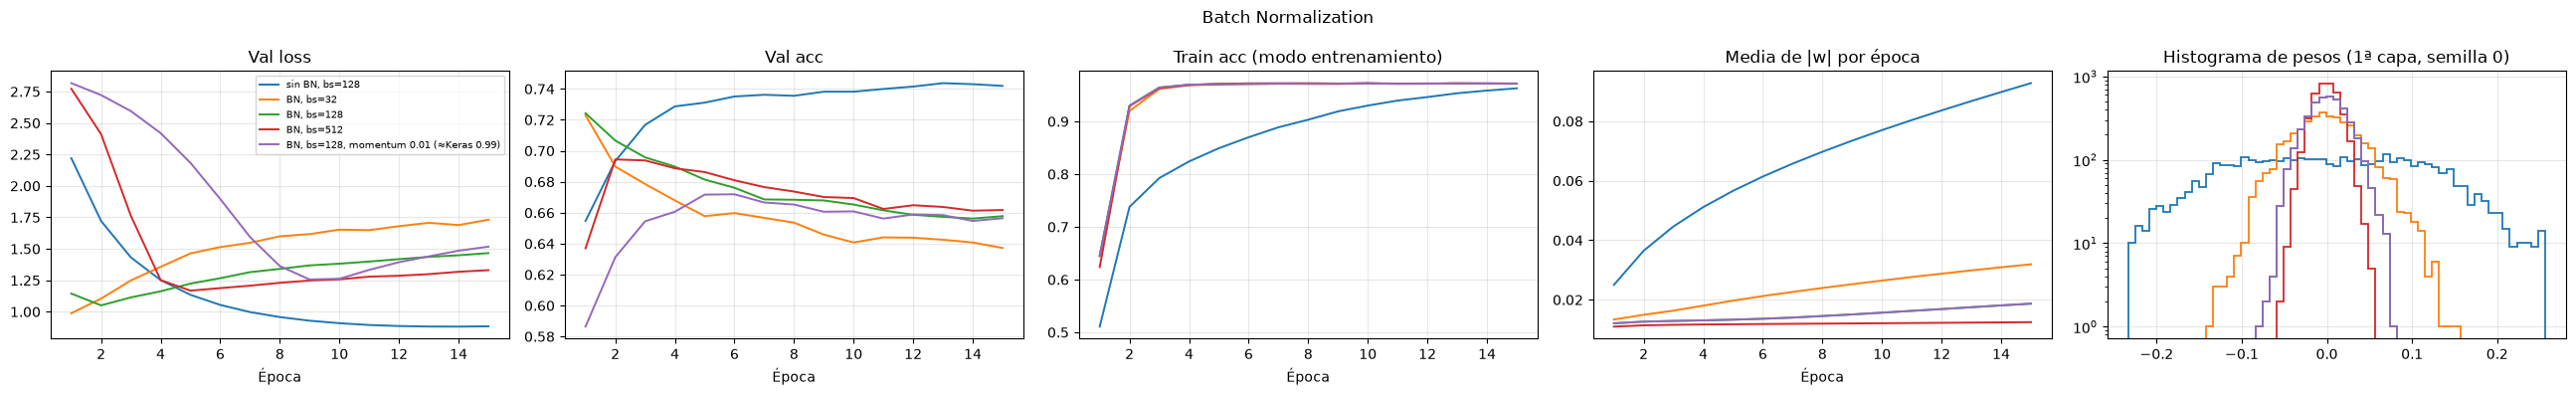

| batch size | val sin BN | val con BN | Δ (pts) | brecha train−val (pts) | ruido val loss | s/época (pared) | épocas al 97 % | media de \|w\| |
|---|---|---|---|---|---|---|---|---|
| 32 | 0.7424 | 0.7229 | -1.9 | 23.0 → 24.9 | 0.0060 → 0.0241 | 2.9 → 2.0 | 3.0 → 1.0 | 0.1266 → 0.0319 |
| 128 | 0.7430 | 0.7066 | -3.6 | 22.3 → 26.7 | 0.0080 → 0.0085 | 0.8 → 0.9 | 4.0 → 1.0 | 0.0928 → 0.0187 |
| 512 | 0.7373 | 0.6863 | -5.1 | 17.9 → 28.7 | 0.0082 → 0.0172 | 0.6 → 0.6 | 7.0 → no lo alcanza | 0.0815 → 0.0125 |

- **Accuracy:** con bs=128, BN -3.6 puntos (empeora de forma apreciable). Momentum 0.01: 0.6606 vs 0.7066 con 0.1.
- **Tiempo de entrenamiento:** el costo por época de BN se mide en 4.11 (los segundos de pared de esta tabla tienen ruido de máquina). Épocas hasta el 97 % de la val acc base (bs=128): 4.0 sin BN vs 1.0 con BN. La clase dice que BN es sobre todo una técnica de **aceleración del entrenamiento**: BN alcanza antes el nivel objetivo pero después se estanca en una val acc menor (-3.6 puntos) y con más brecha: acelera sin mejorar la generalización.
- **Efecto del tamaño de batch:** el ruido de la val loss con BN es 0.0241 (bs 32), 0.0085 (bs 128) y 0.0172 (bs 512), y la brecha 24.9 / 26.7 / 28.7 puntos: a menor batch más ruido, consistente con estadísticas más ruidosas por mini-batch. Atención: el tamaño de batch también cambia el número de pasos por época, por eso la comparación con BN se hace contra la red sin BN **del mismo batch**.
- **Pesos:** media de |w| 0.0928 → 0.0187 (bs=128). Con BN la escala de los pesos previos a la normalización no determina la salida de la capa, por eso su valor absoluto no es comparable con el de la red sin BN.

In [16]:
cfgs = []
for bs in [32, 128, 512]:
    cfgs += [(f"sin BN, bs={bs}", {**BASE, "batch_size": bs}), (f"BN, bs={bs}", {**BASE, "batch_size": bs, "use_bn": True})]
cfgs += [("BN, bs=128, momentum 0.01 (≈Keras 0.99)", {**BASE, "batch_size": 128, "use_bn": True, "bn_momentum": 0.01})]
rows_bn = collect("BN", cfgs); ALL_ROWS += rows_bn
a5 = agg(rows_bn, TARGET); display(a5.round(4))
plot_exp(rows_bn, ["sin BN, bs=128", "BN, bs=32", "BN, bs=128", "BN, bs=512", "BN, bs=128, momentum 0.01 (≈Keras 0.99)"], "tp3_bn", "Batch Normalization")

lines = []
for bs in [32, 128, 512]:
    n, y = a5.loc[f"sin BN, bs={bs}"], a5.loc[f"BN, bs={bs}"]
    lines.append(f"| {bs} | {n.val_sel:.4f} | {y.val_sel:.4f} | {pts(y.val_sel - n.val_sel)} | {n.gap * 100:.1f} → {y.gap * 100:.1f} | {n.noise_val_loss:.4f} → {y.noise_val_loss:.4f} | {n.t_epoch:.1f} → {y.t_epoch:.1f} | {en(n.ep_target)} → {en(y.ep_target)} | {n.mean_abs_w:.4f} → {y.mean_abs_w:.4f} |")
n, y = a5.loc["sin BN, bs=128"], a5.loc["BN, bs=128"]; ym = a5.loc["BN, bs=128, momentum 0.01 (≈Keras 0.99)"]
SUMMARY["bn"] = dict(delta=y.val_sel - n.val_sel, ep_n=n.ep_target, ep_y=y.ep_target, t_n=n.t_epoch, t_y=y.t_epoch)
display(Markdown(
    "| batch size | val sin BN | val con BN | Δ (pts) | brecha train−val (pts) | ruido val loss | s/época (pared) | épocas al 97 % | media de \\|w\\| |\n|---|---|---|---|---|---|---|---|---|\n" + "\n".join(lines) + "\n\n"
    f"- **Accuracy:** con bs=128, BN {pts(y.val_sel - n.val_sel)} puntos ({veredicto(y.val_sel - n.val_sel)}). Momentum 0.01: {ym.val_sel:.4f} vs {y.val_sel:.4f} con 0.1.\n"
    f"- **Tiempo de entrenamiento:** el costo por época de BN se mide en 4.11 (los segundos de pared de esta tabla tienen ruido de máquina). "
    f"Épocas hasta el 97 % de la val acc base (bs=128): {en(n.ep_target)} sin BN vs {en(y.ep_target)} con BN. "
    f"La clase dice que BN es sobre todo una técnica de **aceleración del entrenamiento**: "
    f"{('BN alcanza antes el nivel objetivo pero después se estanca en una val acc menor (' + pts(y.val_sel - n.val_sel) + ' puntos) y con más brecha: acelera sin mejorar la generalización') if (np.isfinite(y.ep_target) and (not np.isfinite(n.ep_target) or y.ep_target < n.ep_target) and y.val_sel - n.val_sel < -SE_VAL) else ('esto se confirma en este problema (menos épocas hasta el nivel objetivo)' if (np.isfinite(y.ep_target) and (not np.isfinite(n.ep_target) or y.ep_target < n.ep_target)) else 'no se ve una aceleración en épocas en este problema')}.\n"
    f"- **Efecto del tamaño de batch:** el ruido de la val loss con BN es {a5.loc['BN, bs=32'].noise_val_loss:.4f} (bs 32), {a5.loc['BN, bs=128'].noise_val_loss:.4f} (bs 128) y {a5.loc['BN, bs=512'].noise_val_loss:.4f} (bs 512), y la brecha {a5.loc['BN, bs=32'].gap * 100:.1f} / {a5.loc['BN, bs=128'].gap * 100:.1f} / {a5.loc['BN, bs=512'].gap * 100:.1f} puntos: "
    f"{'a menor batch más ruido, consistente con estadísticas más ruidosas por mini-batch' if a5.loc['BN, bs=32'].noise_val_loss > a5.loc['BN, bs=512'].noise_val_loss else 'no se ve la relación esperada entre tamaño de batch y ruido'}. "
    f"Atención: el tamaño de batch también cambia el número de pasos por época, por eso la comparación con BN se hace contra la red sin BN **del mismo batch**.\n"
    f"- **Pesos:** media de |w| {n.mean_abs_w:.4f} → {y.mean_abs_w:.4f} (bs=128). Con BN la escala de los pesos previos a la normalización no determina la salida de la capa, por eso su valor absoluto no es comparable con el de la red sin BN."))

**Qué dice la clase y cómo se lee lo anterior.** BN normaliza las activaciones de cada capa oculta con la media y varianza del mini-batch (como normalizar no solo la entrada sino todas las capas), y aprende γ y β. Como esas estadísticas son **ruidosas**, cada batch "se mueve" levemente respecto del anterior y eso da un efecto regularizador suave; pero estrictamente BN **no es regularización sino aceleración del entrenamiento** (por eso se mide también el número de épocas y el tiempo hasta un nivel de accuracy). En evaluación se usa el promedio móvil de media/varianza de los batches de entrenamiento (momentum). La capa lineal previa va sin bias porque β ya cumple ese rol, y la activación va después de BN (arquitectura usual).

## 4.6 Learning rate con y sin cada técnica

La clase hace dos recomendaciones sobre el learning rate: con **dropout** conviene un lr **más grande** (con decay y momentum), y BN ayuda a que el entrenamiento sea más estable. Se barre `lr` ∈ {3e-4, 1e-3, 3e-3, 1e-2} con **Adam** (una semilla por punto) para cinco variantes: sin regularización, **L2** y **dropout** con los mejores valores de las secciones 4.1 y 4.4, **BN**, y **dropout con ReduceLROnPlateau** (factor 0.3, paciencia 1). El scheduler mira la loss de **validación**: una primera versión con la loss de train no se activaba nunca (la loss de train baja en cada época y no se estanca), y el experimento resultaba vacío.

  lr         | sin reg | lr=3e-4                      | s0 | val 0.7424 | train(eval) 0.958 | mean|w| 0.0706 | 2.5s/ép
  lr         | sin reg | lr=1e-3                      | s0 | val 0.7437 | train(eval) 0.973 | mean|w| 0.0993 | 2.6s/ép
  lr         | sin reg | lr=3e-3                      | s0 | val 0.7406 | train(eval) 0.973 | mean|w| 0.1245 | 2.5s/ép
  lr         | sin reg | lr=1e-2                      | s0 | val 0.7181 | train(eval) 0.972 | mean|w| 0.2069 | 2.5s/ép
  lr         | L2 λ=1e-6 | lr=3e-4                    | s0 | val 0.7428 | train(eval) 0.958 | mean|w| 0.0692 | 3.7s/ép
  lr         | L2 λ=1e-6 | lr=1e-3                    | s0 | val 0.7437 | train(eval) 0.973 | mean|w| 0.0905 | 3.6s/ép
  lr         | L2 λ=1e-6 | lr=3e-3                    | s0 | val 0.7441 | train(eval) 0.973 | mean|w| 0.0906 | 3.3s/ép
  lr         | L2 λ=1e-6 | lr=1e-2                    | s0 | val 0.7159 | train(eval) 0.968 | mean|w| 0.2672 | 3.3s/ép
  lr         | dropout 0.35 | lr=3e-4           

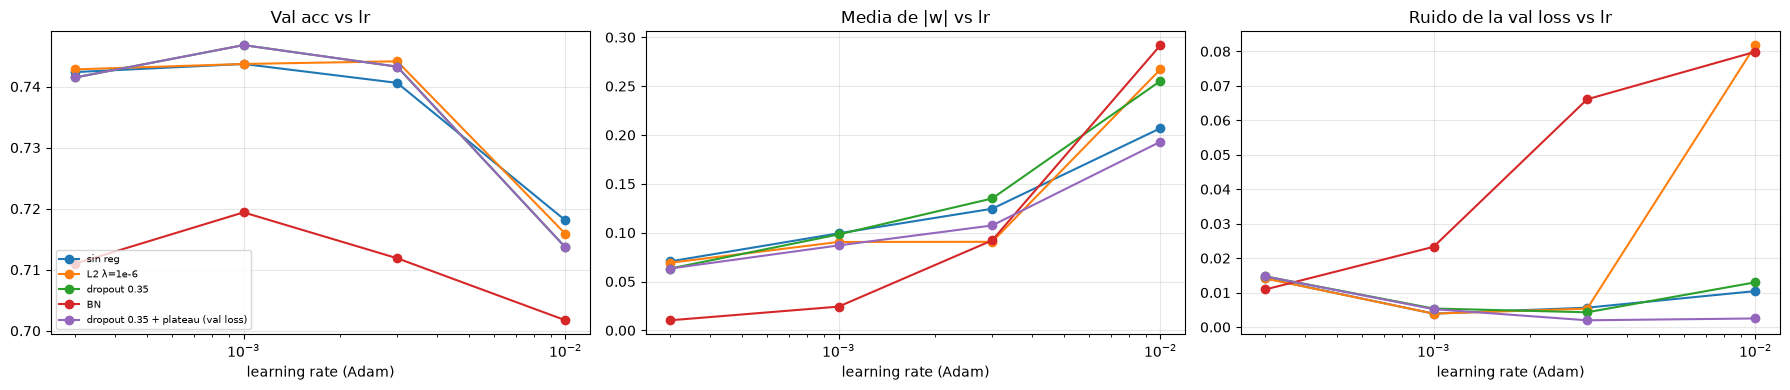

- **Mejor lr de cada variante:** sin reg: 1e-03 (0.7437); L2 λ=1e-6: 3e-03 (0.7441); dropout 0.35: 1e-03 (0.7468); BN: 1e-03 (0.7194); dropout 0.35 + plateau (val loss): 1e-03 (0.7468).
- **Con el lr más alto (1e-2):** sin reg 0.7181; L2 λ=1e-6 0.7159; dropout 0.35 0.7137; BN 0.7017; dropout 0.35 + plateau (val loss) 0.7137. Alguna variante se degrada con lr alto (más de 3 errores estándar por debajo de su propio mejor valor): dropout 0.35, dropout 0.35 + plateau (val loss)
- **Con el lr más bajo (3e-4):** sin reg 0.7424; L2 λ=1e-6 0.7428; dropout 0.35 0.7415; BN 0.7110; dropout 0.35 + plateau (val loss) 0.7415. El mejor lr de la red sin regularizar es 1e-03 y el de la de dropout es 1e-03: dropout prefiere el mismo lr.
- **BN y el lr:** con BN el mejor lr es 1e-03 y la val acc con lr=1e-2 es 0.7017 contra 0.7181 sin BN (no se ve que BN tolere mejor el lr alto en este problema).
- **Dropout con ReduceLROnPlateau sobre la loss de validación** (factor 0.3, paciencia 1): redujo el lr en **3 de 4** corridas. La val acc en la época de mínima val loss **no puede cambiar por construcción** (el scheduler actúa después de ese mínimo, por eso sale idéntica a la de sin scheduler); el efecto se mide en lo que viene después. Con scheduler vs sin él: lr 3e-4: val acc de la última época 0.7415 vs 0.7415, ruido de la val loss 0.0147 vs 0.0147, media de |w| 0.063 vs 0.063; lr 1e-3: val acc de la última época 0.7388 vs 0.7304, ruido de la val loss 0.0052 vs 0.0054, media de |w| 0.087 vs 0.098; lr 3e-3: val acc de la última época 0.7357 vs 0.7212, ruido de la val loss 0.0020 vs 0.0043, media de |w| 0.107 vs 0.135; lr 1e-2: val acc de la última época 0.7190 vs 0.6951, ruido de la val loss 0.0025 vs 0.0130, media de |w| 0.193 vs 0.255. La clase espera que bajar el lr reduzca el ruido de la curva; se ve donde el scheduler se activó.

In [17]:
ALL_ROWS = [r for r in ALL_ROWS if r.get("exp") != "lr"]   # evita duplicados si se vuelve a ejecutar esta celda
VARIANTS = {"sin reg": {}, f"L2 λ={sci(lam_best)}": {"l2": lam_best}, f"dropout {p_best}": {"dropout": p_best},
            "BN": {"use_bn": True}, f"dropout {p_best} + plateau (val loss)": {"dropout": p_best, "plateau": "val"}}
rows_lr = []
for vname, extra in VARIANTS.items():
    for lr in LR_SWEEP:
        rows_lr += collect("lr", [(f"{vname} | lr={sci(lr)}", {**BASE, "opt": "adam", "momentum": 0.0, "lr": lr, **extra})], seeds=[CTRL_SEEDS[0]])
ALL_ROWS += rows_lr
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("hist", "wsample", "cfg")} for r in rows_lr])
df["variante"] = df.label.str.split(" \\| ").str[0]; df["lr"] = [r["cfg"]["lr"] for r in rows_lr]; df["gap"] = df.train_acc_eval - df.val_sel
for col, tit in [("val_sel", "val acc (época de mínima val loss)"), ("mean_abs_w", "media de |w|"), ("noise_val_loss", "ruido de la val loss"), ("t_epoch", "segundos por época")]:
    print(f"\n=== {tit} ==="); print(df.pivot(index="variante", columns="lr", values=col).reindex(list(VARIANTS)).round(4))
piv = df.pivot(index="variante", columns="lr", values="val_sel").reindex(list(VARIANTS))
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for v in VARIANTS:
    d = df[df.variante == v].sort_values("lr")
    ax[0].plot(d.lr, d.val_sel, "o-", label=v); ax[1].plot(d.lr, d.mean_abs_w, "o-"); ax[2].plot(d.lr, d.noise_val_loss, "o-")
for a_, t_ in zip(ax, ["Val acc vs lr", "Media de |w| vs lr", "Ruido de la val loss vs lr"]):
    a_.set_xscale("log"); a_.set_title(t_); a_.set_xlabel("learning rate (Adam)"); a_.grid(alpha=.3)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig("figures/tp3_lr.png", dpi=130); plt.show()

best_lr = piv.idxmax(axis=1); best_val = piv.max(axis=1)
vb = list(VARIANTS)
plat_rows = [r for r in rows_lr if r["label"].startswith(f"dropout {p_best} + plateau")]
plat_fired = sum(1 for r in plat_rows if min(r["hist"]["lr"]) < 0.999 * max(r["hist"]["lr"]))
SUMMARY["lr"] = dict(best_lr=best_lr.to_dict(), best_val=best_val.to_dict(), plateau_fired=plat_fired, plateau_n=len(plat_rows))
txt = "- **Mejor lr de cada variante:** " + "; ".join(f"{v}: {best_lr[v]:.0e} ({best_val[v]:.4f})" for v in vb) + ".\n"
hi = LR_SWEEP[-1]
txt += f"- **Con el lr más alto ({sci(hi)}):** " + "; ".join(f"{v} {piv.loc[v, hi]:.4f}" for v in vb) + f". "
txt += f"{'Alguna variante se degrada con lr alto (más de 3 errores estándar por debajo de su propio mejor valor): ' + ', '.join(v for v in vb if best_val[v] - piv.loc[v, hi] > 3 * SE_VAL) if any(best_val[v] - piv.loc[v, hi] > 3 * SE_VAL for v in vb) else 'Ninguna variante se degrada con ese lr.'}\n"
txt += f"- **Con el lr más bajo ({sci(LR_SWEEP[0])}):** " + "; ".join(f"{v} {piv.loc[v, LR_SWEEP[0]]:.4f}" for v in vb) + ". "
txt += f"El mejor lr de la red sin regularizar es {best_lr['sin reg']:.0e} y el de la de dropout es {best_lr[f'dropout {p_best}']:.0e}: " + ("**dropout prefiere un lr mayor**, como recomienda la clase." if best_lr[f'dropout {p_best}'] > best_lr['sin reg'] else ("dropout prefiere el mismo lr." if best_lr[f'dropout {p_best}'] == best_lr['sin reg'] else "dropout prefiere un lr menor, al revés de la recomendación de la clase (hay una sola semilla por punto y una grilla gruesa).")) + "\n"
txt += f"- **BN y el lr:** con BN el mejor lr es {best_lr['BN']:.0e} y la val acc con lr={sci(hi)} es {piv.loc['BN', hi]:.4f} contra {piv.loc['sin reg', hi]:.4f} sin BN" + (" (BN tolera mejor el lr alto)" if piv.loc['BN', hi] - piv.loc['sin reg', hi] > SE_VAL else " (no se ve que BN tolere mejor el lr alto en este problema)") + ".\n"
pl = df[df.variante == f"dropout {p_best} + plateau (val loss)"].set_index("lr"); dn = df[df.variante == f"dropout {p_best}"].set_index("lr")
txt += (f"- **Dropout con ReduceLROnPlateau sobre la loss de validación** (factor 0.3, paciencia 1): redujo el lr en **{plat_fired} de {len(plat_rows)}** corridas. "
        + ("No se activó nunca: la comparación no es informativa. " if plat_fired == 0 else
           "La val acc en la época de mínima val loss **no puede cambiar por construcción** (el scheduler actúa después de ese mínimo, por eso sale idéntica a la de sin scheduler); "
           "el efecto se mide en lo que viene después. Con scheduler vs sin él: " + "; ".join(
               f"lr {sci(lr_)}: val acc de la última época {pl.loc[lr_, 'val_last']:.4f} vs {dn.loc[lr_, 'val_last']:.4f}, ruido de la val loss {pl.loc[lr_, 'noise_val_loss']:.4f} vs {dn.loc[lr_, 'noise_val_loss']:.4f}, media de |w| {pl.loc[lr_, 'mean_abs_w']:.3f} vs {dn.loc[lr_, 'mean_abs_w']:.3f}"
               for lr_ in LR_SWEEP) + ". La clase espera que bajar el lr reduzca el ruido de la curva; se ve donde el scheduler se activó."))
display(Markdown(txt))

**Cómo se lee.** El learning rate y la regularización interactúan: L2 y dropout cambian el paisaje de la loss, y un lr alto con dropout agrega ruido a los gradientes que, si el scheduler lo reduce más tarde, permite converger (la idea del *lr grande con decay* de la clase). BN, al normalizar las activaciones, reduce la dependencia de la escala de las capas previas y por eso se espera que el modelo sea menos sensible al lr. Las viñetas anteriores indican cuáles de esas expectativas se cumplen **en este problema** (una semilla por punto y grilla gruesa: solo diferencias mucho mayores a ±0.9 puntos son interpretables).

## 4.7 Profundidad con y sin BN

En el TP2 las redes de 2 y 3 capas rindieron mucho peor que la de 1 capa. BN es la técnica de la clase que ataca la dificultad de entrenar redes más profundas (*internal covariate shift*), así que se repite ese experimento con BN para ver si recupera la diferencia.

  profundidad | 1 capas, sin BN                        | s0 | val 0.7428 | train(eval) 0.973 | mean|w| 0.1267 | 3.4s/ép
  profundidad | 1 capas, sin BN                        | s1 | val 0.7419 | train(eval) 0.973 | mean|w| 0.1264 | 2.3s/ép
  profundidad | 1 capas, BN                            | s0 | val 0.7221 | train(eval) 0.972 | mean|w| 0.0320 | 2.0s/ép
  profundidad | 1 capas, BN                            | s1 | val 0.7238 | train(eval) 0.972 | mean|w| 0.0319 | 2.0s/ép
  profundidad | 2 capas, sin BN                        | s0 | val 0.7053 | train(eval) 0.973 | mean|w| 0.0849 | 2.2s/ép
  profundidad | 2 capas, sin BN                        | s1 | val 0.6916 | train(eval) 0.972 | mean|w| 0.0846 | 2.2s/ép
  profundidad | 2 capas, BN                            | s0 | val 0.7251 | train(eval) 0.973 | mean|w| 0.0316 | 2.3s/ép
  profundidad | 2 capas, BN                            | s1 | val 0.7114 | train(eval) 0.972 | mean|w| 0.0317 | 2.3s/ép
  profundidad | 3 capas, sin BN         

,val_sel,val_max,val_last,train_acc_eval,gap,mean_abs_w,median_abs_w,max_abs_w,frac_lt_1e3,noise_val_loss,noise_val_acc,noise_train_acc,t_epoch,ep_sel,ep_target,t_target,val_sd,n_div
label,,,,,,,,,,,,,,,,,,
"1 capas, sin BN",0.7424,0.7424,0.7209,0.9727,0.2303,0.1266,0.1121,1.9198,0.0043,0.0060,0.0026,0.0023,2.8621,7.0,3.0,6.1077,0.0006,0
"1 capas, BN",0.7229,0.7229,0.6372,0.9720,0.2491,0.0319,0.0266,0.5272,0.0203,0.0241,0.0041,0.0007,2.0087,1.0,1.0,2.1396,0.0012,0
"2 capas, sin BN",0.6984,0.6986,0.6648,0.9729,0.2745,0.0848,0.0733,1.2710,0.0070,0.0096,0.0034,0.0035,2.2012,3.0,NaN,NaN,0.0097,0
"2 capas, BN",0.7183,0.7183,0.6476,0.9728,0.2545,0.0317,0.0263,0.5371,0.0206,0.0254,0.0039,0.0008,2.3311,1.0,1.0,2.4322,0.0097,0
"3 capas, sin BN",0.6169,0.6293,0.5859,0.9727,0.3558,0.0605,0.0499,0.9362,0.0108,0.0277,0.0033,0.0041,2.3176,2.0,NaN,NaN,0.0194,0
"3 capas, BN",0.7134,0.7134,0.6480,0.9727,0.2592,0.0316,0.0262,0.4753,0.0205,0.0355,0.0065,0.0005,2.4876,1.0,NaN,NaN,0.0059,0


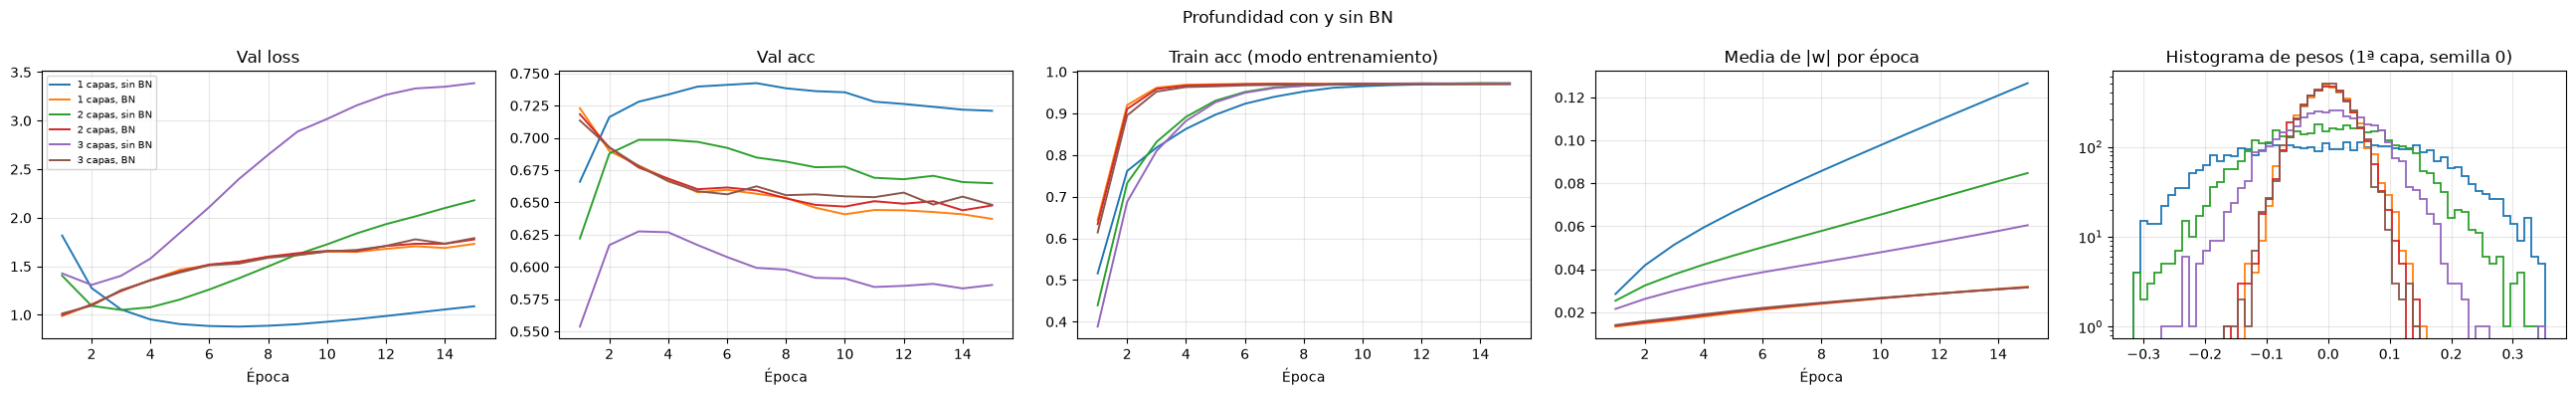

- Sin BN, pasar de 1 a 3 capas cambia la val acc en -12.5 puntos (0.7424 → 0.6169); con BN, en -1.0 puntos (0.7229 → 0.7134). Con 3 capas BN recupera accuracy (+9.7 puntos vs sin BN); aun así queda 2.9 puntos por debajo de la red de 1 capa sin BN.
- Brecha train−val con 3 capas: 35.6 (sin BN) vs 25.9 puntos (BN). Media de |w|: 0.0605 vs 0.0316. Ruido de la val loss: 0.0277 vs 0.0355.
- Tiempo por época con 3 capas: 2.3 s (sin BN) vs 2.5 s (BN) (tiempo de pared; el costo medido está en 4.11).

In [18]:
cfgs = []
for L in [1, 2, 3]:
    cfgs += [(f"{L} capas, sin BN", {**BASE, "hidden": [W0] * L}), (f"{L} capas, BN", {**BASE, "hidden": [W0] * L, "use_bn": True})]
rows_dp = collect("profundidad", cfgs); ALL_ROWS += rows_dp
a7 = agg(rows_dp, TARGET); display(a7.round(4))
plot_exp(rows_dp, [c[0] for c in cfgs], "tp3_profundidad", "Profundidad con y sin BN")
c1, c3, c3b = a7.loc["1 capas, sin BN"], a7.loc["3 capas, sin BN"], a7.loc["3 capas, BN"]
SUMMARY["depth"] = dict(loss_no_bn=c3.val_sel - c1.val_sel, loss_bn=c3b.val_sel - a7.loc["1 capas, BN"].val_sel)
display(Markdown(
    f"- Sin BN, pasar de 1 a 3 capas cambia la val acc en {pts(c3.val_sel - c1.val_sel)} puntos ({c1.val_sel:.4f} → {c3.val_sel:.4f}); con BN, en {pts(c3b.val_sel - a7.loc['1 capas, BN'].val_sel)} puntos ({a7.loc['1 capas, BN'].val_sel:.4f} → {c3b.val_sel:.4f}). "
    f"Con 3 capas BN {'recupera' if c3b.val_sel - c3.val_sel > SE_VAL else 'no recupera'} accuracy ({pts(c3b.val_sel - c3.val_sel)} puntos vs sin BN){'' if c3b.val_sel >= c1.val_sel - SE_VAL else '; aun así queda ' + pts(c1.val_sel - c3b.val_sel).lstrip('+-') + ' puntos por debajo de la red de 1 capa sin BN'}.\n"
    f"- Brecha train−val con 3 capas: {c3.gap * 100:.1f} (sin BN) vs {c3b.gap * 100:.1f} puntos (BN). Media de |w|: {c3.mean_abs_w:.4f} vs {c3b.mean_abs_w:.4f}. Ruido de la val loss: {c3.noise_val_loss:.4f} vs {c3b.noise_val_loss:.4f}.\n"
    f"- Tiempo por época con 3 capas: {c3.t_epoch:.1f} s (sin BN) vs {c3b.t_epoch:.1f} s (BN) (tiempo de pared; el costo medido está en 4.11)."))

## 4.8 Interacción entre dropout y BN

El apunte dice que BN **no se suele combinar con dropout** (hay un paper sobre la interferencia entre ambos). Como la búsqueda de Optuna los combina libremente, se mide el diseño 2×2.

  interaccion | ninguno                                | s0 | val 0.7428 | train(eval) 0.973 | mean|w| 0.1267 | 3.4s/ép
  interaccion | ninguno                                | s1 | val 0.7419 | train(eval) 0.973 | mean|w| 0.1264 | 2.3s/ép
  interaccion | dropout 0.35                           | s0 | val 0.7437 | train(eval) 0.969 | mean|w| 0.1033 | 3.0s/ép
  interaccion | dropout 0.35                           | s1 | val 0.7437 | train(eval) 0.969 | mean|w| 0.1029 | 3.0s/ép
  interaccion | BN                                     | s0 | val 0.7221 | train(eval) 0.972 | mean|w| 0.0320 | 2.0s/ép
  interaccion | BN                                     | s1 | val 0.7238 | train(eval) 0.972 | mean|w| 0.0319 | 2.0s/ép
  interaccion | BN + dropout 0.35                      | s0 | val 0.7092 | train(eval) 0.972 | mean|w| 0.0312 | 2.1s/ép
  interaccion | BN + dropout 0.35                      | s1 | val 0.7030 | train(eval) 0.972 | mean|w| 0.0313 | 2.1s/ép


,val_sel,val_max,val_last,train_acc_eval,gap,mean_abs_w,median_abs_w,max_abs_w,frac_lt_1e3,noise_val_loss,noise_val_acc,noise_train_acc,t_epoch,ep_sel,ep_target,t_target,val_sd,n_div
label,,,,,,,,,,,,,,,,,,
ninguno,0.7424,0.7424,0.7209,0.9727,0.2303,0.1266,0.1121,1.9198,0.0043,0.0060,0.0026,0.0023,2.8621,7.0,3.0,6.1077,0.0006,0
dropout 0.35,0.7437,0.7437,0.7327,0.9688,0.2251,0.1031,0.0889,1.6802,0.0057,0.0070,0.0018,0.0028,3.0129,9.0,3.5,11.4489,0.0000,0
BN,0.7229,0.7229,0.6372,0.9720,0.2491,0.0319,0.0266,0.5272,0.0203,0.0241,0.0041,0.0007,2.0087,1.0,1.0,2.1396,0.0012,0
BN + dropout 0.35,0.7061,0.7196,0.6622,0.9720,0.2659,0.0312,0.0260,0.4902,0.0208,0.0227,0.0029,0.0010,2.0665,2.0,1.0,2.0331,0.0044,0


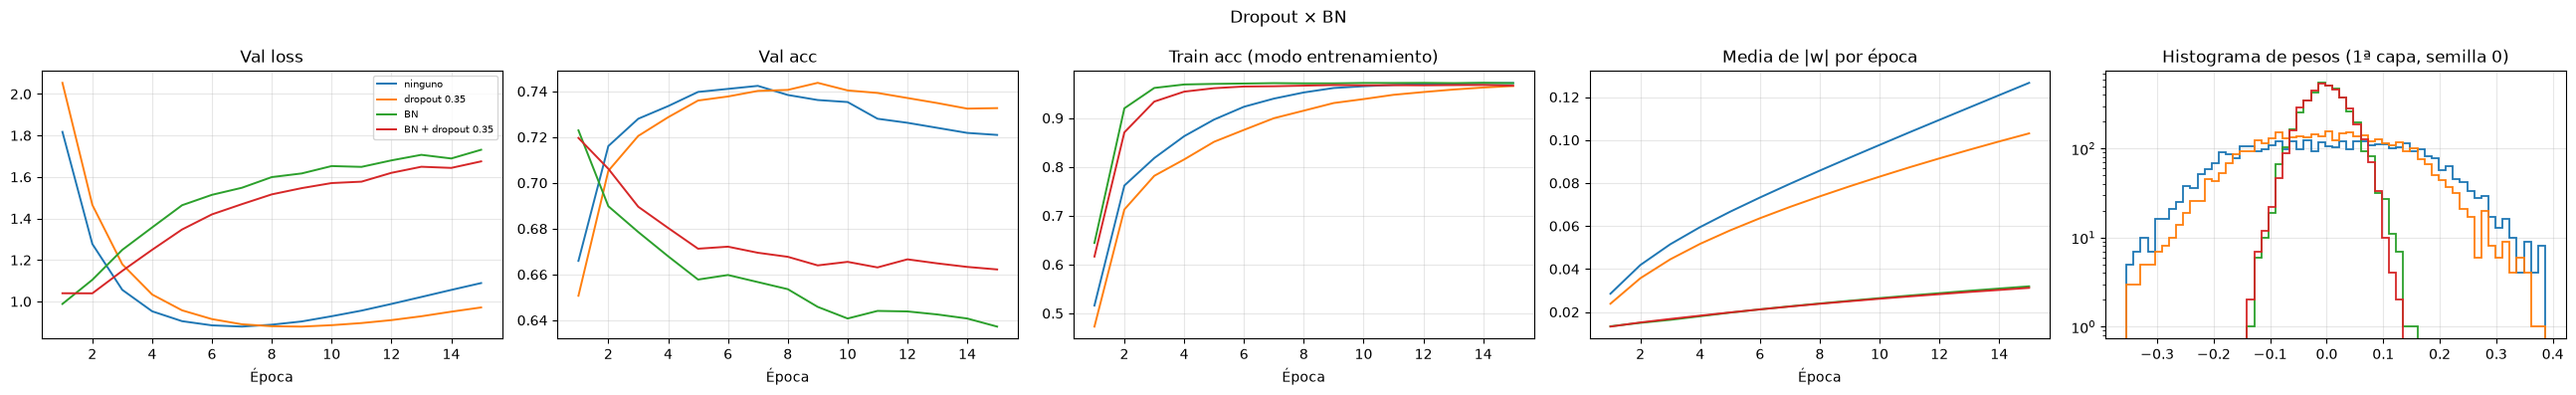

- Val acc: ninguno 0.7424; dropout 0.7437 (+0.1); BN 0.7229 (-1.9); ambos 0.7061 (-3.6). Si los efectos fueran aditivos se esperaría -1.8 puntos; el medido con ambos es -3.6: los efectos no se suman (interferencia / redundancia).
- Brecha train−val: 23.0 / 22.5 / 24.9 / 26.6 puntos. Ruido de la val loss: 0.0060 / 0.0070 / 0.0241 / 0.0227. Segundos por época: 2.9 / 3.0 / 2.0 / 2.1 (tiempo de pared; el costo medido está en 4.11).

In [19]:
cfgs = [("ninguno", {**BASE}), (f"dropout {p_best}", {**BASE, "dropout": p_best}), ("BN", {**BASE, "use_bn": True}),
        (f"BN + dropout {p_best}", {**BASE, "use_bn": True, "dropout": p_best})]
rows_ix = collect("interaccion", cfgs); ALL_ROWS += rows_ix
a8 = agg(rows_ix, TARGET); display(a8.round(4))
plot_exp(rows_ix, [c[0] for c in cfgs], "tp3_interaccion", "Dropout × BN")
n0, nd, nb_, nbd = (a8.iloc[i] for i in range(4))
efecto_aditivo = (nd.val_sel - n0.val_sel) + (nb_.val_sel - n0.val_sel)
SUMMARY["inter"] = dict(both=nbd.val_sel - n0.val_sel, additive=efecto_aditivo)
display(Markdown(
    f"- Val acc: ninguno {n0.val_sel:.4f}; dropout {nd.val_sel:.4f} ({pts(nd.val_sel - n0.val_sel)}); BN {nb_.val_sel:.4f} ({pts(nb_.val_sel - n0.val_sel)}); ambos {nbd.val_sel:.4f} ({pts(nbd.val_sel - n0.val_sel)}). "
    f"Si los efectos fueran aditivos se esperaría {pts(efecto_aditivo)} puntos; el medido con ambos es {pts(nbd.val_sel - n0.val_sel)}: "
    f"{'los efectos no se suman (interferencia / redundancia)' if abs(nbd.val_sel - n0.val_sel - efecto_aditivo) > SE_VAL else 'la diferencia respecto de la suma está dentro del error de la validación, no hay evidencia de interferencia en este problema'}.\n"
    f"- Brecha train−val: {n0.gap * 100:.1f} / {nd.gap * 100:.1f} / {nb_.gap * 100:.1f} / {nbd.gap * 100:.1f} puntos. Ruido de la val loss: {n0.noise_val_loss:.4f} / {nd.noise_val_loss:.4f} / {nb_.noise_val_loss:.4f} / {nbd.noise_val_loss:.4f}. "
    f"Segundos por época: {n0.t_epoch:.1f} / {nd.t_epoch:.1f} / {nb_.t_epoch:.1f} / {nbd.t_epoch:.1f} (tiempo de pared; el costo medido está en 4.11)."))

## 4.9 Escalado de features y regularización

La clase insiste en preprocesar (restar la media y dividir por el desvío) porque **λ es el mismo para todos los pesos**: si las features tienen escalas muy distintas, un mismo λ penaliza de forma desigual. Los vectores TF-IDF ya vienen con norma L2 = 1 por documento, pero cada palabra tiene una escala propia. Se compara el TF-IDF original contra dividir cada feature por su desvío (`std`), con y sin L2.

  escala     | tfidf, sin reg                         | s0 | val 0.7428 | train(eval) 0.973 | mean|w| 0.1267 | 3.4s/ép
  escala     | tfidf, sin reg                         | s1 | val 0.7419 | train(eval) 0.973 | mean|w| 0.1264 | 2.3s/ép
  escala     | std, sin reg                           | s0 | val 0.6995 | train(eval) 0.973 | mean|w| 0.0247 | 1.9s/ép
  escala     | std, sin reg                           | s1 | val 0.6889 | train(eval) 0.973 | mean|w| 0.0242 | 1.9s/ép
  escala     | tfidf, L2 λ=1e-6                       | s0 | val 0.7419 | train(eval) 0.973 | mean|w| 0.0843 | 3.4s/ép
  escala     | tfidf, L2 λ=1e-6                       | s1 | val 0.7397 | train(eval) 0.973 | mean|w| 0.0850 | 3.3s/ép
  escala     | std, L2 λ=1e-6                         | s0 | val 0.6969 | train(eval) 0.973 | mean|w| 0.0152 | 3.0s/ép
  escala     | std, L2 λ=1e-6                         | s1 | val 0.6933 | train(eval) 0.973 | mean|w| 0.0154 | 3.8s/ép


,val_sel,val_max,val_last,train_acc_eval,gap,mean_abs_w,median_abs_w,max_abs_w,frac_lt_1e3,noise_val_loss,noise_val_acc,noise_train_acc,t_epoch,ep_sel,ep_target,t_target,val_sd,n_div
label,,,,,,,,,,,,,,,,,,
"tfidf, sin reg",0.7424,0.7424,0.7209,0.9727,0.2303,0.1266,0.1121,1.9198,0.0043,0.0060,0.0026,0.0023,2.8621,7.0,3.0,6.1077,0.0006,0
"std, sin reg",0.6942,0.6980,0.6578,0.9735,0.2793,0.0245,0.0187,0.4099,0.0300,0.0103,0.0034,0.0002,1.9037,1.0,NaN,NaN,0.0075,0
"tfidf, L2 λ=1e-6",0.7408,0.7415,0.7141,0.9727,0.2319,0.0847,0.0636,1.9571,0.0361,0.0060,0.0021,0.0024,3.3397,7.0,3.0,10.2611,0.0016,0
"std, L2 λ=1e-6",0.6951,0.6971,0.6589,0.9734,0.2783,0.0153,0.0098,0.4211,0.1101,0.0246,0.0050,0.0003,3.3627,1.0,NaN,NaN,0.0025,0


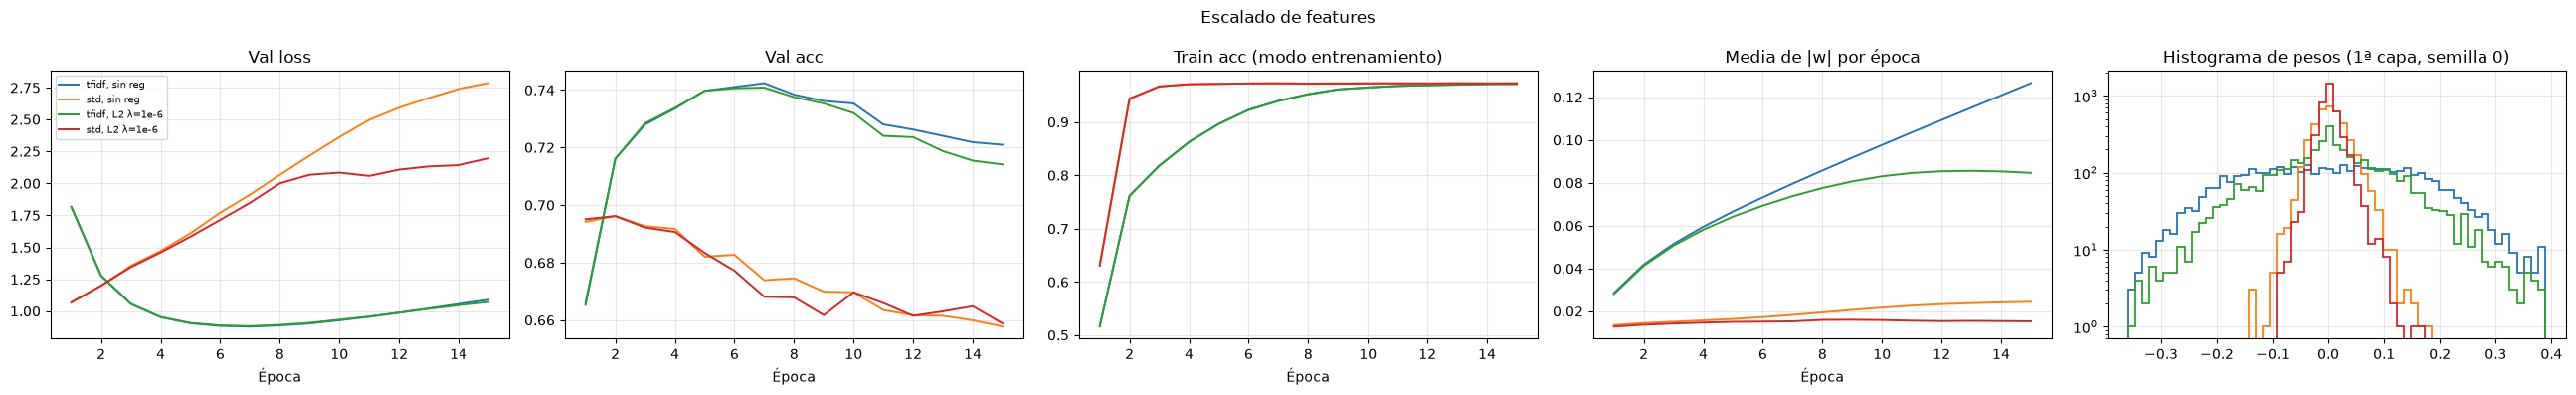

- Sin regularizar, `std` vs `tfidf`: 0.6942 vs 0.7424 (-4.8 puntos: empeora de forma apreciable). Con L2 (λ=1e-6): 0.6951 vs 0.7408 (-4.6 puntos: empeora de forma apreciable).
- El L2 respecto de la base de cada escala: tfidf -0.2 puntos, std +0.1 puntos. Media de |w|: tfidf 0.1266 → 0.0847; std 0.0245 → 0.0153. Brecha train−val: tfidf 23.0 → 23.2; std 27.9 → 27.8 puntos.
- Con `std` las palabras raras quedan con valores grandes (dividir por un desvío chico), por eso un mismo λ las penaliza distinto; el efecto neto (más o menos overfitting) es el que se ve en la brecha de arriba.

In [20]:
cfgs = [("tfidf, sin reg", {**BASE, "scaling": "tfidf"}), ("std, sin reg", {**BASE, "scaling": "std"}),
        (f"tfidf, L2 λ={sci(lam_best)}", {**BASE, "scaling": "tfidf", "l2": lam_best}), (f"std, L2 λ={sci(lam_best)}", {**BASE, "scaling": "std", "l2": lam_best})]
rows_sc = collect("escala", cfgs); ALL_ROWS += rows_sc
a9 = agg(rows_sc, TARGET); display(a9.round(4))
plot_exp(rows_sc, [c[0] for c in cfgs], "tp3_escala", "Escalado de features")
t0_, s0_, t1_, s1_ = (a9.iloc[i] for i in range(4))
SUMMARY["scale"] = dict(d_noreg=s0_.val_sel - t0_.val_sel, d_l2=s1_.val_sel - t1_.val_sel)
display(Markdown(
    f"- Sin regularizar, `std` vs `tfidf`: {s0_.val_sel:.4f} vs {t0_.val_sel:.4f} ({pts(s0_.val_sel - t0_.val_sel)} puntos: {veredicto(s0_.val_sel - t0_.val_sel)}). Con L2 (λ={sci(lam_best)}): {s1_.val_sel:.4f} vs {t1_.val_sel:.4f} ({pts(s1_.val_sel - t1_.val_sel)} puntos: {veredicto(s1_.val_sel - t1_.val_sel)}).\n"
    f"- El L2 respecto de la base de cada escala: tfidf {pts(t1_.val_sel - t0_.val_sel)} puntos, std {pts(s1_.val_sel - s0_.val_sel)} puntos. Media de |w|: tfidf {t0_.mean_abs_w:.4f} → {t1_.mean_abs_w:.4f}; std {s0_.mean_abs_w:.4f} → {s1_.mean_abs_w:.4f}. "
    f"Brecha train−val: tfidf {t0_.gap * 100:.1f} → {t1_.gap * 100:.1f}; std {s0_.gap * 100:.1f} → {s1_.gap * 100:.1f} puntos.\n"
    f"- Con `std` las palabras raras quedan con valores grandes (dividir por un desvío chico), por eso un mismo λ las penaliza distinto; el efecto neto (más o menos overfitting) es el que se ve en la brecha de arriba."))

## 4.10 Red grande ("sobredimensionar y regularizar")

Las recomendaciones de la clase para dropout empiezan por **usar una red grande**, y el ejemplo de L2 también sobredimensiona (500 neuronas). Se prueba una red de **1×512** sin regularizar, con dropout 0.5 y con L2, para ver cuánto aportan las técnicas cuando hay mucha más capacidad (en el TP2 esa red sin regularizar rindió igual que la de 64 unidades y tardó ~5 veces más).

  red_grande | 1×512 sin reg                          | s0 | val 0.7437 | train(eval) 0.973 | mean|w| 0.0729 | 12.7s/ép
  red_grande | 1×512 sin reg                          | s1 | val 0.7424 | train(eval) 0.973 | mean|w| 0.0725 | 11.5s/ép
  red_grande | 1×512 dropout 0.5                      | s0 | val 0.7415 | train(eval) 0.973 | mean|w| 0.0605 | 12.1s/ép
  red_grande | 1×512 dropout 0.5                      | s1 | val 0.7371 | train(eval) 0.973 | mean|w| 0.0605 | 12.8s/ép
  red_grande | 1×512 L2 λ=1e-6                        | s0 | val 0.7433 | train(eval) 0.973 | mean|w| 0.0259 | 21.7s/ép
  red_grande | 1×512 L2 λ=1e-6                        | s1 | val 0.7428 | train(eval) 0.972 | mean|w| 0.0257 | 23.2s/ép


,val_sel,val_max,val_last,train_acc_eval,gap,mean_abs_w,median_abs_w,max_abs_w,frac_lt_1e3,noise_val_loss,noise_val_acc,noise_train_acc,t_epoch,ep_sel,ep_target,t_target,val_sd,n_div
label,,,,,,,,,,,,,,,,,,
1×512 sin reg,0.7430,0.7430,0.7064,0.9735,0.2304,0.0727,0.0638,0.8004,0.0080,0.0047,0.0019,0.0010,12.1268,2.0,1.0,13.6881,0.0009,0
1×512 dropout 0.5,0.7393,0.7439,0.7159,0.9734,0.2341,0.0605,0.0521,0.8082,0.0097,0.0045,0.0012,0.0025,12.4720,4.0,1.0,12.5108,0.0031,0
1×512 L2 λ=1e-6,0.7430,0.7430,0.6913,0.9729,0.2298,0.0258,0.0148,1.2000,0.0811,0.0087,0.0024,0.0010,22.4277,2.0,1.0,26.4600,0.0003,0


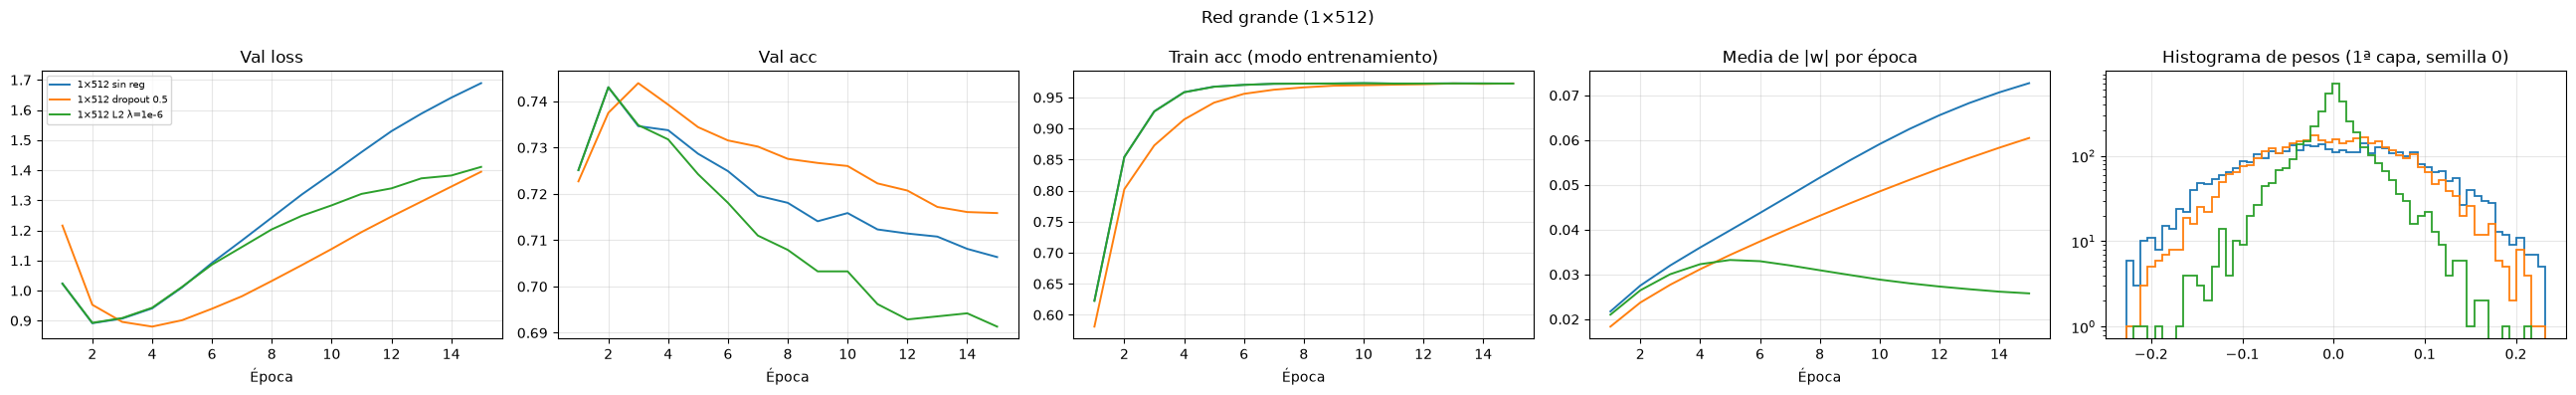

- Val acc: 1×512 sin reg 0.7430; con dropout 0.5 0.7393 (-0.4); con L2 0.7430 (+0.0). Frente a la red base de 64 unidades (0.7424): +0.1 sin reg y -0.3 con dropout 0.5.
- Brecha train−val: 23.0 / 23.4 / 23.0 puntos. Media de |w|: 0.0727 / 0.0605 / 0.0258. Segundos por época: 12.1 / 12.5 / 22.4 (vs 2.9 s de la red base de 64 unidades; tiempos de pared; el costo medido está en 4.11).

In [21]:
cfgs = [("1×512 sin reg", {**BASE, "hidden": [512]}), ("1×512 dropout 0.5", {**BASE, "hidden": [512], "dropout": 0.5}),
        (f"1×512 L2 λ={sci(lam_best)}", {**BASE, "hidden": [512], "l2": lam_best})]
rows_wd = collect("red_grande", cfgs); ALL_ROWS += rows_wd
a10 = agg(rows_wd, TARGET); display(a10.round(4))
plot_exp(rows_wd, [c[0] for c in cfgs], "tp3_red_grande", "Red grande (1×512)")
g0, gd, gl = (a10.iloc[i] for i in range(3))
display(Markdown(
    f"- Val acc: 1×512 sin reg {g0.val_sel:.4f}; con dropout 0.5 {gd.val_sel:.4f} ({pts(gd.val_sel - g0.val_sel)}); con L2 {gl.val_sel:.4f} ({pts(gl.val_sel - g0.val_sel)}). "
    f"Frente a la red base de {W0} unidades ({REF.val_sel:.4f}): {pts(g0.val_sel - REF.val_sel)} sin reg y {pts(gd.val_sel - REF.val_sel)} con dropout 0.5.\n"
    f"- Brecha train−val: {g0.gap * 100:.1f} / {gd.gap * 100:.1f} / {gl.gap * 100:.1f} puntos. Media de |w|: {g0.mean_abs_w:.4f} / {gd.mean_abs_w:.4f} / {gl.mean_abs_w:.4f}. "
    f"Segundos por época: {g0.t_epoch:.1f} / {gd.t_epoch:.1f} / {gl.t_epoch:.1f} (vs {REF.t_epoch:.1f} s de la red base de {W0} unidades; tiempos de pared; el costo medido está en 4.11)."))

## 4.11 Costo en tiempo de cada técnica, medido con las variantes intercaladas

Los segundos por época de las secciones anteriores salen de corridas **secuenciales** en una máquina que puede estar haciendo otras cosas, y por eso son ruidosos (se muestra abajo cuánto varía el mismo modelo). Para medir el costo de cada técnica se hace otra cosa: se arma cada variante, y se toma el tiempo de unos pasos de entrenamiento **intercalando las variantes** (una repetición de cada una, y se repite todo varias veces), con los mismos batches. Se reporta la **mediana**, el mínimo y el máximo de las repeticiones. Un costo solo se considera real si supera el 10 % tanto con la mediana como con el mínimo de las repeticiones (el mínimo descarta los picos de carga de la máquina).

In [22]:
fkey_b = tuple(BASE["key"]) + (BASE["scaling"],)
Xb, yb_, _, _ = get_dense_split(*fkey_b)
BS_B, N_PRE, REPS = BASE["batch_size"], 40, 7
g_ = torch.Generator(); g_.manual_seed(0)
perm_ = torch.randperm(len(Xb), generator=g_)[: N_PRE * BS_B]
BATCHES = [(Xb[perm_[i * BS_B:(i + 1) * BS_B]].clone(), yb_[perm_[i * BS_B:(i + 1) * BS_B]].clone()) for i in range(N_PRE)]
crit_b = nn.CrossEntropyLoss()

def make_bench(extra):
    c = {**DEFAULT_CFG, **BASE, **extra}
    torch.manual_seed(0)
    model = MLP(Xb.shape[1], NUM_CLASSES, c["hidden"], c["activation"], c["dropout"], c["input_dropout"], c["use_bn"], c["bn_momentum"]).to(device)
    opt = build_optimizer(c["opt"], model.parameters(), c["lr"], momentum=c["momentum"])
    model.train()
    return c, model, opt, (make_maxnorm(c["maxnorm"]) if c["maxnorm"] else None)

def ms_per_step(state, n):
    c, model, opt, post = state
    t0 = time.perf_counter()
    for i in range(n):
        xb, yb = BATCHES[i % N_PRE]
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        logits = model(xb); ce = crit_b(logits, yb)
        loss = ce + reg_penalty(model, c["l1"], c["l2"]) if (c["l1"] > 0 or c["l2"] > 0) else ce
        loss.backward(); opt.step()
        if post is not None:
            post(model)
        ce.item(); (logits.argmax(1) == yb).sum().item()   # igual que en train_mlp
    return (time.perf_counter() - t0) / n * 1000

S_ = SUMMARY
lam2_, lam1_, pdo_ = S_["l2"]["lam"], S_["l1"]["lam"], S_["dropout"]["p"]
BENCH = [("base", {}, "base", 100), (f"L2 λ={sci(lam2_)}", {"l2": lam2_}, "base", 100), (f"L1 λ={sci(lam1_)}", {"l1": lam1_}, "base", 100),
         (f"L1+L2", {"l1": lam1_, "l2": lam2_}, "base", 100), (f"dropout {pdo_}", {"dropout": pdo_}, "base", 100),
         ("BN", {"use_bn": True}, "base", 100), ("max-norm c=4", {"maxnorm": 4.0}, "base", 100),
         ("1×512 base", {"hidden": [512]}, "1×512 base", 40), (f"1×512 + L2 λ={sci(lam2_)}", {"hidden": [512], "l2": lam2_}, "1×512 base", 40),
         (f"1×512 + dropout {pdo_}", {"hidden": [512], "dropout": pdo_}, "1×512 base", 40)]
states = {lab: make_bench(ex) for lab, ex, _, _ in BENCH}
for lab, ex, _, n in BENCH:
    ms_per_step(states[lab], 10)                                  # calentamiento
meas = {lab: [] for lab, *_ in BENCH}
for rep_ in range(REPS):                                          # variantes intercaladas
    for lab, ex, ref, n in BENCH:
        meas[lab].append(ms_per_step(states[lab], n))
n_steps_ep = math.ceil(len(Xb) / BS_B)
rows_t = []
for lab, ex, ref, n in BENCH:
    m = np.array(meas[lab]); mr = np.array(meas[ref])
    rows_t.append(dict(variante=lab, referencia=ref, ms_por_paso=np.median(m), minimo=m.min(), maximo=m.max(),
                       dispersion=(m.max() - m.min()) / np.median(m), s_por_epoca_equiv=np.median(m) * n_steps_ep / 1000,
                       costo_vs_ref=np.median(m) / np.median(mr) - 1, costo_min=m.min() / mr.min() - 1,
                       disp_ref=(mr.max() - mr.min()) / np.median(mr)))
tt = pd.DataFrame(rows_t).set_index("variante")
# real: supera el 10 % con la mediana Y con el mínimo (el mínimo descarta los picos de carga de la máquina) y con el mismo signo
tt["real"] = (tt.costo_vs_ref.abs() > 0.10) & (tt.costo_min.abs() > 0.10) & (np.sign(tt.costo_vs_ref) == np.sign(tt.costo_min)) & (tt.referencia != tt.index)
tt.round(3).to_csv("results/tp3_costo_tiempo.csv")
display(tt[["ms_por_paso", "minimo", "maximo", "s_por_epoca_equiv", "costo_vs_ref", "costo_min", "dispersion", "real"]].round(3))

base_rows = [r for r in ALL_ROWS if str(r["label"]).startswith("base")]
ruido_txt = ""
if len(base_rows) >= 2:
    tb = sorted({(r["seed"], round(r["t_epoch"], 1)) for r in base_rows})
    ruido_txt = ("- **Ruido de los tiempos de las secciones anteriores:** el mismo modelo base tardó " + " y ".join(f"{t:.1f} s (semilla {s})" for s, t in tb[:2]) + " por época; "
                 "diferencias de ese tamaño entre configuraciones no se pueden atribuir a una técnica.\n")
parts = []
for lab, r in tt.iterrows():
    if r.referencia == lab:
        continue
    parts.append(f"{lab} {r.costo_vs_ref * 100:+.0f} % (mínimo {r.costo_min * 100:+.0f} %)" + ("" if r.real else ", dentro del ruido"))
resumen = "; ".join(parts) + f". Referencias: base {tt.loc['base', 'ms_por_paso']:.1f} ms/paso (≈{tt.loc['base', 's_por_epoca_equiv']:.1f} s por época), 1×512 base {tt.loc['1×512 base', 'ms_por_paso']:.1f} ms/paso."
SUMMARY["time"] = dict(resumen=resumen)
display(Markdown(ruido_txt + "- **Costo de cada técnica** (mediana de " + str(REPS) + " repeticiones intercaladas, contra la misma red sin la técnica): " + resumen +
                 "\n- Se marca como real solo un costo mayor al 10 % tanto con la mediana como con el mínimo de las repeticiones (el mínimo descarta los picos de carga de la máquina) y con el mismo signo. La penalización L1/L2 recorre todos los pesos en cada paso (su costo crece con el número de parámetros: compararlo en 1×64 y en 1×512); dropout agrega una máscara por capa; BN agrega la normalización por batch y sus parámetros γ y β; max-norm agrega la proyección de las filas después de cada paso."))

,ms_por_paso,minimo,maximo,s_por_epoca_equiv,costo_vs_ref,costo_min,dispersion,real
variante,,,,,,,,
base,8.624,8.289,9.301,2.441,0.000,0.000,0.117,False
L2 λ=1e-6,12.689,10.878,15.467,3.591,0.471,0.312,0.362,True
L1 λ=1e-6,10.176,9.978,10.665,2.880,0.180,0.204,0.068,True
L1+L2,13.552,13.319,13.824,3.835,0.571,0.607,0.037,True
dropout 0.35,8.781,8.598,8.875,2.485,0.018,0.037,0.032,False
BN,9.031,8.842,9.611,2.556,0.047,0.067,0.085,False
max-norm c=4,9.390,9.138,10.053,2.657,0.089,0.102,0.097,False
1×512 base,48.861,48.349,58.374,13.828,0.000,0.000,0.205,False
1×512 + L2 λ=1e-6,82.122,75.768,107.278,23.241,0.681,0.567,0.384,True


- **Ruido de los tiempos de las secciones anteriores:** el mismo modelo base tardó 3.4 s (semilla 0) y 2.3 s (semilla 1) por época; diferencias de ese tamaño entre configuraciones no se pueden atribuir a una técnica.
- **Costo de cada técnica** (mediana de 7 repeticiones intercaladas, contra la misma red sin la técnica): L2 λ=1e-6 +47 % (mínimo +31 %); L1 λ=1e-6 +18 % (mínimo +20 %); L1+L2 +57 % (mínimo +61 %); dropout 0.35 +2 % (mínimo +4 %), dentro del ruido; BN +5 % (mínimo +7 %), dentro del ruido; max-norm c=4 +9 % (mínimo +10 %), dentro del ruido; 1×512 + L2 λ=1e-6 +68 % (mínimo +57 %); 1×512 + dropout 0.35 +9 % (mínimo +2 %), dentro del ruido. Referencias: base 8.6 ms/paso (≈2.4 s por época), 1×512 base 48.9 ms/paso.
- Se marca como real solo un costo mayor al 10 % tanto con la mediana como con el mínimo de las repeticiones (el mínimo descarta los picos de carga de la máquina) y con el mismo signo. La penalización L1/L2 recorre todos los pesos en cada paso (su costo crece con el número de parámetros: compararlo en 1×64 y en 1×512); dropout agrega una máscara por capa; BN agrega la normalización por batch y sus parámetros γ y β; max-norm agrega la proyección de las filas después de cada paso.

# 5. Búsqueda **sin** regularización con el mismo presupuesto

Para saber si incluir la regularización como hiperparámetro **mejora la búsqueda** hay que comparar contra una búsqueda que no la tiene, con **el mismo presupuesto** (mismo número de trials, sampler, semilla, pruner, épocas, split y `objective`) para no repetir la asimetría de presupuestos que se observó en el TP2. El estudio sin regularización tiene exactamente el mismo espacio de búsqueda, pero con `reg_type = none`, `dropout = 0` y sin BN (estos tres no se sugieren).

tp3_sin_regularizacion: ya registrado en MLflow (TP3_busqueda)


,trials,podados,mejor_val,mejor_val_ultima_epoca,promedio_top5,mediana_completos,completos_con_val_ge_070,t_epoch_med
con regularización,30,30%,0.742377,0.739284,0.741935,0.699072,10,2.217721
sin regularización,30,37%,0.737958,0.737958,0.732656,0.694211,9,4.276041


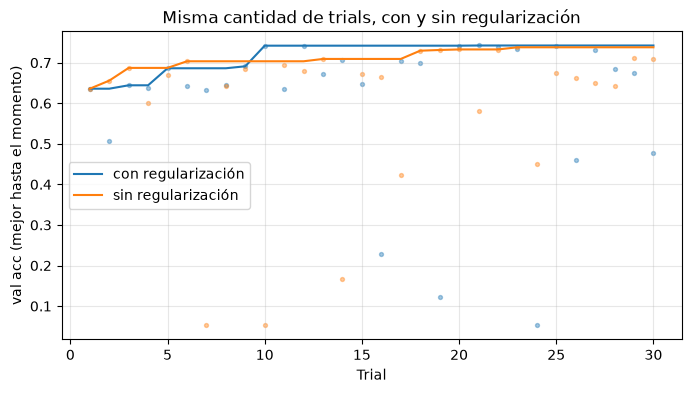

- Con **30** trials en cada estudio, la mejor val acc es **0.7424** con regularización y **0.7380** sin ella: diferencia de +0.4 puntos (diferencia dentro del error de la validación). El promedio de los 5 mejores trials es 0.7419 vs 0.7327 (+0.9 puntos).
- Mejor trial sin regularización: #22 (1×128 elu, adam lr 0.00038, features `tfidf`, media de |w| 0.0573). Su val acc en la última época es 0.7380, contra 0.7393 del mejor con regularización: a la última época no hay diferencia apreciable.
- Trials completos con val ≥ 0.70: 10 (con) vs 9 (sin); trials podados: 30% vs 37%. Mediana de val acc de los completos: 0.6991 vs 0.6942. Esta última comparación depende del tamaño del espacio: el estudio con regularización tiene más dimensiones, y 30 trials cubren menos cada una.
- Segundos por época (mediana de los trials): 2.2 vs 4.3 (los tiempos tienen ruido y las arquitecturas de los trials difieren entre estudios: no se interpreta como costo de la regularización).

In [23]:
study_noreg = run_study(get_study("tp3_sin_regularizacion"), False)
log_study_to_mlflow(study_noreg, "TP3_busqueda")
mlflow.set_experiment("TP3_controlados")

Tn = trials_table(study_noreg)
def resumen_estudio(Tx, st):
    comp = Tx[Tx.estado == "COMPLETE"]
    return dict(trials=len(Tx), podados=f"{(Tx.estado == 'PRUNED').mean():.0%}", mejor_val=st.best_value, mejor_val_ultima_epoca=st.best_trial.user_attrs["val_last"],
                promedio_top5=Tx.nlargest(5, "val").val.mean(), mediana_completos=comp.val.median(),
                completos_con_val_ge_070=int((comp.val >= 0.70).sum()), t_epoch_med=Tx.t_epoch.median())
cmp_df = pd.DataFrame({"con regularización": resumen_estudio(T, study_reg), "sin regularización": resumen_estudio(Tn, study_noreg)}).T
display(cmp_df)
fig, ax = plt.subplots(figsize=(8, 4))
for nm, Tx in [("con regularización", T), ("sin regularización", Tn)]:
    d = Tx.sort_values("trial"); ax.plot(range(1, len(d) + 1), d.val.cummax(), label=nm); ax.scatter(range(1, len(d) + 1), d.val, s=8, alpha=.4)
ax.set_xlabel("Trial"); ax.set_ylabel("val acc (mejor hasta el momento)"); ax.legend(); ax.grid(alpha=.3); ax.set_title("Misma cantidad de trials, con y sin regularización")
plt.savefig("figures/tp3_busqueda_con_vs_sin.png", dpi=130); plt.show()

dbest = study_reg.best_value - study_noreg.best_value
dtop5 = cmp_df.loc["con regularización", "promedio_top5"] - cmp_df.loc["sin regularización", "promedio_top5"]
SUMMARY["budget"] = dict(dbest=dbest, dtop5=dtop5)
bn_ = study_noreg.best_params; bnp = Tn[Tn.trial == study_noreg.best_trial.number].iloc[0]
display(Markdown(
    f"- Con **{len(T)}** trials en cada estudio, la mejor val acc es **{study_reg.best_value:.4f}** con regularización y **{study_noreg.best_value:.4f}** sin ella: diferencia de {pts(dbest)} puntos ({veredicto(dbest)}). "
    f"El promedio de los 5 mejores trials es {cmp_df.loc['con regularización', 'promedio_top5']:.4f} vs {cmp_df.loc['sin regularización', 'promedio_top5']:.4f} ({pts(dtop5)} puntos).\n"
    f"- Mejor trial sin regularización: #{study_noreg.best_trial.number} ({bnp.capas}×{bnp.unidades} {bnp.act}, {bnp.opt} lr {bnp.lr:.2g}, features `{bnp.escala}`, media de |w| {bnp.mean_abs_w:.4f}). "
    f"Su val acc en la última época es {study_noreg.best_trial.user_attrs['val_last']:.4f}, contra {study_reg.best_trial.user_attrs['val_last']:.4f} del mejor con regularización: "
    f"{'la regularización sostiene mejor la accuracy hasta la época 15' if study_reg.best_trial.user_attrs['val_last'] - study_noreg.best_trial.user_attrs['val_last'] > SE_VAL else 'a la última época no hay diferencia apreciable'}.\n"
    f"- Trials completos con val ≥ 0.70: {cmp_df.loc['con regularización', 'completos_con_val_ge_070']} (con) vs {cmp_df.loc['sin regularización', 'completos_con_val_ge_070']} (sin); trials podados: {cmp_df.loc['con regularización', 'podados']} vs {cmp_df.loc['sin regularización', 'podados']}. "
    f"Mediana de val acc de los completos: {cmp_df.loc['con regularización', 'mediana_completos']:.4f} vs {cmp_df.loc['sin regularización', 'mediana_completos']:.4f}. "
    f"Esta última comparación depende del tamaño del espacio: el estudio con regularización tiene más dimensiones, y {len(T)} trials cubren menos cada una.\n"
    f"- Segundos por época (mediana de los trials): {cmp_df.loc['con regularización', 't_epoch_med']:.1f} vs {cmp_df.loc['sin regularización', 't_epoch_med']:.1f} (los tiempos tienen ruido y las arquitecturas de los trials difieren entre estudios: no se interpreta como costo de la regularización)."))

# 6. Selección de épocas, entrenamiento final y test

**Selección de épocas con validación.** Para cada una de las dos mejores configuraciones (con y sin regularización) se entrena **30 épocas** sobre el mismo split train/validación y se elige la **época de mínima val loss**. El test no interviene en esta decisión. Las configuraciones regularizadas suelen necesitar más épocas (clase de dropout), así que se deja que cada una tenga las suyas en vez de forzar 15 para ambas.

**Entrenamiento final.** Con esas épocas, se reentrena sobre **todo el train** (`val_loader=None`; TF-IDF y escalado ajustados con todo el train) con **5 semillas** y se evalúa en **test una sola vez por semilla**. Las comparaciones usan las mismas semillas para ambos modelos.

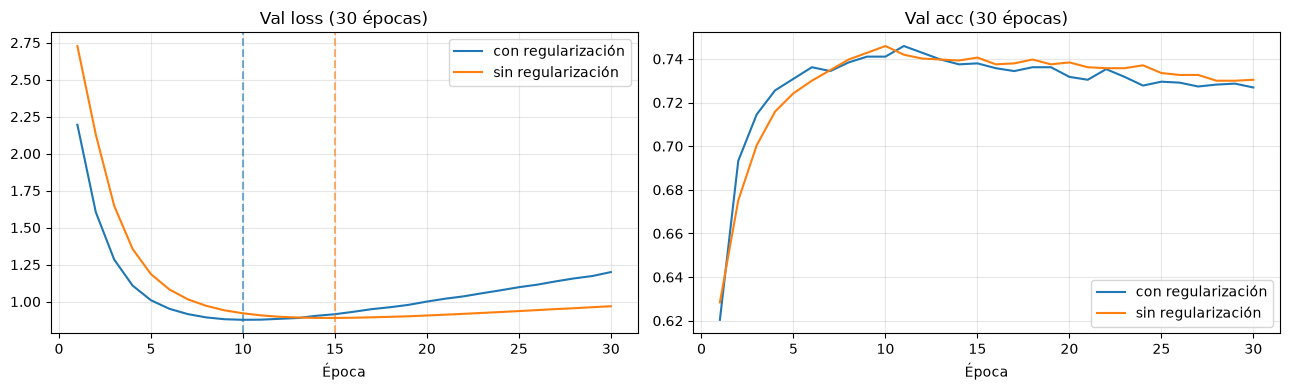

,ep_min_val_loss,val_acc_en_ese_ep,val_acc_ep15,val_acc_max,ep_val_acc_max,val_loss_min,val_loss_ep30,ruido_val_loss,t_epoch
modelo,,,,,,,,,
con regularización,10,0.7411,0.7380,0.7459,11,0.8770,1.1996,0.0055,2.0084
sin regularización,15,0.7406,0.7406,0.7459,10,0.8895,0.9686,0.0083,2.4112


- **con regularización:** mínimo de val loss en la época **10** (val acc 0.7411); a la época 15 la val acc es 0.7380 (-0.3 puntos: diferencia dentro del error de la validación); máxima val acc 0.7459 en la época 11. Val loss en la época 30: 1.200 contra el mínimo 0.877.
- **sin regularización:** mínimo de val loss en la época **15** (val acc 0.7406); a la época 15 la val acc es 0.7406 (+0.0 puntos: diferencia dentro del error de la validación); máxima val acc 0.7459 en la época 10. Val loss en la época 30: 0.969 contra el mínimo 0.890.


In [24]:
cfg_reg = {**DEFAULT_CFG, **cfg_from_params(study_reg.best_params)}
cfg_noreg = {**DEFAULT_CFG, **cfg_from_params(study_noreg.best_params)}
MODELOS = {"con regularización": cfg_reg, "sin regularización": cfg_noreg}

sel_rows = {nm: run_cfg(cfg, 0, EPOCHS_SEL, f"selección {nm}", "seleccion") for nm, cfg in MODELOS.items()}
EPOCHS_FINAL, filas = {}, []
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for nm, r in sel_rows.items():
    vl, va = np.array(r["hist"]["val_loss"]), np.array(r["hist"]["val_acc"])
    EPOCHS_FINAL[nm] = int(np.argmin(vl)) + 1
    ax[0].plot(range(1, len(vl) + 1), vl, label=nm); ax[0].axvline(EPOCHS_FINAL[nm], ls="--", color=ax[0].lines[-1].get_color(), alpha=.6)
    ax[1].plot(range(1, len(va) + 1), va, label=nm)
    filas.append(dict(modelo=nm, ep_min_val_loss=EPOCHS_FINAL[nm], val_acc_en_ese_ep=va[EPOCHS_FINAL[nm] - 1], val_acc_ep15=va[min(14, len(va) - 1)], val_acc_max=va.max(), ep_val_acc_max=int(va.argmax()) + 1,
                      val_loss_min=vl.min(), val_loss_ep30=vl[-1], ruido_val_loss=r["noise_val_loss"], t_epoch=r["t_epoch"]))
for a_, t_ in zip(ax, ["Val loss (30 épocas)", "Val acc (30 épocas)"]):
    a_.set_title(t_); a_.set_xlabel("Época"); a_.grid(alpha=.3); a_.legend()
plt.tight_layout(); plt.savefig("figures/tp3_seleccion_epocas.png", dpi=130); plt.show()
sel_df = pd.DataFrame(filas).set_index("modelo"); display(sel_df.round(4))
txt = "".join(f"- **{nm}:** mínimo de val loss en la época **{int(r.ep_min_val_loss)}** (val acc {r.val_acc_en_ese_ep:.4f}); a la época 15 la val acc es {r.val_acc_ep15:.4f} ({pts(r.val_acc_ep15 - r.val_acc_en_ese_ep)} puntos: {veredicto(r.val_acc_ep15 - r.val_acc_en_ese_ep)}); máxima val acc {r.val_acc_max:.4f} en la época {int(r.ep_val_acc_max)}. Val loss en la época 30: {r.val_loss_ep30:.3f} contra el mínimo {r.val_loss_min:.3f}.\n" for nm, r in sel_df.iterrows())
display(Markdown(txt))

In [25]:
def final_fit(cfg, epochs, seed, label):
    c = {**DEFAULT_CFG, **cfg}
    fkey = tuple(c["key"]) + (c["scaling"],)
    Xtr, ytr, Xte, yte = get_full_dense(*fkey)
    torch.manual_seed(seed); g = torch.Generator(); g.manual_seed(seed)
    tr = DataLoader(TensorDataset(Xtr, ytr), batch_size=c["batch_size"], shuffle=True, generator=g)
    te = DataLoader(TensorDataset(Xte, yte), batch_size=1024, shuffle=False)
    model = MLP(Xtr.shape[1], NUM_CLASSES, c["hidden"], c["activation"], c["dropout"], c["input_dropout"], c["use_bn"], c["bn_momentum"])
    opt = build_optimizer(c["opt"], model.parameters(), c["lr"], momentum=c["momentum"])
    safe = re.sub(r"[^A-Za-z0-9_.=+-]", "_", f"{label}_s{seed}")
    writer = SummaryWriter(f"{TB_DIR}/final/{safe}")
    with mlflow.start_run(run_name=f"final | {label} | s{seed}"):
        mlflow.log_params({k: str(v) for k, v in c.items()}); mlflow.log_params({"seed": seed, "epochs": epochs})
        t0 = time.time()
        h = train_mlp(model, tr, None, opt, epochs, writer=writer, run_name=safe, log_mlflow=True, l1=c["l1"], l2=c["l2"])   # sin mirar ningún conjunto
        t = time.time() - t0
        crit = nn.CrossEntropyLoss()
        tr_loss, tr_acc = evaluate(model, tr, crit)
        model.eval(); preds = []
        with torch.no_grad():                                   # única evaluación en test de esta semilla
            for xb, _ in te:
                preds.extend(model(xb.to(device)).argmax(1).cpu().numpy())
        preds = np.array(preds); acc = accuracy_score(yte.numpy(), preds); ws = weight_stats(model)
        mlflow.log_metrics({"test_acc": acc, "train_acc_eval": tr_acc, "tiempo_s": t, "mean_abs_w": ws["mean_abs_w"], "frac_lt_1e3": ws["frac_lt_1e3"]})
    writer.add_scalar("final/test_acc", acc, epochs); writer.close()
    return dict(acc=acc, preds=preds, y=yte.numpy(), time=t, train_acc=tr_acc, t_epoch=float(np.mean(h["epoch_time"])), mean_abs_w=ws["mean_abs_w"], frac_lt_1e3=ws["frac_lt_1e3"])

FINAL = {nm: [final_fit(cfg, EPOCHS_FINAL[nm], s, nm) for s in FINAL_SEEDS] for nm, cfg in MODELOS.items()}
for nm, rs in FINAL.items():
    print(f"{nm:20s} épocas={EPOCHS_FINAL[nm]:2d} | test acc por semilla: " + ", ".join(f"{r['acc']:.4f}" for r in rs))

con regularización   épocas=10 | test acc por semilla: 0.6869, 0.6876, 0.6888, 0.6859, 0.6867
sin regularización   épocas=15 | test acc por semilla: 0.6802, 0.6767, 0.6751, 0.6794, 0.6766


In [26]:
# Referencia: resultados del TP2 (corrida del autor; mismo test, 5 semillas) solo como contexto, no se usan para decidir nada
TP2_REF = {"MLP del TP2 (5 semillas)": 0.6848, "Softmax del TP2 con presupuesto igual (5 semillas)": 0.6749, "Softmax del TP1 (5 semillas)": 0.6614}
SE_TEST = (0.68 * 0.32 / len(newsgroups_test.target)) ** 0.5
res_df = pd.DataFrame({nm: dict(epocas=EPOCHS_FINAL[nm], test_acc_media=np.mean([r["acc"] for r in rs]), test_acc_desvio=np.std([r["acc"] for r in rs], ddof=1),
                                min=min(r["acc"] for r in rs), max=max(r["acc"] for r in rs), train_acc_eval=np.mean([r["train_acc"] for r in rs]),
                                brecha_train_test=np.mean([r["train_acc"] - r["acc"] for r in rs]), mean_abs_w=np.mean([r["mean_abs_w"] for r in rs]),
                                frac_pesos_lt_1e3=np.mean([r["frac_lt_1e3"] for r in rs]), s_por_epoca=np.mean([r["t_epoch"] for r in rs]),
                                tiempo_total_s=np.mean([r["time"] for r in rs])) for nm, rs in FINAL.items()}).T
display(res_df.round(4)); res_df.to_csv("results/tp3_final.csv")

A, B = FINAL["con regularización"], FINAL["sin regularización"]
dm = res_df.loc["con regularización", "test_acc_media"] - res_df.loc["sin regularización", "test_acc_media"]
pareadas = [a_["acc"] - b_["acc"] for a_, b_ in zip(A, B)]
a0, b0 = A[0], B[0]
ok_a, ok_b = a0["preds"] == a0["y"], b0["preds"] == b0["y"]
n01, n10 = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
p_mc = binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 > 0 else 1.0
SUMMARY["final"] = dict(dm=dm, p=p_mc)
display(Markdown(
    f"- **Test (5 semillas):** con regularización **{res_df.loc['con regularización', 'test_acc_media']:.4f} ± {res_df.loc['con regularización', 'test_acc_desvio']:.4f}**, sin regularización **{res_df.loc['sin regularización', 'test_acc_media']:.4f} ± {res_df.loc['sin regularización', 'test_acc_desvio']:.4f}**; "
    f"diferencia {pts(dm)} puntos. El error estándar del test es de ≈ ±{SE_TEST * 100:.1f} puntos y el desvío entre semillas no incluye esa incertidumbre. "
    f"La diferencia pareada por semilla va de {min(pareadas) * 100:+.2f} a {max(pareadas) * 100:+.2f} puntos ({sum(p_ > 0 for p_ in pareadas)} de 5 semillas a favor de la regularización).\n"
    f"- **Prueba de McNemar** sobre las predicciones de la semilla 0 (mismos documentos de test): {n01} documentos solo los acierta el modelo regularizado, {n10} solo el no regularizado; p = {p_mc:.3f} "
    f"({'la diferencia es estadísticamente significativa' if p_mc < 0.05 else 'no se puede descartar que la diferencia sea por azar'}).\n"
    f"- **Contexto (TP2, mismo test):** " + "; ".join(f"{k} {v:.4f}" for k, v in TP2_REF.items()) + ".\n"
    f"- **Validación → test:** la val acc del mejor trial con regularización fue {study_reg.best_value:.4f} y el test {res_df.loc['con regularización', 'test_acc_media']:.4f} (caída de {(study_reg.best_value - res_df.loc['con regularización', 'test_acc_media']) * 100:.1f} puntos); "
    f"sin regularización {study_noreg.best_value:.4f} → {res_df.loc['sin regularización', 'test_acc_media']:.4f} ({(study_noreg.best_value - res_df.loc['sin regularización', 'test_acc_media']) * 100:.1f} puntos). "
    f"En el TP2 la caída también fue de ~5 puntos; la sobrestimación de la validación es parcialmente selección (se eligió el mejor entre {N_TRIALS} trials) y parcialmente una distribución de test algo distinta (no verificado).\n"
    f"- **Tiempo:** {res_df.loc['con regularización', 'tiempo_total_s']:.0f} s de entrenamiento final con regularización ({res_df.loc['con regularización', 's_por_epoca']:.1f} s por época × {EPOCHS_FINAL['con regularización']} épocas) vs {res_df.loc['sin regularización', 'tiempo_total_s']:.0f} s sin ({res_df.loc['sin regularización', 's_por_epoca']:.1f} s por época × {EPOCHS_FINAL['sin regularización']} épocas). Las dos redes pueden diferir en arquitectura, optimizador y épocas y los segundos tienen ruido: es lo que tardó cada entrenamiento final, no el costo de la regularización."))

,epocas,test_acc_media,test_acc_desvio,min,max,train_acc_eval,brecha_train_test,mean_abs_w,frac_pesos_lt_1e3,s_por_epoca,tiempo_total_s
con regularización,10.0,0.6872,0.0011,0.6859,0.6888,0.9355,0.2483,0.0819,0.0076,3.3446,34.2634
sin regularización,15.0,0.6776,0.0021,0.6751,0.6802,0.9681,0.2905,0.0608,0.0087,3.9777,60.9362


- **Test (5 semillas):** con regularización **0.6872 ± 0.0011**, sin regularización **0.6776 ± 0.0021**; diferencia +1.0 puntos. El error estándar del test es de ≈ ±0.5 puntos y el desvío entre semillas no incluye esa incertidumbre. La diferencia pareada por semilla va de +0.65 a +1.37 puntos (5 de 5 semillas a favor de la regularización).
- **Prueba de McNemar** sobre las predicciones de la semilla 0 (mismos documentos de test): 395 documentos solo los acierta el modelo regularizado, 344 solo el no regularizado; p = 0.066 (no se puede descartar que la diferencia sea por azar).
- **Contexto (TP2, mismo test):** MLP del TP2 (5 semillas) 0.6848; Softmax del TP2 con presupuesto igual (5 semillas) 0.6749; Softmax del TP1 (5 semillas) 0.6614.
- **Validación → test:** la val acc del mejor trial con regularización fue 0.7424 y el test 0.6872 (caída de 5.5 puntos); sin regularización 0.7380 → 0.6776 (6.0 puntos). En el TP2 la caída también fue de ~5 puntos; la sobrestimación de la validación es parcialmente selección (se eligió el mejor entre 30 trials) y parcialmente una distribución de test algo distinta (no verificado).
- **Tiempo:** 34 s de entrenamiento final con regularización (3.3 s por época × 10 épocas) vs 61 s sin (4.0 s por época × 15 épocas). Las dos redes pueden diferir en arquitectura, optimizador y épocas y los segundos tienen ruido: es lo que tardó cada entrenamiento final, no el costo de la regularización.

### Análisis por clase del modelo regularizado (semilla 0)

                          precision    recall  f1-score   support

             alt.atheism       0.50      0.53      0.52       319
           comp.graphics       0.64      0.64      0.64       389
 comp.os.ms-windows.misc       0.60      0.59      0.60       394
comp.sys.ibm.pc.hardware       0.65      0.63      0.64       392
   comp.sys.mac.hardware       0.72      0.70      0.71       385
          comp.windows.x       0.77      0.69      0.73       395
            misc.forsale       0.77      0.77      0.77       390
               rec.autos       0.75      0.69      0.72       396
         rec.motorcycles       0.77      0.73      0.75       398
      rec.sport.baseball       0.56      0.86      0.68       397
        rec.sport.hockey       0.90      0.89      0.90       399
               sci.crypt       0.81      0.73      0.77       396
         sci.electronics       0.62      0.60      0.61       393
                 sci.med       0.82      0.77      0.79       396
         

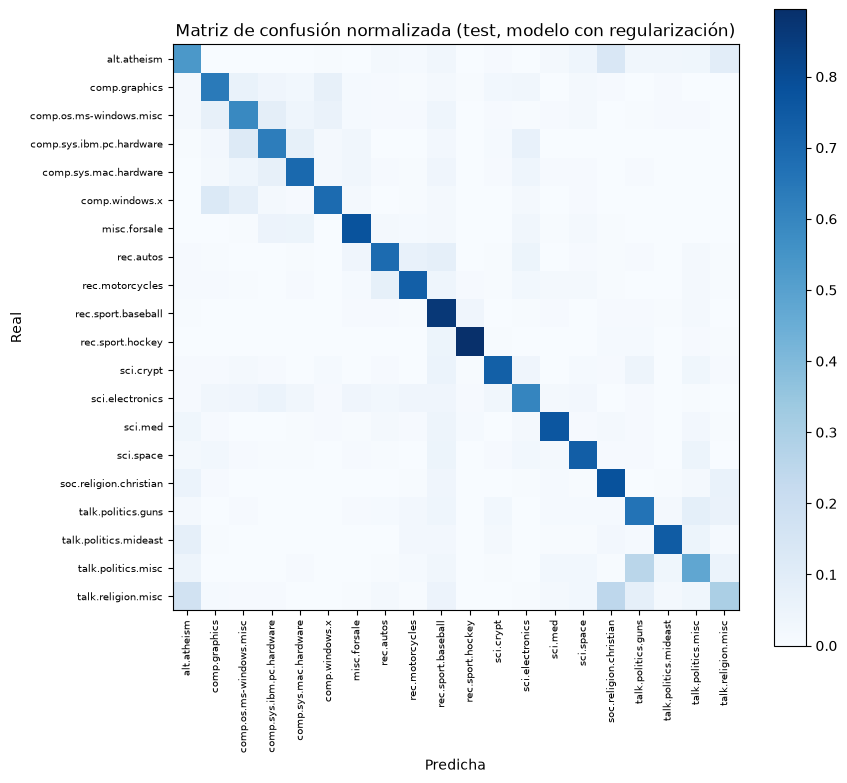

**Confusiones más frecuentes (real → predicha):** `talk.politics.misc` → `talk.politics.guns` (80); `talk.religion.misc` → `soc.religion.christian` (62); `comp.windows.x` → `comp.graphics` (49); `comp.sys.ibm.pc.hardware` → `comp.os.ms-windows.misc` (44); `talk.religion.misc` → `alt.atheism` (43); `alt.atheism` → `soc.religion.christian` (43). Peores clases por F1: `talk.religion.misc` (0.34), `talk.politics.misc` (0.49), `alt.atheism` (0.52); mejores: `rec.sport.hockey` (0.90), `talk.politics.mideast` (0.79).

In [27]:
pred0, y0 = FINAL["con regularización"][0]["preds"], FINAL["con regularización"][0]["y"]
print(classification_report(y0, pred0, target_names=class_names))
cm = confusion_matrix(y0, pred0); cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(9, 8)); im = ax.imshow(cmn, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=90, fontsize=7); ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names, fontsize=7)
ax.set_xlabel("Predicha"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusión normalizada (test, modelo con regularización)"); plt.colorbar(im); plt.tight_layout()
plt.savefig("figures/tp3_confusion.png", dpi=130); plt.show()
off = [(cm[i, j], i, j) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
top = sorted(off, reverse=True)[:6]
f1 = classification_report(y0, pred0, target_names=class_names, output_dict=True)
peor = sorted(class_names, key=lambda c: f1[c]["f1-score"])[:3]; mejor = sorted(class_names, key=lambda c: -f1[c]["f1-score"])[:2]
display(Markdown("**Confusiones más frecuentes (real → predicha):** " + "; ".join(f"`{class_names[i]}` → `{class_names[j]}` ({n})" for n, i, j in top) +
                 f". Peores clases por F1: " + ", ".join(f"`{c}` ({f1[c]['f1-score']:.2f})" for c in peor) + "; mejores: " + ", ".join(f"`{c}` ({f1[c]['f1-score']:.2f})" for c in mejor) + "."))

# 7. Bias / varianza, conclusiones y limitaciones

### Bias y varianza de todas las configuraciones controladas
Siguiendo la regla de entrenamiento de la clase: el **bias** se estima como la distancia entre el techo alcanzable en train y la train acc en modo evaluación (cuánto le falta al modelo para ajustar lo ajustable) y la **varianza** como la brecha `train(eval) − val`.

In [28]:
bv = agg(ALL_ROWS).reset_index().drop_duplicates("label", keep="first").set_index("label")
bv["bias"] = TECHO_TRAIN - bv.train_acc_eval
bv["varianza"] = bv.gap
display(bv[["train_acc_eval", "val_sel", "bias", "varianza", "mean_abs_w"]].round(4).sort_values("val_sel", ascending=False).head(12))
display(Markdown("*(12 mejores por val acc; la tabla completa está en `results/tp3_bias_varianza.csv`)*"))
bv.to_csv("results/tp3_bias_varianza.csv")
refv = a_ref.loc["base (sin regularización)"]
under = bv[(bv.val_sel < refv.val_sel - 3 * SE_VAL)]
under_b = under[under.bias > 0.02]    # el train no llega al techo: underfitting
under_v = under[under.bias <= 0.02]   # el train sí llega al techo: no es underfitting
display(Markdown(
    f"- **Base (sin regularizar):** train(eval) {refv.train_acc_eval:.3f} (techo {TECHO_TRAIN:.3f}, bias {(TECHO_TRAIN - refv.train_acc_eval) * 100:.1f} puntos) y val {refv.val_sel:.3f}: **varianza {refv.gap * 100:.1f} puntos**. "
    + ("Bias bajo y brecha mucho mayor que el error de la validación: **alta varianza**, el escenario donde la regularización tiene sentido (reglas 5–6 de la clase).\n" if (refv.gap > 3 * SE_VAL and TECHO_TRAIN - refv.train_acc_eval < 0.05)
       else "La brecha no supera claramente el error de la validación o el bias no es bajo: **no es un caso claro de alta varianza**, y no se espera que la regularización aporte mucho.\n")
    +
    f"- **Underfitting** (val más de 3 errores estándar por debajo de la base *y* el train no llega al techo: bias > 2 puntos): " + (", ".join(f"{l} (val {r.val_sel:.3f}, bias {r.bias * 100:.1f} pts)" for l, r in under_b.iterrows()) if len(under_b) else "ninguna") + ".\n"
    f"- **Peor generalización con el train ya ajustado** (val más de 3 errores estándar por debajo de la base pero bias ≈ 0: no es underfitting, la red ajusta todo el train y generaliza peor): " + (", ".join(f"{l} (val {r.val_sel:.3f}, brecha {r.varianza * 100:.1f} pts)" for l, r in under_v.iterrows()) if len(under_v) else "ninguna") + ".\n"
    f"- **Menor varianza entre todas las configuraciones:** `{bv.varianza.idxmin()}` con {bv.varianza.min() * 100:.1f} puntos de brecha y val {bv.loc[bv.varianza.idxmin(), 'val_sel']:.3f}."))

,train_acc_eval,val_sel,bias,varianza,mean_abs_w
label,,,,,
dropout 0.35 + plateau (val loss) | lr=1e-3,0.9711,0.7468,0.0023,0.2243,0.0870
dropout 0.35 | lr=1e-3,0.9730,0.7468,0.0003,0.2262,0.0982
L2 λ=1e-6 | lr=3e-3,0.9728,0.7441,0.0006,0.2287,0.0906
dropout 0.35,0.9688,0.7437,0.0045,0.2251,0.1031
L2 λ=1e-6 | lr=1e-3,0.9734,0.7437,0.0000,0.2297,0.0905
sin reg | lr=1e-3,0.9734,0.7437,0.0000,0.2297,0.0993
dropout 0.35 | lr=3e-3,0.9735,0.7433,-0.0001,0.2302,0.1350
dropout 0.35 + plateau (val loss) | lr=3e-3,0.9723,0.7433,0.0011,0.2290,0.1074
1×512 sin reg,0.9735,0.7430,-0.0001,0.2304,0.0727


*(12 mejores por val acc; la tabla completa está en `results/tp3_bias_varianza.csv`)*

- **Base (sin regularizar):** train(eval) 0.973 (techo 0.973, bias 0.1 puntos) y val 0.742: **varianza 23.0 puntos**. Bias bajo y brecha mucho mayor que el error de la validación: **alta varianza**, el escenario donde la regularización tiene sentido (reglas 5–6 de la clase).
- **Underfitting** (val más de 3 errores estándar por debajo de la base *y* el train no llega al techo: bias > 2 puntos): L2 λ=1e-3 (val 0.710, bias 12.8 pts), L1 λ=3e-5 (val 0.704, bias 2.2 pts), L1 λ=1e-4 (val 0.670, bias 16.4 pts).
- **Peor generalización con el train ya ajustado** (val más de 3 errores estándar por debajo de la base pero bias ≈ 0: no es underfitting, la red ajusta todo el train y generaliza peor): BN, bs=128 (val 0.707, brecha 26.7 pts), BN, bs=512 (val 0.686, brecha 28.7 pts), BN, bs=128, momentum 0.01 (≈Keras 0.99) (val 0.661, brecha 31.3 pts), dropout 0.35 | lr=1e-2 (val 0.714, brecha 25.9 pts), BN | lr=3e-4 (val 0.711, brecha 26.2 pts), BN | lr=3e-3 (val 0.712, brecha 25.9 pts), BN | lr=1e-2 (val 0.702, brecha 27.0 pts), dropout 0.35 + plateau (val loss) | lr=1e-2 (val 0.714, brecha 26.0 pts), 2 capas, sin BN (val 0.698, brecha 27.5 pts), 3 capas, sin BN (val 0.617, brecha 35.6 pts), 3 capas, BN (val 0.713, brecha 25.9 pts), BN + dropout 0.35 (val 0.706, brecha 26.6 pts), std, sin reg (val 0.694, brecha 27.9 pts), std, L2 λ=1e-6 (val 0.695, brecha 27.8 pts).
- **Menor varianza entre todas las configuraciones:** `L2 λ=1e-3` con 13.5 puntos de brecha y val 0.710.

In [29]:
S = SUMMARY
def a_favor(d): return "mejora" if d > SE_VAL else ("empeora" if d < -SE_VAL else "no cambia de forma apreciable")
l = []
l.append(f"1. **L2.** El mejor λ₂ fue {sci(S['l2']['lam'])}: la val acc {a_favor(S['l2']['delta'])} ({pts(S['l2']['delta'])} puntos), la media de |w| quedó en {S['l2']['w_ratio']:.0%} de la base y la brecha train−val pasó de {S['l2']['gap_base'] * 100:.1f} a {S['l2']['gap_best'] * 100:.1f} puntos.")
l.append(f"2. **L1.** El mejor λ₁ fue {sci(S['l1']['lam'])}: la val acc {a_favor(S['l1']['delta'])} ({pts(S['l1']['delta'])} puntos) y la fracción de pesos < 1e-3 subió de {S['l1']['frac_base']:.0%} a {S['l1']['frac']:.0%}. "
         f"La poda por umbral de 1e-2 deja {S['l1']['poda'].pesos_en_cero.iloc[2]:.0%} de los pesos en cero y cambia la val acc en {pts(S['l1']['poda'].val_acc.iloc[2] - S['l1']['poda'].val_acc.iloc[0])} puntos.")
l.append(f"3. **L1+L2.** {S['elastic']['val']:.4f} de val acc ({pts(S['elastic']['delta'])} puntos vs la base): {'no aporta algo claramente distinto de usar solo una de las dos' if abs(S['elastic']['delta']) < 2 * SE_VAL else 'cambia el resultado respecto de la base'}.")
l.append(f"4. **Dropout.** El mejor valor fue {S['dropout']['p']}: la val acc {a_favor(S['dropout']['delta'])} ({pts(S['dropout']['delta'])} puntos) y la media de |w| quedó en {S['dropout']['w_ratio']:.0%} de la base.")
l.append(f"5. **BatchNorm.** Con batch 128, la val acc {a_favor(S['bn']['delta'])} ({pts(S['bn']['delta'])} puntos); épocas hasta el 97 % de la val acc base: {en(S['bn']['ep_n'])} sin BN vs {en(S['bn']['ep_y'])} con BN{'; BN acelera la convergencia pero no mejora la generalización' if S['bn']['delta'] < SE_VAL else ''} (el costo en tiempo por época está en 4.11).")
l.append(f"6. **Learning rate.** Mejor lr por variante (Adam): " + "; ".join(f"{k} {v:.0e}" for k, v in S['lr']['best_lr'].items()) + f". ReduceLROnPlateau sobre la loss de validación: redujo el lr en {S['lr']['plateau_fired']} de {S['lr']['plateau_n']} corridas. Ver 4.6 para la sensibilidad a lr alto/bajo de cada técnica.")
l.append(f"7. **Profundidad.** Pasar de 1 a 3 capas cambió la val acc en {pts(S['depth']['loss_no_bn'])} puntos sin BN y {pts(S['depth']['loss_bn'])} con BN.")
l.append(f"8. **Dropout × BN.** Efecto de combinar ambos: {pts(S['inter']['both'])} puntos vs la base; sumando los efectos por separado se esperaría {pts(S['inter']['additive'])}.")
l.append(f"9. **Escalado de features.** `std` vs `tfidf`: {pts(S['scale']['d_noreg'])} puntos sin regularizar y {pts(S['scale']['d_l2'])} con L2.")
l.append(f"10. **Regularización como hiperparámetro de la búsqueda.** Con igual presupuesto ({N_TRIALS} trials), la mejor val acc fue {pts(S['budget']['dbest'])} puntos respecto de la búsqueda sin regularización ({veredicto(S['budget']['dbest'])}).")
l.append(f"11. **Test (5 semillas).** Diferencia con − sin regularización: {pts(S['final']['dm'])} puntos (McNemar semilla 0: p = {S['final']['p']:.3f}, {'significativa' if S['final']['p'] < 0.05 else 'no significativa'} al 5 %).")
best_d = max(S['l2']['delta'], S['l1']['delta'], S['dropout']['delta'], S['elastic']['delta'])
l.append("12. **Lectura global.** " + (f"Ninguna técnica (L2, L1, L1+L2, dropout) mejoró la val acc por más del error estándar respecto de la base (la mejor diferencia fue {pts(best_d)} puntos), aunque la base tiene el train en su techo y una brecha train−val de {S['l2']['gap_base'] * 100:.1f} puntos. "
    "Cuando la brecha baja con λ grandes es porque cae la train acc (underfitting), sin que suba la val acc. Por lo tanto la brecha no se corrige con regularización en este problema; no se midió un techo de validación, así que una parte puede ser irreducible (solapamiento entre temas)."
    if best_d <= SE_VAL else f"Alguna técnica mejora la val acc por más del error estándar (mejor diferencia {pts(best_d)} puntos): ver las secciones 4.1–4.4."))
if "time" in S:
    l.append("13. **Costo en tiempo (4.11, variantes intercaladas).** " + S["time"]["resumen"])
display(Markdown("### Conclusiones (generadas desde los resultados de este notebook)\n\n" + "\n".join(l)))

### Conclusiones (generadas desde los resultados de este notebook)

1. **L2.** El mejor λ₂ fue 1e-6: la val acc no cambia de forma apreciable (-0.2 puntos), la media de |w| quedó en 67% de la base y la brecha train−val pasó de 23.0 a 23.2 puntos.
2. **L1.** El mejor λ₁ fue 1e-6: la val acc no cambia de forma apreciable (-0.6 puntos) y la fracción de pesos < 1e-3 subió de 0% a 30%. La poda por umbral de 1e-2 deja 52% de los pesos en cero y cambia la val acc en +0.0 puntos.
3. **L1+L2.** 0.7371 de val acc (-0.5 puntos vs la base): no aporta algo claramente distinto de usar solo una de las dos.
4. **Dropout.** El mejor valor fue 0.35: la val acc no cambia de forma apreciable (+0.1 puntos) y la media de |w| quedó en 81% de la base.
5. **BatchNorm.** Con batch 128, la val acc empeora (-3.6 puntos); épocas hasta el 97 % de la val acc base: 4.0 sin BN vs 1.0 con BN; BN acelera la convergencia pero no mejora la generalización (el costo en tiempo por época está en 4.11).
6. **Learning rate.** Mejor lr por variante (Adam): sin reg 1e-03; L2 λ=1e-6 3e-03; dropout 0.35 1e-03; BN 1e-03; dropout 0.35 + plateau (val loss) 1e-03. ReduceLROnPlateau sobre la loss de validación: redujo el lr en 3 de 4 corridas. Ver 4.6 para la sensibilidad a lr alto/bajo de cada técnica.
7. **Profundidad.** Pasar de 1 a 3 capas cambió la val acc en -12.5 puntos sin BN y -1.0 con BN.
8. **Dropout × BN.** Efecto de combinar ambos: -3.6 puntos vs la base; sumando los efectos por separado se esperaría -1.8.
9. **Escalado de features.** `std` vs `tfidf`: -4.8 puntos sin regularizar y -4.6 con L2.
10. **Regularización como hiperparámetro de la búsqueda.** Con igual presupuesto (30 trials), la mejor val acc fue +0.4 puntos respecto de la búsqueda sin regularización (diferencia dentro del error de la validación).
11. **Test (5 semillas).** Diferencia con − sin regularización: +1.0 puntos (McNemar semilla 0: p = 0.066, no significativa al 5 %).
12. **Lectura global.** Ninguna técnica (L2, L1, L1+L2, dropout) mejoró la val acc por más del error estándar respecto de la base (la mejor diferencia fue +0.1 puntos), aunque la base tiene el train en su techo y una brecha train−val de 23.0 puntos. Cuando la brecha baja con λ grandes es porque cae la train acc (underfitting), sin que suba la val acc. Por lo tanto la brecha no se corrige con regularización en este problema; no se midió un techo de validación, así que una parte puede ser irreducible (solapamiento entre temas).
13. **Costo en tiempo (4.11, variantes intercaladas).** L2 λ=1e-6 +47 % (mínimo +31 %); L1 λ=1e-6 +18 % (mínimo +20 %); L1+L2 +57 % (mínimo +61 %); dropout 0.35 +2 % (mínimo +4 %), dentro del ruido; BN +5 % (mínimo +7 %), dentro del ruido; max-norm c=4 +9 % (mínimo +10 %), dentro del ruido; 1×512 + L2 λ=1e-6 +68 % (mínimo +57 %); 1×512 + dropout 0.35 +9 % (mínimo +2 %), dentro del ruido. Referencias: base 8.6 ms/paso (≈2.4 s por época), 1×512 base 48.9 ms/paso.

### Cómo se justifican los fenómenos observados con lo visto en clase

- **Pesos y overfitting (L1/L2).** La clase muestra que el overfitting va con pesos de valor absoluto alto y que penalizarlos reduce la varianza a costa de algo de bias (MAP vs MLE). Se verifica con la media/máximo de |w|, la brecha train−val y el colapso a λ grande (4.1 y 4.2). La esparsidad de L1 y que la poda por umbral no cambia el resultado (4.2) corresponden a la penalización lineal que reduce todos los pesos por igual.
- **Ruido en las curvas.** La clase observa curvas más ruidosas con L2 grande, con dropout y con BN (y menos ruido a mayor batch). Cada sección reporta el ruido medido (`noise_val_loss`, `noise_val_acc`, `noise_train_acc`) y dice si aparece o no. Los mecanismos que lo explican: en dropout cada paso evalúa una subred distinta (por eso la train acc en modo entrenamiento es la más ruidosa); en BN media y varianza se calculan por mini-batch; en L2 alto el término de penalización domina el gradiente.
- **Tiempos.** Mecanismos: L1/L2 explícitos recorren todos los pesos en cada paso; dropout y BN agregan operaciones por capa; BN es además la técnica de la clase que busca **acelerar** el entrenamiento. Los segundos por época de las corridas controladas tienen ruido de máquina y son solo orientativos; el costo por técnica se mide en 4.11 (pasos de entrenamiento intercalados, mediana de repeticiones). Las épocas hasta el 97 % de la val acc base sí son comparables y están en cada sección.
- **Learning rate.** La clase recomienda lr mayor con dropout (con decay y momentum) y ve a BN como una forma de estabilizar el entrenamiento; se contrasta en 4.6 con un barrido por variante.
- **Escala de las entradas.** λ es el mismo para todos los pesos, por eso la escala de las features importa (4.9).
- **BN con dropout.** La clase indica que no suelen combinarse; se midió el diseño 2×2 (4.8) y la búsqueda de Optuna los combina libremente, así que se compara qué eligieron los mejores trials.

### Limitaciones
- **Error de la validación (±0.9 puntos)** es de orden similar a casi todas las diferencias entre técnicas; solo se interpretan las que lo superan, y el promedio de 2 semillas no lo reduce (mismo conjunto de validación).
- **Un solo split de validación** y **15 épocas**: las técnicas de regularización suelen necesitar más épocas; la comparación a épocas fijas puede subestimarlas (se estudió la época de mínima val loss en la sección 6, no la de cada experimento controlado).
- La **búsqueda de Optuna** concentra los trials en la zona buena y el espacio con regularización tiene más dimensiones; por eso las comparaciones entre técnicas se hacen en los experimentos controlados y no con los trials de la búsqueda.
- Los experimentos controlados **parten de una sola configuración base** (la mejor de la búsqueda sin su regularización) y un solo factor por vez; las interacciones solo se miden en 4.7–4.10.
- El barrido de **learning rate** usa Adam y **una semilla** por punto.
- **Tiempos**: medidos en CPU (o la máquina donde se ejecute), son relativos; no incluyen vectorización. Los segundos por época de las secciones 4.1–4.10 son ruidosos; para el costo por técnica se usa 4.11.
- **Max-norm** se probó solo junto a dropout y como técnica sola; no está en el espacio de Optuna (la consigna pedía L1/L2, dropout y BN).
- Los números de **referencia del TP2** son de una corrida anterior y se usan solo como contexto.

### Anexo: herramientas de registro y qué hace cada bloque

- **Optuna** (`tp3_study.db`): `make_objective` define el espacio y entrena un trial; `run_study` lo ejecuta hasta completar `N_TRIALS` (idempotente) y `get_study` marca como `FAIL` los trials que quedaron en `RUNNING` por una interrupción. El `MedianPruner` corta los trials que van peor que la mediana a partir de la época 4.
- **TensorBoard** (`runs/tp3/`): una carpeta por trial (loss, accuracy y media de |w| por época), por corrida controlada y por entrenamiento final. Se abre con `tensorboard --logdir runs/tp3`.
- **MLflow** (`mlflow.db`): experimento `TP3_busqueda` (un run por estudio con un run anidado por trial: parámetros, val acc por época, pesos, ruido y tiempos), `TP3_controlados` (cada corrida controlada y cada entrenamiento final, con parámetros y métricas por época). Se abre con `mlflow ui --backend-store-uri sqlite:///mlflow.db`.
- **`results/tp3_corridas.jsonl`**: caché de las corridas controladas (permite retomar sin repetir). **`figures/`**: gráficos de cada experimento. **`results/`**: tablas finales en CSV.